In [ ]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from collections import Counter
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from scipy.stats import skew, kurtosis
from sklearn.model_selection import train_test_split
import joblib
import pickle
import torch
import json




In [ ]:
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 100)

### Mount Google Drive

Run the cell below to mount your Google Drive. You will be prompted to authorize access.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### List Files in Google Drive

Once authorized, you can run this cell to see the files and folders available in your main Drive folder (`My Drive`).

In [ ]:
drive_path = '/content/drive/My Drive'
if os.path.exists(drive_path):
    print("Files and folders in your Google Drive:")
    display(os.listdir(drive_path))
else:
    print("Drive is not mounted yet. Please run the mount cell above.")

Files and folders in your Google Drive:


['meta_Amazon_Fashion.jsonl',
 'Colab Notebooks',
 'Datasets-20260512T004847Z-3-003.zip',
 'Datasets-20260512T004847Z-3-001.zip',
 'Datasets-20260512T004847Z-3-004.zip',
 'fmnist_X_train.npy',
 'fmnist_X_val.npy',
 'fmnist_X_test.npy',
 'amazon_fashion_cleaned.csv',
 'amazon_fashion_user_features.csv',
 'amazon_fashion_item_features.csv',
 'fmnist_scaler_std.pkl',
 'fmnist_pca50.pkl',
 'fmnist_y_test.npy',
 'fmnist_X_pca50_test.npy',
 'fmnist_y_val.npy',
 'fmnist_y_train.npy',
 'fmnist_image_features.csv',
 'fmnist_X_pca50_train.npy',
 'fmnist_scaler_mm.pkl',
 'fmnist_eda_stats_v2.json',
 'amazon_fashion_scaler_mm.pkl',
 'eda_amazon_stats_v2.json',
 'amazon_fashion_scaler_std.pkl',
 'taobao_user_features.csv',
 'taobao_item_features.csv',
 'taobao_scaler_std.pkl',
 'taobao_scaler_mm.pkl',
 'taobao_label_encoder_bt.pkl',
 'taobao_eda_stats_v2.json',
 'H&M Datasets']

### Load Dataset from Google Drive

Change the `file_name` variable below to load any specific dataset from your Drive into a pandas DataFrame.

In [ ]:
# Loading H&M articles dataset from the google drive
file_name = 'H&M Datasets/articles.csv'
file_path = os.path.join('/content/drive/My Drive', file_name)

try:
    # Load the dataset
    articles_df = pd.read_csv(file_path)
    print(f"Successfully loaded {file_name}!")
    print(f"Dataset Shape: {df.shape}")
    display(df.head())
except Exception as e:
    print(f"Error loading file: {e}")

Successfully loaded H&M Datasets/articles.csv!
Error loading file: name 'df' is not defined


The H&M articles dataset has 105542 records and 25 attributes

# Exploratory Data Analysis of articles data

# Data Cleaning

In [ ]:
# Identify and handle Missing values
articles_df.isnull().sum()

,0
article_id,0
product_code,0
prod_name,0
product_type_no,0
product_type_name,0
product_group_name,0
graphical_appearance_no,0
graphical_appearance_name,0
colour_group_code,0
colour_group_name,0


detail_desc has 416 missing value out of 105542 thus 0.04%. We impute them with the string "No Description"

In [ ]:
articles_df['detail_desc'].fillna('No Description', inplace=True)

/tmp/ipykernel_1645/1161949699.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  articles_df['detail_desc'].fillna('No Description', inplace=True)


In [ ]:
articles_df.isnull().sum()

,0
article_id,0
product_code,0
prod_name,0
product_type_no,0
product_type_name,0
product_group_name,0
graphical_appearance_no,0
graphical_appearance_name,0
colour_group_code,0
colour_group_name,0


# Validate data types for each columns

In [ ]:
articles_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105542 entries, 0 to 105541
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   article_id                    105542 non-null  int64 
 1   product_code                  105542 non-null  int64 
 2   prod_name                     105542 non-null  object
 3   product_type_no               105542 non-null  int64 
 4   product_type_name             105542 non-null  object
 5   product_group_name            105542 non-null  object
 6   graphical_appearance_no       105542 non-null  int64 
 7   graphical_appearance_name     105542 non-null  object
 8   colour_group_code             105542 non-null  int64 
 9   colour_group_name             105542 non-null  object
 10  perceived_colour_value_id     105542 non-null  int64 
 11  perceived_colour_value_name   105542 non-null  object
 12  perceived_colour_master_id    105542 non-null  int64 
 13 

In [ ]:
print(articles_df.dtypes)

article_id                       int64
product_code                     int64
prod_name                       object
product_type_no                  int64
product_type_name               object
product_group_name              object
graphical_appearance_no          int64
graphical_appearance_name       object
colour_group_code                int64
colour_group_name               object
perceived_colour_value_id        int64
perceived_colour_value_name     object
perceived_colour_master_id       int64
perceived_colour_master_name    object
department_no                    int64
department_name                 object
index_code                      object
index_name                      object
index_group_no                   int64
index_group_name                object
section_no                       int64
section_name                    object
garment_group_no                 int64
garment_group_name              object
detail_desc                     object
dtype: object


The articles data contains numerical values (int64) and string object (str)

In [ ]:
# Ensure numeric values are free of non-numeric entries
articles_df['article_id'] = pd.to_numeric(articles_df['article_id'], errors='coerce')
articles_df.head()

,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,4,Dark,5,Black,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,3,Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,1,Dusty Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,4,Dark,5,Black,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,3,Light,9,White,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [ ]:
# Convert Categorical variables to appropriate type
articles_df['prod_name'] = articles_df['prod_name'].astype('category')
articles_df.head()

,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,4,Dark,5,Black,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,3,Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,1,Dusty Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,4,Dark,5,Black,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,3,Light,9,White,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [ ]:
articles_df["prod_name"].unique()

['Strap top', 'Strap top (1)', 'OP T-shirt (Idro)', '20 den 1p Stockings', 'Shape Up 30 den 1p Tights', ..., '5pk regular Placement1', 'SPORT Malaga tank', 'Cartwheel dress', 'CLAIRE HAIR CLAW', 'Lounge dress']
Length: 45875
Categories (45875, object): ['& Denim Boyfriend LW denim', '& Denim Jen bermuda shorts',
                             '&DENIM Bootcut RW Speed', '&DENIM Bootcut RW soho', ...,
                             'x-size Benny pull-on shorts', 'zelda leggings', 'zimmer dress', 'Åsa Dress']

In [ ]:
# Column group
ID_COLS  = ["article_id", "product_code"]
NUM_CODE_COLS = [
    "product_type_no", "graphical_appearance_no", "colour_group_code",
    "perceived_colour_value_id", "perceived_colour_master_id",
    "department_no", "index_group_no", "section_no", "garment_group_no"
]
CAT_COLS = [
    "product_type_name", "product_group_name", "graphical_appearance_name",
    "colour_group_name", "perceived_colour_value_name",
    "perceived_colour_master_name", "department_name",
    "index_code", "index_name", "index_group_name",
    "section_name", "garment_group_name"
]
TEXT_COL = "detail_desc"

In [ ]:
#Data types audit
dtype_map = {}
for c in articles_df.columns:
    if c in ID_COLS:           dtype_map[c] = "Identifier"
    elif c in NUM_CODE_COLS:   dtype_map[c] = "Numeric Code"
    elif c in CAT_COLS:        dtype_map[c] = "Categorical"
    elif c == TEXT_COL:        dtype_map[c] = "Free Text"
    elif c == "prod_name":     dtype_map[c] = "Name/Text"
    else:                      dtype_map[c] = "Other"

type_counts = Counter(dtype_map.values())

# Outliers detection

In [ ]:
# Outliers detection using IQR on numerical columns
outlier_results = {}
for c in NUM_CODE_COLS:
    s = articles_df[c].dropna()
    Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n_out = ((s < lower) | (s > upper)).sum()
    outlier_results[c] = {"Q1": Q1, "Q3": Q3, "lower": lower, "upper": upper, "n_outliers": n_out}

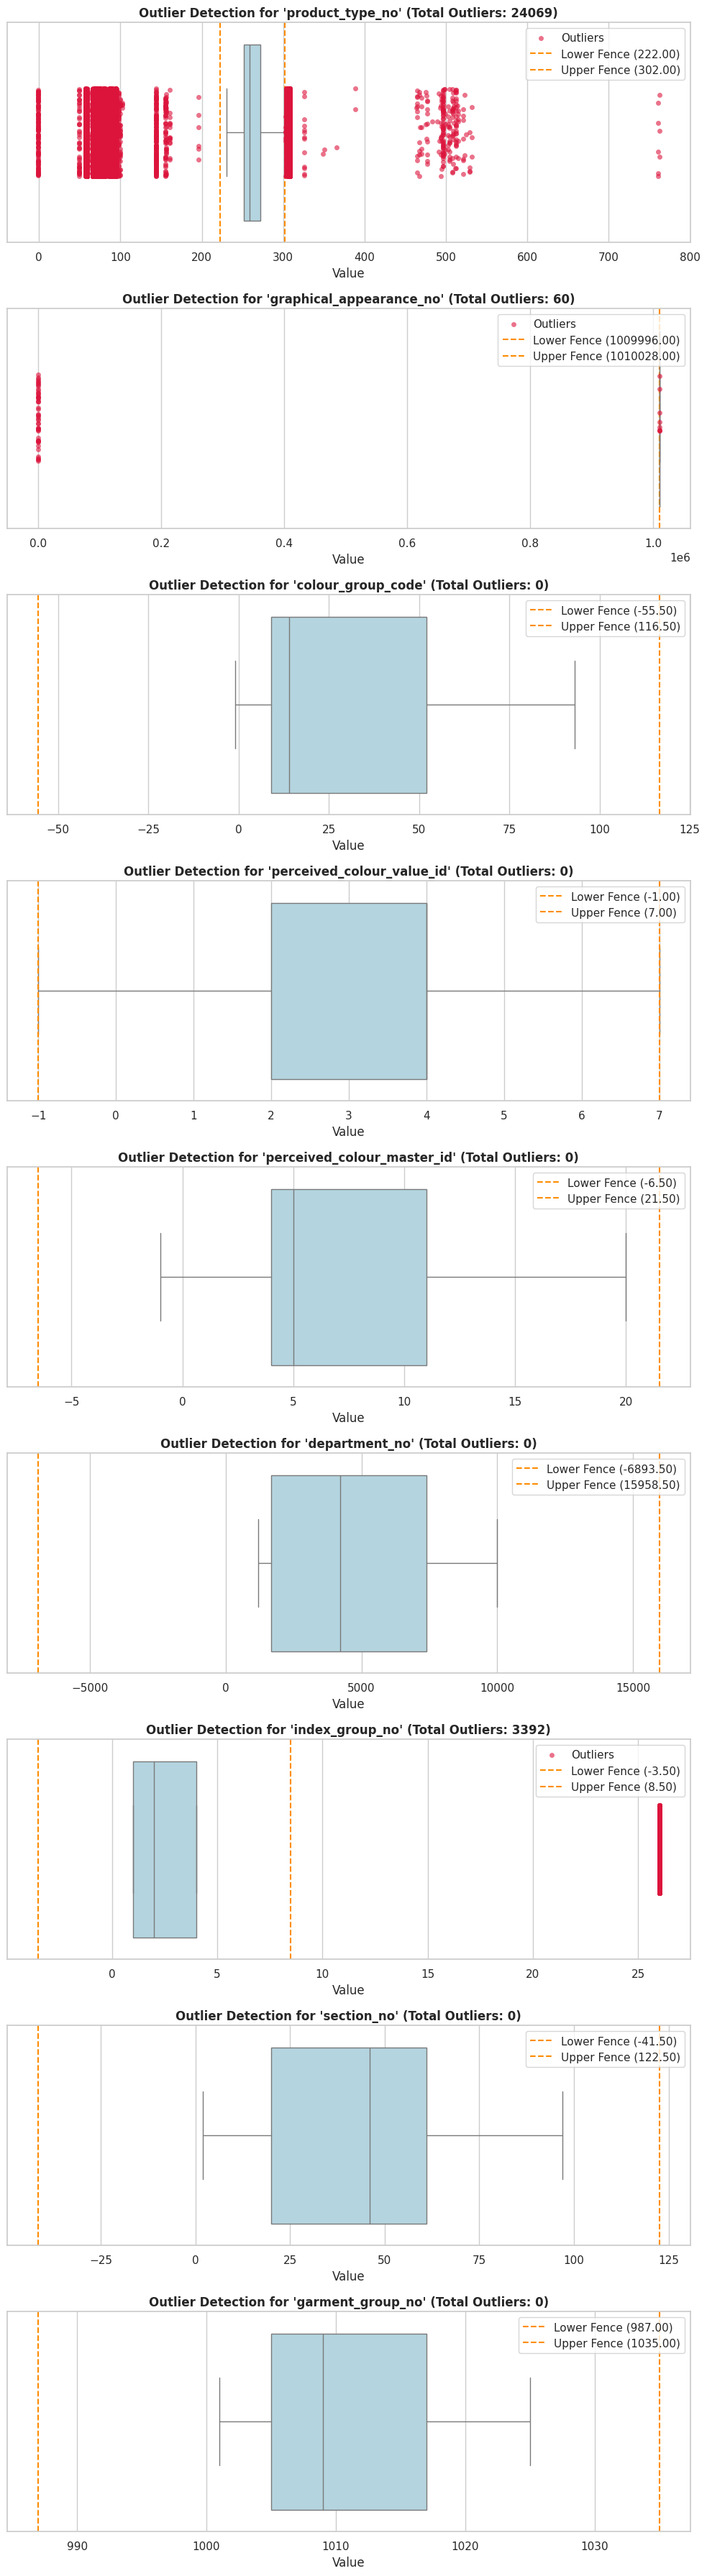

In [ ]:
# Configure the plotting grid based on the number of numeric columns
num_cols = len(NUM_CODE_COLS)
fig, axes = plt.subplots(nrows=num_cols, ncols=1, figsize=(10, 4 * num_cols), sharex=False)

# Ensure axes is iterable even if there is only 1 column
if num_cols == 1:
    axes = [axes]

for i, c in enumerate(NUM_CODE_COLS):
    ax = axes[i]
    res = outlier_results[c]
    s = articles_df[c].dropna()

    # 1. Draw the base distribution boxplot
    sns.boxplot(x=s, ax=ax, color='lightblue', fliersize=0)  # Hide default fliers to avoid duplication

    # 2. Overlay individual outlier points for visual clarity
    outliers = s[(s < res["lower"]) | (s > res["upper"])]
    sns.stripplot(x=outliers, ax=ax, color='crimson', alpha=0.6, jitter=0.2, size=5, label='Outliers')

    # 3. Draw vertical boundary lines for the IQR fences
    ax.axvline(res["lower"], color='darkorange', linestyle='--', linewidth=1.5, label=f'Lower Fence ({res["lower"]:.2f})')
    ax.axvline(res["upper"], color='darkorange', linestyle='--', linewidth=1.5, label=f'Upper Fence ({res["upper"]:.2f})')

    # Chart styling and meta info
    ax.set_title(f"Outlier Detection for '{c}' (Total Outliers: {res['n_outliers']})", fontsize=12, fontweight='bold')
    ax.set_xlabel("Value")

    # Handle duplicate labels in legend mapping
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc='upper right')

plt.tight_layout()
plt.show()

The IQR fence rule flagged 27521 observations across the columns as outliers

### Handling Outliers for H&M Articles

Since the numerical columns in this dataset (like `product_type_no`, `colour_group_code`, `department_no`, etc.) represent **categorical codes and IDs** rather than continuous numerical measurements, traditional outlier detection (such as the IQR rule) flags valid but less frequent categories.

**Action Plan:**
- **Do not drop or transform** these flagged observations, as they represent valid product categories, departments, or styles.
- Treat these numerical codes as **categorical features** (using target encoding, embeddings, or string-based category columns like `product_type_name`).
- If needed for machine learning, you can bin rare categories (low-frequency codes) into an `'Other'` group to reduce cardinality.

### Frequency Encoding & Rare Category Grouping

For columns in `NUM_CODE_COLS` that contain rare categories (e.g., categories representing less than 1% of the total dataset), we can group them together under a common label (like `-1` or a dedicated `'Other'` code) to prevent high cardinality issues during modeling.

In [ ]:
# Define rare category threshold (e.g., 1% of the dataset)
threshold = 0.01 * len(articles_df)

# Create a copy of the dataframe to perform encoding
encoded_articles_df = articles_df.copy()

for col in NUM_CODE_COLS:
    # Calculate category counts
    counts = encoded_articles_df[col].value_counts()

    # Identify rare categories
    rare_categories = counts[counts < threshold].index

    if len(rare_categories) > 0:
        # Group rare categories under -1 (common placeholder for rare/unknown values)
        encoded_articles_df[col] = encoded_articles_df[col].apply(lambda x: -1 if x in rare_categories else x)
        print(f"Column '{col}': Grouped {len(rare_categories)} rare categories into -1.")

# Show the updated summary
print("\nUpdated distinct values per code column:")
display(encoded_articles_df[NUM_CODE_COLS].nunique())

Column 'product_type_no': Grouped 106 rare categories into -1.
Column 'graphical_appearance_no': Grouped 16 rare categories into -1.
Column 'colour_group_code': Grouped 28 rare categories into -1.
Column 'perceived_colour_value_id': Grouped 2 rare categories into -1.
Column 'perceived_colour_master_id': Grouped 4 rare categories into -1.
Column 'department_no': Grouped 281 rare categories into -1.
Column 'section_no': Grouped 19 rare categories into -1.
Column 'garment_group_no': Grouped 1 rare categories into -1.

Updated distinct values per code column:


,0
product_type_no,27
graphical_appearance_no,15
colour_group_code,23
perceived_colour_value_id,7
perceived_colour_master_id,17
department_no,19
index_group_no,5
section_no,39
garment_group_no,21


### Apply Frequency Encoding

Now, we map each value in the categorical code columns to its normalized frequency (its proportion in the dataset) to create continuous, model-ready features.

In [ ]:
# Calculate and map frequencies for each categorical code column
for col in NUM_CODE_COLS:
    freq_map = encoded_articles_df[col].value_counts(normalize=True).to_dict()
    encoded_articles_df[f'{col}_freq'] = encoded_articles_df[col].map(freq_map)

# Display the new frequency columns alongside their original codes
freq_cols = [f'{col}_freq' for col in NUM_CODE_COLS]
display(encoded_articles_df[NUM_CODE_COLS + freq_cols].head())

,product_type_no,graphical_appearance_no,colour_group_code,perceived_colour_value_id,perceived_colour_master_id,department_no,index_group_no,section_no,garment_group_no,product_type_no_freq,graphical_appearance_no_freq,colour_group_code_freq,perceived_colour_value_id_freq,perceived_colour_master_id_freq,department_no_freq,index_group_no_freq,section_no_freq,garment_group_no_freq
0,253,1010016,9,4,5,1676,1,16,1002,0.028339,0.471348,0.214796,0.404635,0.213991,0.012876,0.376504,0.014980,0.076993
1,253,1010016,10,3,9,1676,1,16,1002,0.028339,0.471348,0.090410,0.149125,0.120000,0.012876,0.376504,0.014980,0.076993
2,253,1010017,11,1,9,1676,1,16,1002,0.028339,0.047280,0.025829,0.209888,0.120000,0.012876,0.376504,0.014980,0.076993
3,306,1010016,9,4,5,-1,1,61,1017,0.020958,0.471348,0.214796,0.404635,0.213991,0.761583,0.376504,0.034091,0.070503
4,306,1010016,10,3,9,-1,1,61,1017,0.020958,0.471348,0.090410,0.149125,0.120000,0.761583,0.376504,0.034091,0.070503


# Check for duplicate rows

In [ ]:
# Check for duplicate rows in the dataset
duplicates_count = articles_df.duplicated().sum()
print(f"Number of exact duplicate rows: {duplicates_count}")

# If duplicates exist, show a sample of them
if duplicates_count > 0:
    display(articles_df[articles_df.duplicated(keep=False)].head())

Number of exact duplicate rows: 0


There is no duplicated records in the articles dataset

In [ ]:
# Standardize column names
articles_df.columns = [col.lower().replace(' ', '_') for col in articles_df.columns]


In [ ]:
# Check for inconsistent category
articles_df.nunique()

,0
article_id,105542
product_code,47224
prod_name,45875
product_type_no,132
product_type_name,131
product_group_name,19
graphical_appearance_no,30
graphical_appearance_name,30
colour_group_code,50
colour_group_name,50


### Checking for Inconsistent Categories

We will check for potential spelling variations, leading/trailing spaces, or capitalization issues by comparing unique values in the string columns after converting them to lowercase and stripping whitespace.

In [ ]:
# Check for potential string variations (e.g. 'Red' vs 'red' vs '  Red ')
for col in CAT_COLS:
    raw_unique = set(articles_df[col].dropna().unique())
    clean_unique = set(articles_df[col].dropna().astype(str).str.strip().str.lower().unique())

    diff_count = len(raw_unique) - len(clean_unique)
    if diff_count > 0:
        print(f"⚠️ Column '{col}' has {diff_count} capitalization or whitespace inconsistencies!")
        # Find examples
        example_duplicates = {}
        for val in raw_unique:
            cleaned = val.strip().lower()
            if cleaned not in example_duplicates:
                example_duplicates[cleaned] = []
            example_duplicates[cleaned].append(val)

        # Print examples with multiple forms
        for k, v in example_duplicates.items():
            if len(v) > 1:
                print(f"   - Variations found: {v}")
    else:
        print(f"✅ Column '{col}' has no capitalization or whitespace inconsistencies.")

⚠️ Column 'product_type_name' has 1 capitalization or whitespace inconsistencies!
   - Variations found: ['Dog Wear', 'Dog wear']
✅ Column 'product_group_name' has no capitalization or whitespace inconsistencies.
✅ Column 'graphical_appearance_name' has no capitalization or whitespace inconsistencies.
✅ Column 'colour_group_name' has no capitalization or whitespace inconsistencies.
✅ Column 'perceived_colour_value_name' has no capitalization or whitespace inconsistencies.
✅ Column 'perceived_colour_master_name' has no capitalization or whitespace inconsistencies.
⚠️ Column 'department_name' has 2 capitalization or whitespace inconsistencies!
   - Variations found: ['Denim Trousers', 'Denim trousers']
   - Variations found: ['Jersey Fancy', 'Jersey fancy']
✅ Column 'index_code' has no capitalization or whitespace inconsistencies.
✅ Column 'index_name' has no capitalization or whitespace inconsistencies.
✅ Column 'index_group_name' has no capitalization or whitespace inconsistencies.
✅ C

### Fixing Categorical Text Inconsistencies

We will standardize the text values in our categorical columns by converting them to title-case (or clean spacing) so that duplicates like `'Dog wear'` and `'Dog Wear'` are treated as a single uniform category.

In [ ]:
# Clean categorical text inconsistencies by standardizing casing
for col in CAT_COLS:
    if col in articles_df.columns:
        # Convert to string, strip whitespaces, and convert to standard Title Case
        articles_df[col] = articles_df[col].astype(str).str.strip().str.title()

# Re-run the verification logic to confirm standardisation worked successfully
all_clean = True
for col in CAT_COLS:
    raw_unique = set(articles_df[col].dropna().unique())
    clean_unique = set(articles_df[col].dropna().astype(str).str.strip().str.lower().unique())

    diff_count = len(raw_unique) - len(clean_unique)
    if diff_count > 0:
        print(f"⚠️ Column '{col}' still has {diff_count} inconsistencies!")
        all_clean = False

if all_clean:
    print("✅ All categorical text inconsistencies have been resolved successfully!")

# Display unique counts to observe the updated values
articles_df[CAT_COLS].nunique()

✅ All categorical text inconsistencies have been resolved successfully!


,0
product_type_name,130
product_group_name,19
graphical_appearance_name,30
colour_group_name,50
perceived_colour_value_name,8
perceived_colour_master_name,20
department_name,248
index_code,10
index_name,10
index_group_name,5


# Descriptive Statistics

In [ ]:
# Generate Summary statistics for numeric variables (mean, median, std, min, and max)
articles_df[NUM_CODE_COLS].describe()

,product_type_no,graphical_appearance_no,colour_group_code,perceived_colour_value_id,perceived_colour_master_id,department_no,index_group_no,section_no,garment_group_no
count,105542.000000,1.055420e+05,105542.000000,105542.000000,105542.000000,105542.000000,105542.000000,105542.000000,105542.000000
mean,234.861875,1.009515e+06,32.233822,3.206183,7.807972,4532.777833,3.171534,42.664219,1010.438290
std,75.049308,2.241359e+04,28.086154,1.563839,5.376727,2712.692011,4.353234,23.260105,6.731023
min,-1.000000,-1.000000e+00,-1.000000,-1.000000,-1.000000,1201.000000,1.000000,2.000000,1001.000000
25%,252.000000,1.010008e+06,9.000000,2.000000,4.000000,1676.000000,1.000000,20.000000,1005.000000
50%,259.000000,1.010016e+06,14.000000,4.000000,5.000000,4222.000000,2.000000,46.000000,1009.000000
75%,272.000000,1.010016e+06,52.000000,4.000000,11.000000,7389.000000,4.000000,61.000000,1017.000000
max,762.000000,1.010029e+06,93.000000,7.000000,20.000000,9989.000000,26.000000,97.000000,1025.000000


In [ ]:
# Generate frequency tables for categorical variables
articles_df[CAT_COLS].describe()

,product_type_name,product_group_name,graphical_appearance_name,colour_group_name,perceived_colour_value_name,perceived_colour_master_name,department_name,index_code,index_name,index_group_name,section_name,garment_group_name
count,105542,105542,105542,105542,105542,105542,105542,105542,105542,105542,105542,105542
unique,130,19,30,50,8,20,248,10,10,5,56,21
top,Trousers,Garment Upper Body,Solid,Black,Dark,Black,Jersey,A,Ladieswear,Ladieswear,Womens Everyday Collection,Jersey Fancy
freq,11169,42741,49747,22670,42706,22585,4604,26001,26001,39737,7295,21445


In [ ]:
# Assess distribution shape with skewness and kurtosis for numeric variables
articles_df[NUM_CODE_COLS].skew()

,0
product_type_no,-1.423031
graphical_appearance_no,-45.019012
colour_group_code,0.713823
perceived_colour_value_id,0.273999
perceived_colour_master_id,0.801380
department_no,0.271354
index_group_no,4.587590
section_no,-0.084535
garment_group_no,0.318752


### Plotting Skewness and Kurtosis of Numeric Variables

We will calculate both skewness (which measures distribution asymmetry) and kurtosis (which measures the heaviness of the distribution tails) for the numerical columns, and visualize them using side-by-side bar plots.

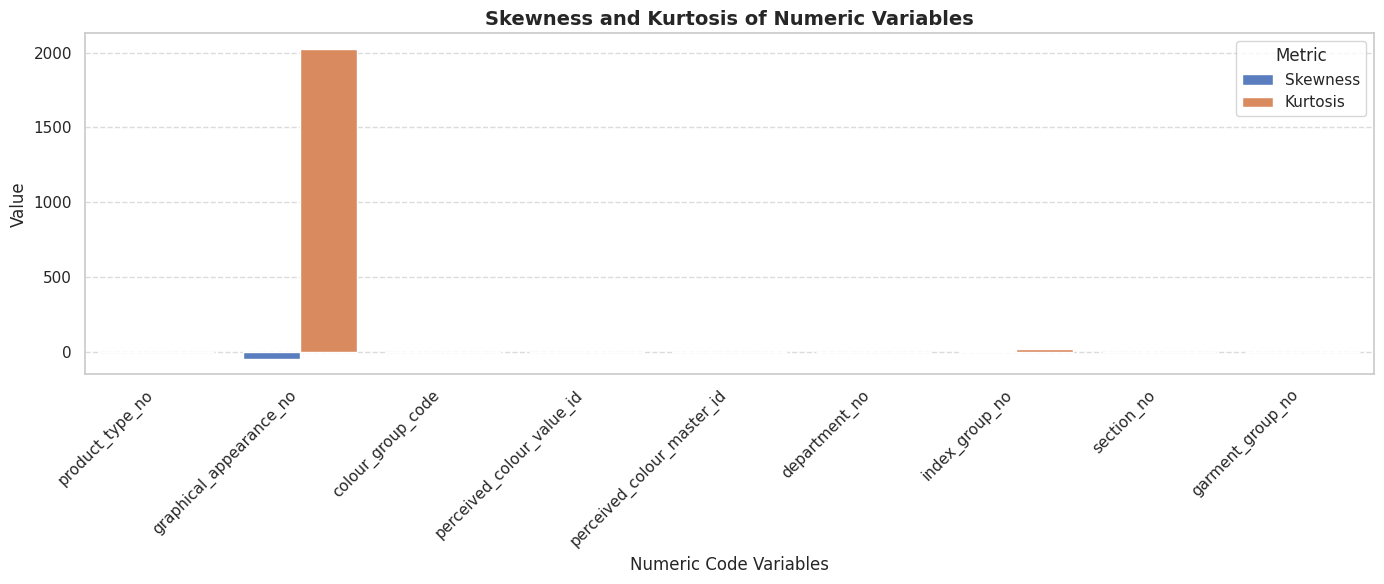

In [ ]:
# Calculate skewness and kurtosis
skew_vals = articles_df[NUM_CODE_COLS].skew()
kurt_vals = articles_df[NUM_CODE_COLS].kurt()

# Combine into a single DataFrame for plotting
shape_df = pd.DataFrame({
    'Skewness': skew_vals,
    'Kurtosis': kurt_vals
}).reset_index().rename(columns={'index': 'Variable'})

# Melt the DataFrame to long format for easier plotting with Seaborn
shape_melted = shape_df.melt(id_vars='Variable', var_name='Metric', value_name='Value')

# Create a side-by-side bar plot
plt.figure(figsize=(14, 6))
sns.barplot(x='Variable', y='Value', hue='Metric', data=shape_melted, palette='muted')

plt.title('Skewness and Kurtosis of Numeric Variables', fontsize=14, fontweight='bold')
plt.xlabel('Numeric Code Variables', fontsize=12)
plt.ylabel('Value', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Visualizing the Distributions of Skewness and Kurtosis

To see how the skewness and kurtosis values themselves are distributed across our set of numeric variables, we can plot their histograms with Kernel Density Estimates (KDE).

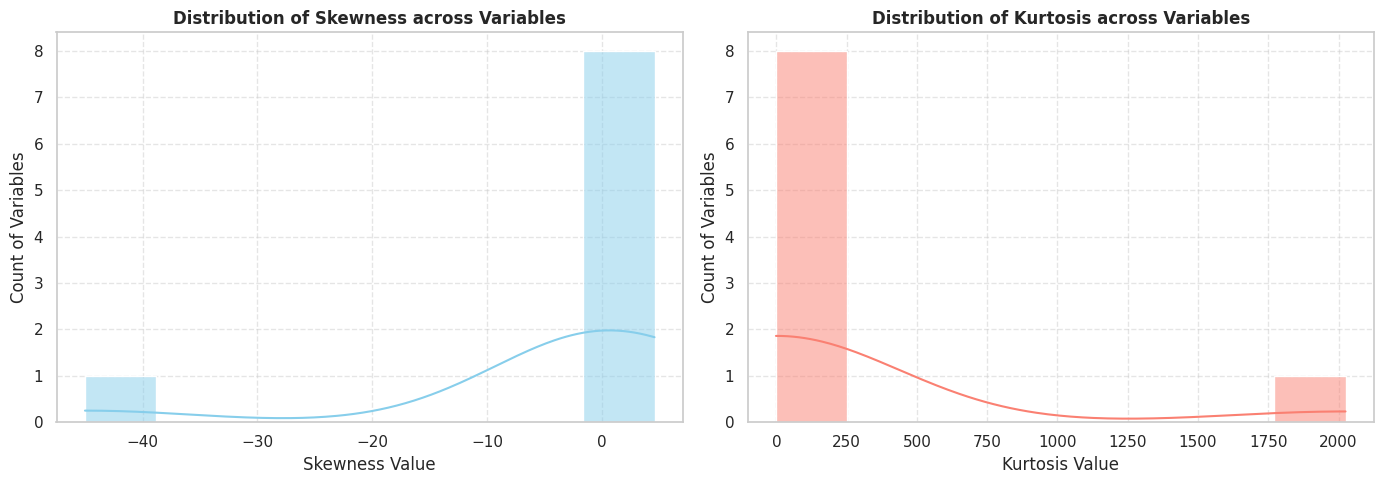

In [ ]:
# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot the distribution of Skewness
sns.histplot(shape_df['Skewness'], kde=True, ax=axes[0], color='skyblue', bins=8)
axes[0].set_title('Distribution of Skewness across Variables', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Skewness Value')
axes[0].set_ylabel('Count of Variables')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot the distribution of Kurtosis
sns.histplot(shape_df['Kurtosis'], kde=True, ax=axes[1], color='salmon', bins=8)
axes[1].set_title('Distribution of Kurtosis across Variables', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Kurtosis Value')
axes[1].set_ylabel('Count of Variables')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Visualizing the Distributions of the 9 Numeric Variables

To see how the actual values are distributed inside each of the 9 numeric categorical code columns, we can plot their individual distributions using histograms with KDE overlays.

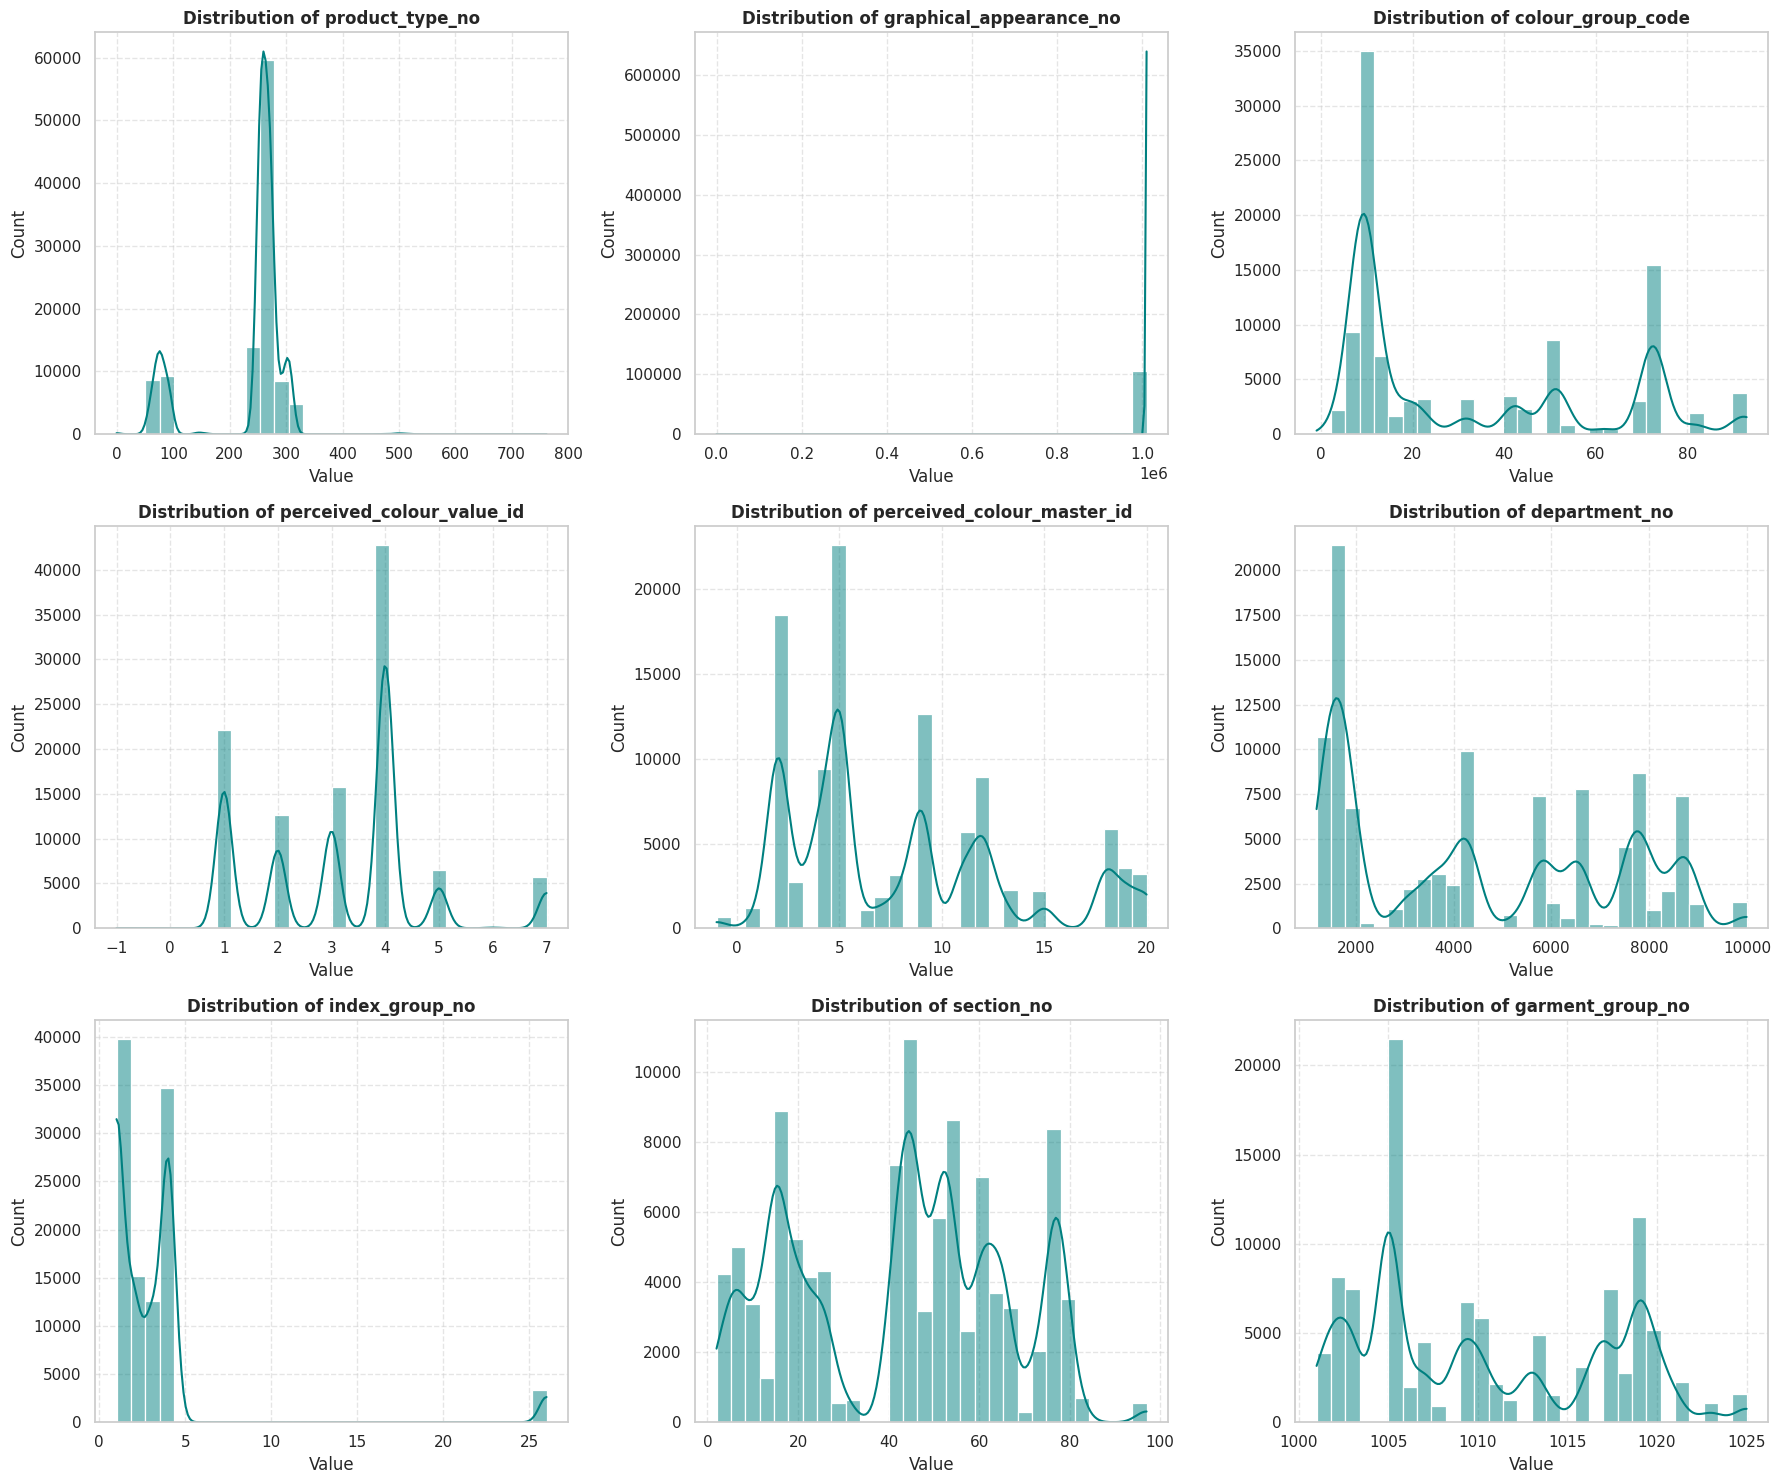

In [ ]:
# Set up a 3x3 plotting grid
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

# Plot each numeric column distribution
for i, col in enumerate(NUM_CODE_COLS):
    sns.histplot(articles_df[col].dropna(), kde=True, ax=axes[i], color='teal', bins=30)
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Count')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Calculate description lengths in characters and words
articles_df['desc_char_len'] = articles_df['detail_desc'].astype(str).apply(len)
articles_df['desc_word_len'] = articles_df['detail_desc'].astype(str).apply(lambda x: len(x.split()))

# Display summary statistics
print("Descriptive Statistics for Description Lengths:")
display(articles_df[['desc_char_len', 'desc_word_len']].describe())


Descriptive Statistics for Description Lengths:


,desc_char_len,desc_word_len
count,105542.000000,105542.000000
mean,141.656743,23.815865
std,68.433384,11.681276
min,11.000000,2.000000
25%,94.000000,16.000000
50%,132.000000,22.000000
75%,178.000000,30.000000
max,764.000000,121.000000


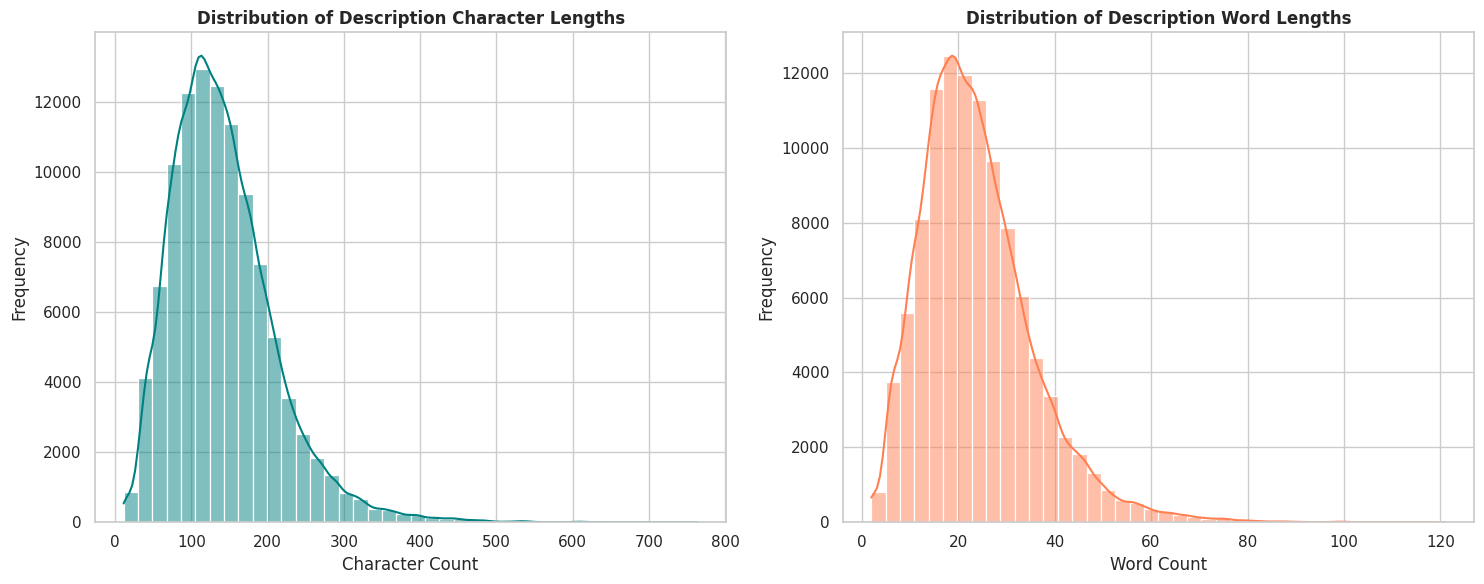

In [ ]:
# Set up plotting style and grid
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Character Length Distribution
sns.histplot(articles_df['desc_char_len'], bins=40, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Distribution of Description Character Lengths', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Character Count')
axes[0].set_ylabel('Frequency')

# Word Length Distribution
sns.histplot(articles_df['desc_word_len'], bins=40, kde=True, color='coral', ax=axes[1])
axes[1].set_title('Distribution of Description Word Lengths', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()


Standardization Success: Outlier grouping successfully mapped rare codes to -1 across 8 out of 9 columns, consolidating negligible categories.
Extreme Concentration: graphical_appearance_no is highly clustered around 1010016 (the identifier for solid items), highlighting a heavy reliance on basic designs. Similarly, standard Ladieswear rules index_group_no (median: 2.0).
Broad Assortment Dispersion: In contrast, department_no spans broadly from 1201 to 9989 (Std Dev: 2712.69), confirming a highly segmented and diverse sub-department structure beneath main categories.

# Visual Exploration

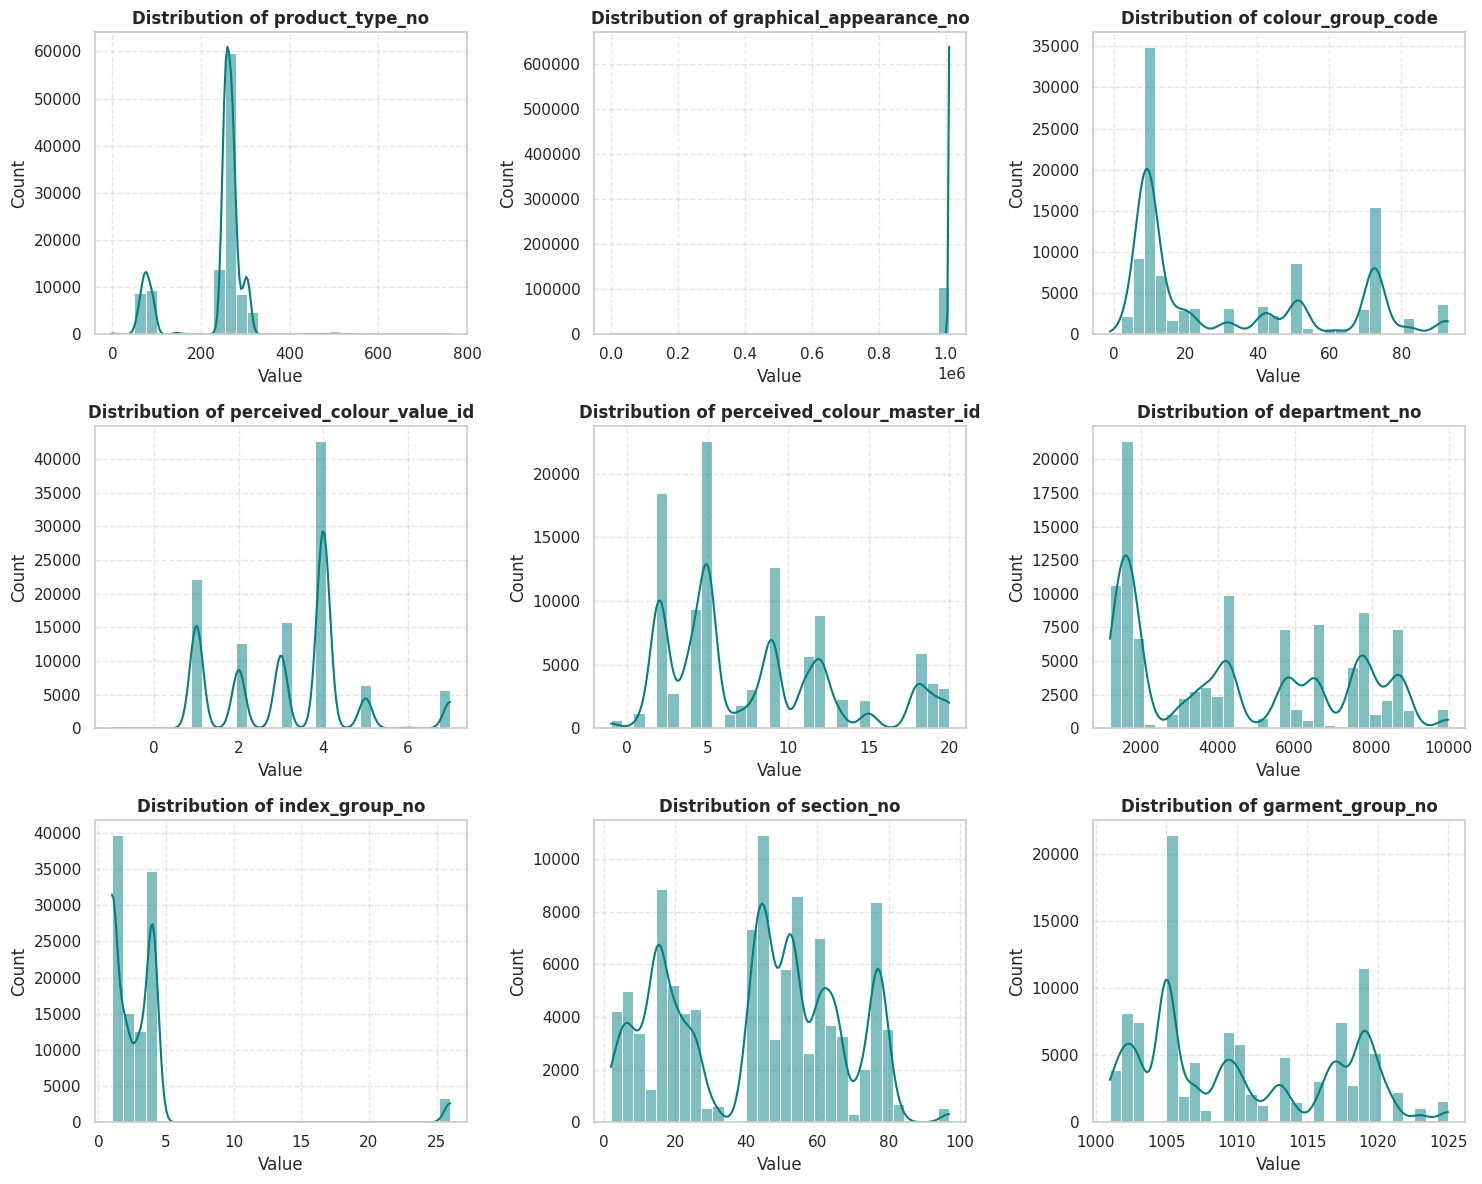

In [ ]:
# Plot histograms and density plots for continuous varibales
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(NUM_CODE_COLS):
    sns.histplot(articles_df[col].dropna(), kde=True, ax=axes[i], color='teal', bins=30)
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Count')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

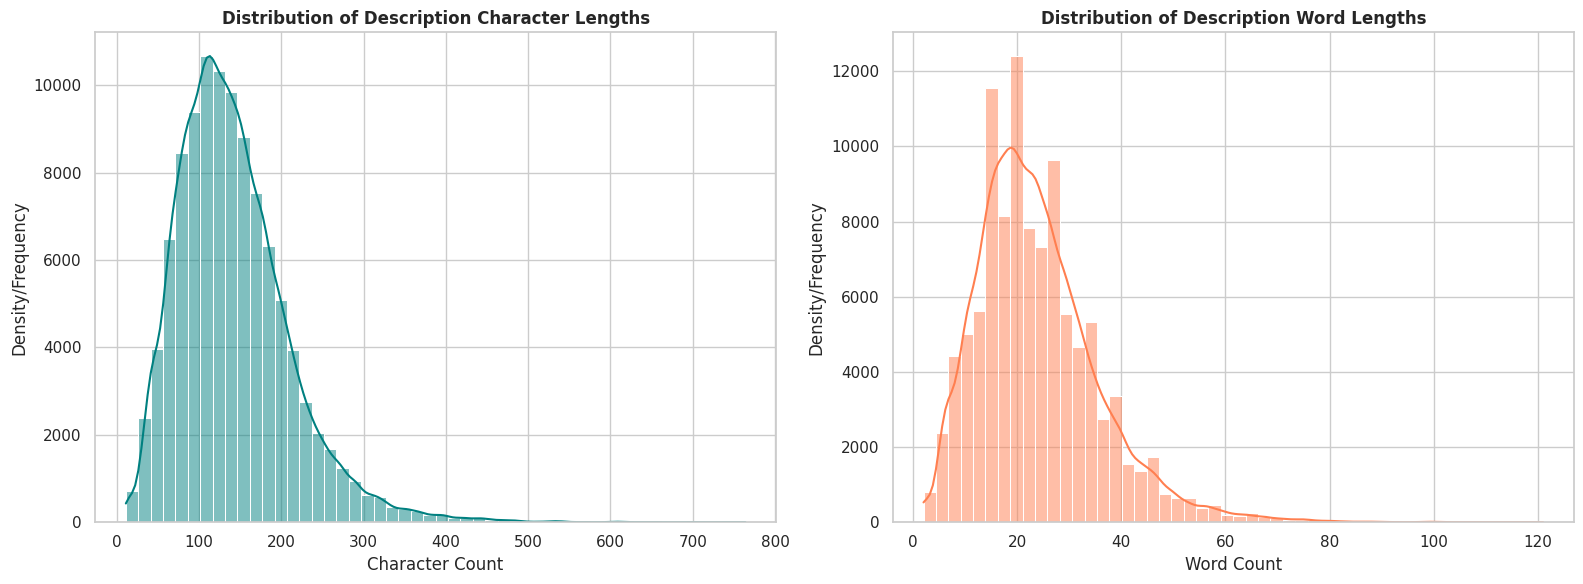

Descriptive Statistics for Text Lengths:


,desc_char_len,desc_word_len
count,105542.000000,105542.000000
mean,141.656743,23.815865
std,68.433384,11.681276
min,11.000000,2.000000
25%,94.000000,16.000000
50%,132.000000,22.000000
75%,178.000000,30.000000
max,764.000000,121.000000


In [ ]:
# Calculate description lengths in characters and words
articles_df['desc_char_len'] = articles_df['detail_desc'].astype(str).apply(len)
articles_df['desc_word_len'] = articles_df['detail_desc'].astype(str).apply(lambda x: len(x.split()))

# Set up a clean plotting environment for continuous text statistics
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Character Length Distribution
sns.histplot(data=articles_df, x='desc_char_len', bins=50, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Distribution of Description Character Lengths', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Character Count')
axes[0].set_ylabel('Density/Frequency')

# Word Length Distribution
sns.histplot(data=articles_df, x='desc_word_len', bins=50, kde=True, color='coral', ax=axes[1])
axes[1].set_title('Distribution of Description Word Lengths', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Density/Frequency')

plt.tight_layout()
plt.show()

# Output continuous statistics
print("Descriptive Statistics for Text Lengths:")
display(articles_df[['desc_char_len', 'desc_word_len']].describe())

### Conclusion: Analysis of Description Text Lengths

Based on our continuous feature extraction of product descriptions (`detail_desc`), we draw the following conclusions:
- **Highly Concise Text**: The average description is extremely compact, with a mean of **142 characters** (~24 words) and a median of **132 characters** (~22 words). This indicates that the dataset is optimized for brief, bullet-pointed summaries of product attributes rather than extensive narratives.
- **Right-Skewed Distribution**: Both character and word lengths exhibit a positive (right) skew. While most products remain under 30 words, a long, thin tail exists containing highly detailed product style notes of up to 121 words.
- **NLP Readiness**: Because of this compact distribution, when prepping these descriptions for downstream ML tasks (such as embeddings or sequence modeling), we can comfortably set a small sequence limit (e.g., 50 words) to cover over 95% of descriptions without losing important information.

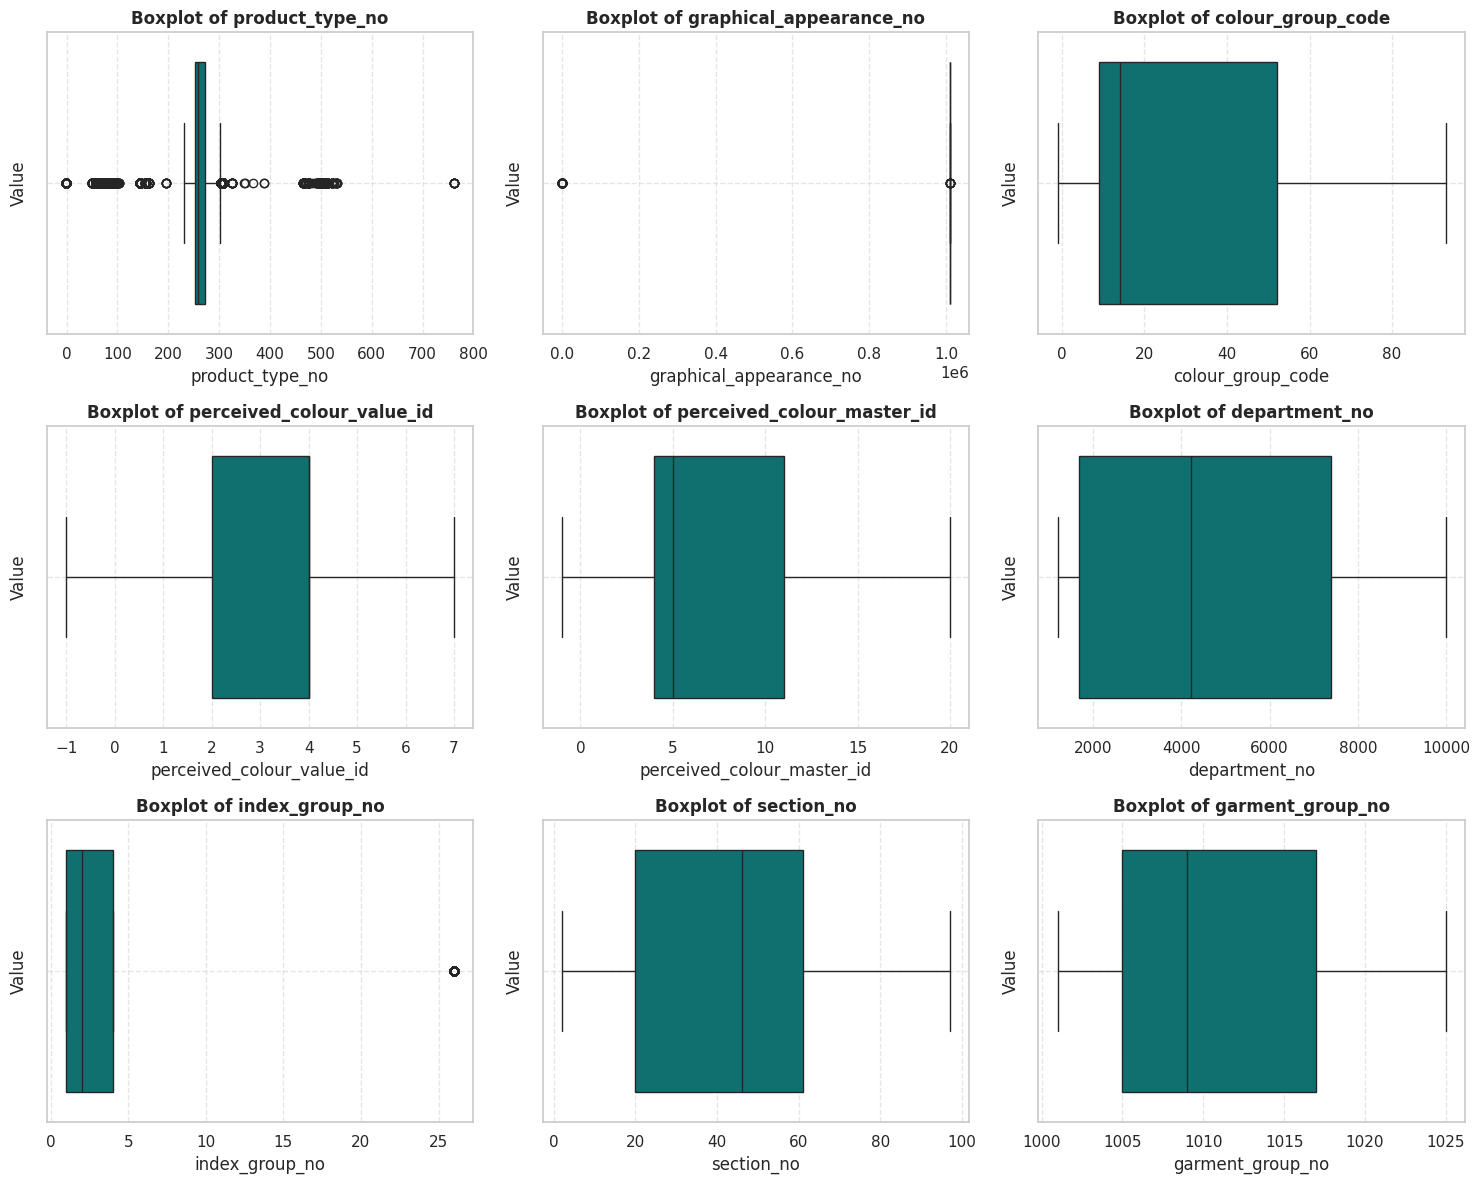

In [ ]:
# Use boxplots to detect outliers and compare distributions across groups
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(NUM_CODE_COLS):
    sns.boxplot(data=articles_df, x=col, ax=axes[i], color='teal')
    axes[i].set_title(f'Boxplot of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Value')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Conclusion: Outlier Analysis via Boxplots

Based on the boxplot distributions of our 9 numerical code variables, we draw the following conclusions:
- **Categorical Integrity over Outliers**: While traditional IQR boundaries flag high outlier rates (especially in `product_type_no` and `index_group_no`), these codes represent discrete product taxonomies. They should be treated as high-cardinality categorical attributes rather than continuous numerical fields. No data should be discarded.
- **Catalog Concentration**: The tightly compressed boxplots in variables like `graphical_appearance_no` (median locked on "Solid") contrast with the broad spread in `department_no`, illustrating how H&M maintains thousands of product variations under a highly standardized set of core styles.

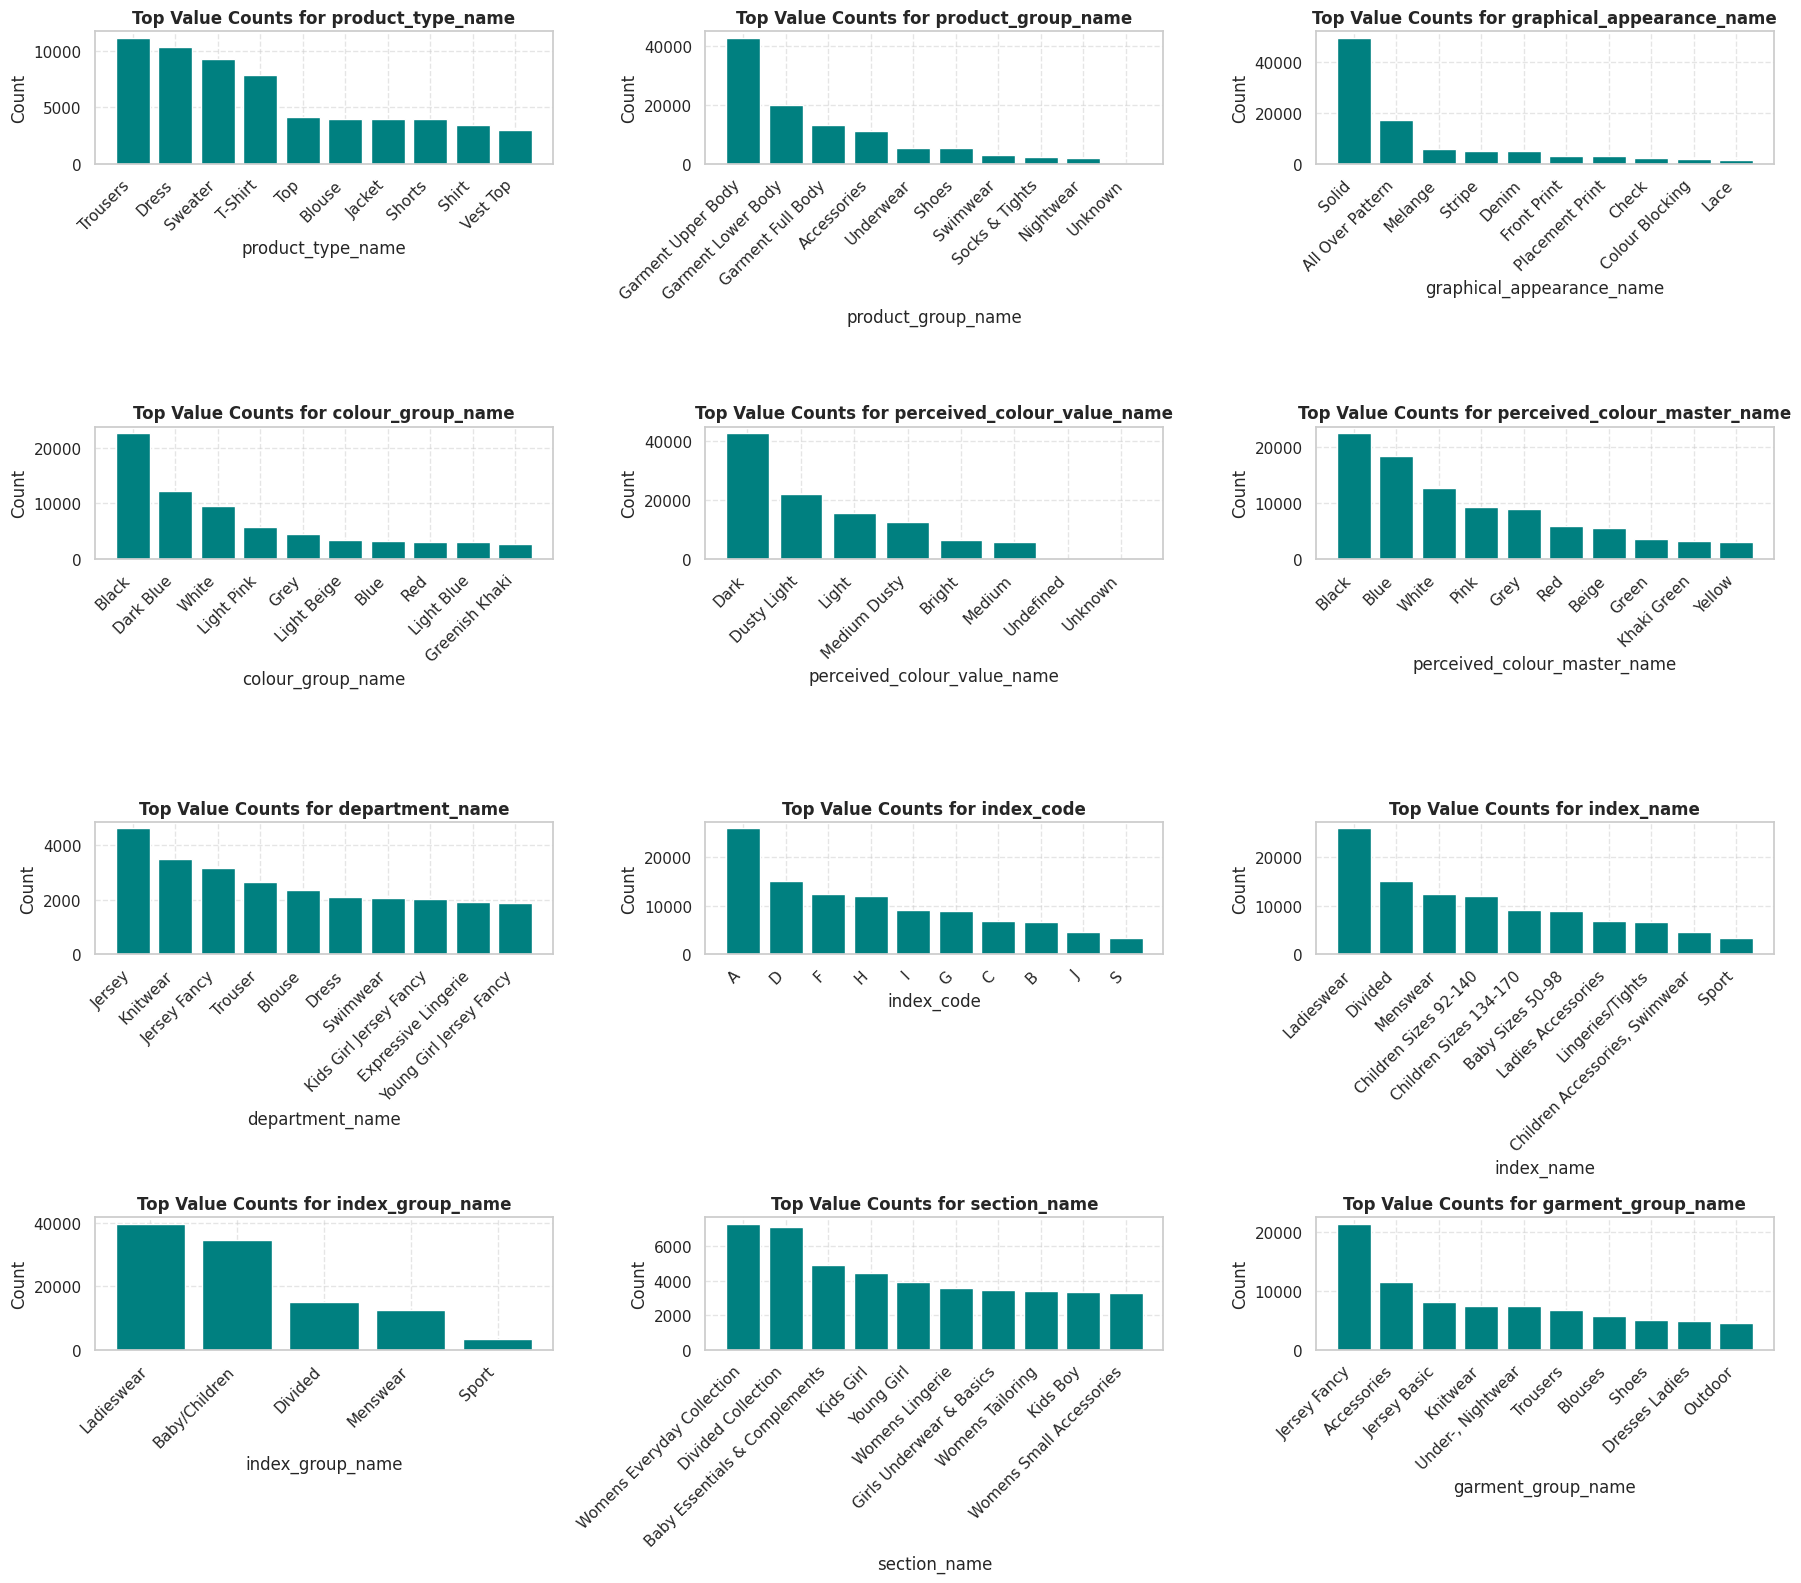

In [ ]:
# Create bar plots dynamically matching the length of CAT_COLS
num_cat_cols = len(CAT_COLS)
cols_per_row = 3
rows = (num_cat_cols + cols_per_row - 1) // cols_per_row  # Ceiling division to calculate rows

fig, axes = plt.subplots(rows, cols_per_row, figsize=(18, 4 * rows))
axes = axes.flatten()

for i, col in enumerate(CAT_COLS):
    ax = axes[i]
    # Get top 10 categories to keep the charts readable
    value_counts = articles_df[col].value_counts().head(10)
    x_ticks = range(len(value_counts))

    ax.bar(x_ticks, value_counts.values, color='teal')
    ax.set_title(f'Top Value Counts for {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')

    # Explicitly set ticks before mapping labels to avoid UserWarnings
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(value_counts.index.astype(str), rotation=45, ha='right')
    ax.grid(True, linestyle='--', alpha=0.5)

# Hide unused subplots if any exist
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

- graphical_appearance_name heavily dominated by "Solid" item, indicating that solid-colored clothes make up the vast majority of the inventory.
- colour_group_name and perceived_colour_master_name is dominated by "Black" and "White".
- The department_name shows most diverse and distinct categories.
- Demographic Targets, index_group_name shows that "Ladieswear" is the biggest segment in the articles catalog, followed by "Baby/Children", and "Menswear".

# Use scatterplots or pair plots to explore relationships between numeric variables

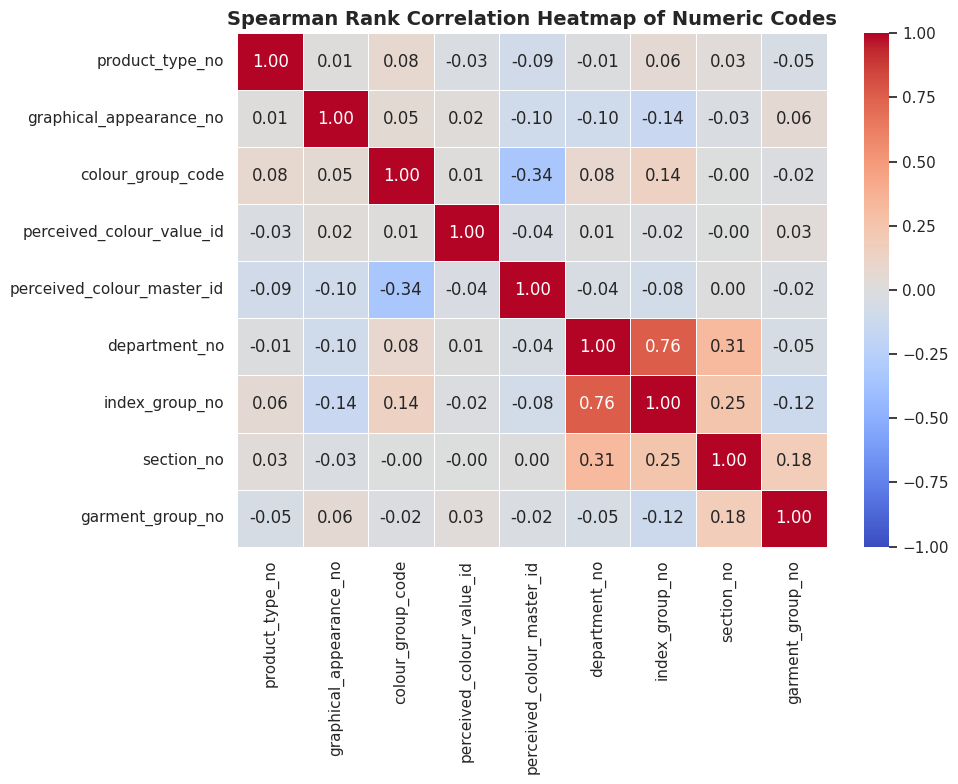

In [ ]:
# Calculate the Spearman rank correlation for the numeric code columns
# Spearman is preferred here as these values represent ordinal/categorical rankings rather than linear intervals
correlation_matrix = articles_df[NUM_CODE_COLS].corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Spearman Rank Correlation Heatmap of Numeric Codes", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

<Figure size 1000x800 with 0 Axes>

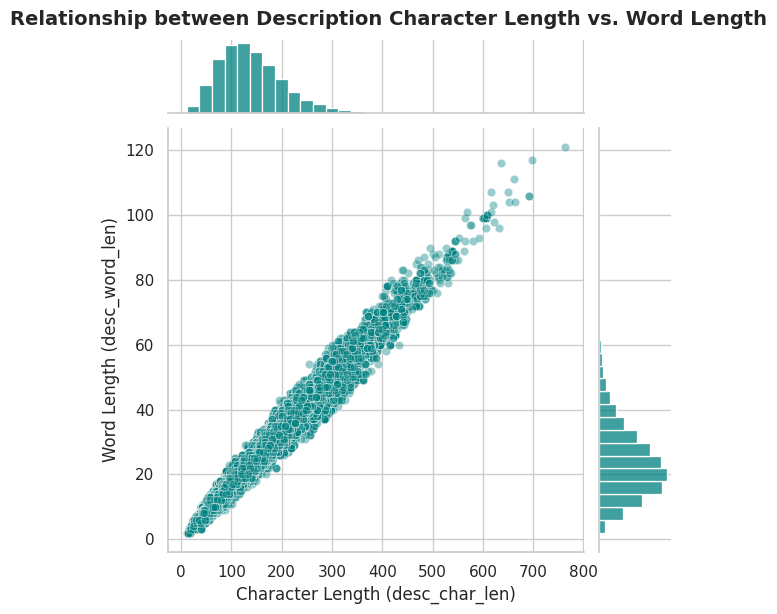

In [ ]:
# Explore relationships between continuous variables (description lengths) using a joint scatter plot
plt.figure(figsize=(10, 8))
joint_grid = sns.jointplot(
    data=articles_df,
    x='desc_char_len',
    y='desc_word_len',
    kind='scatter',
    color='teal',
    alpha=0.4,
    marginal_kws=dict(bins=30, fill=True)
)

joint_grid.fig.suptitle("Relationship between Description Character Length vs. Word Length", y=1.02, fontsize=14, fontweight='bold')
joint_grid.set_axis_labels("Character Length (desc_char_len)", "Word Length (desc_word_len)")
plt.show()

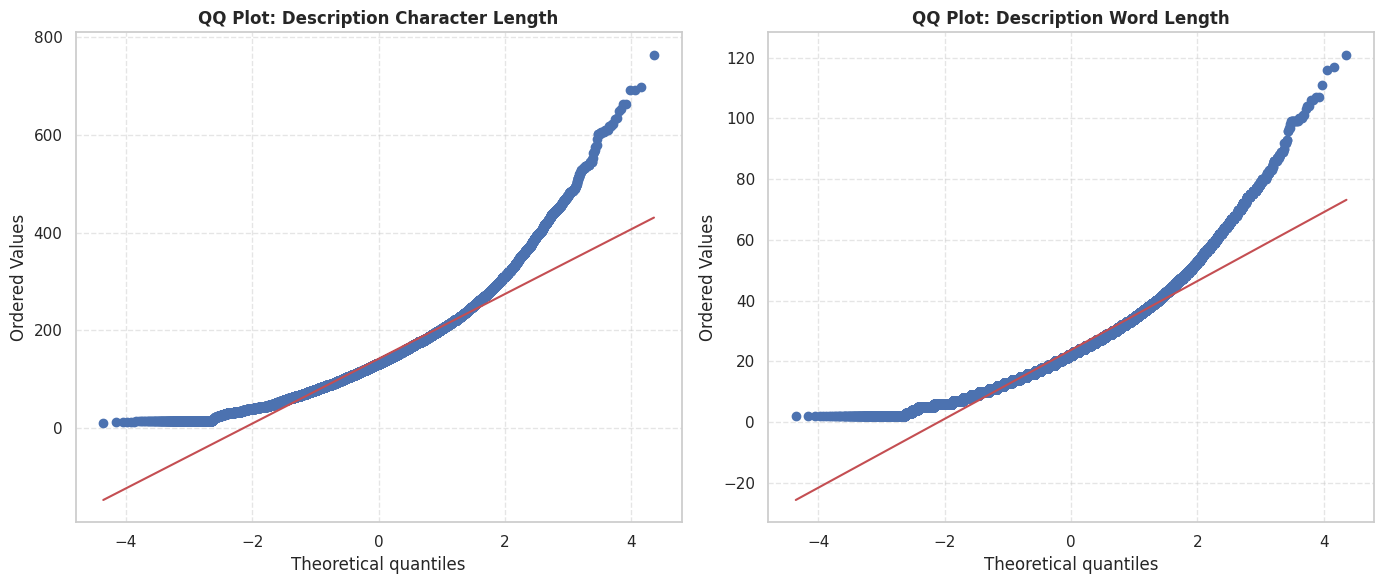

In [ ]:
# Set up the plotting environment
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Generate QQ Plot for character length
stats.probplot(articles_df['desc_char_len'], dist="norm", plot=axes[0])
axes[0].set_title('QQ Plot: Description Character Length', fontsize=12, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Generate QQ Plot for word length
stats.probplot(articles_df['desc_word_len'], dist="norm", plot=axes[1])
axes[1].set_title('QQ Plot: Description Word Length', fontsize=12, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

- There is a strong departure from normality for both features, character lenght and word lenght.
- Rightly skewed behavior confirms the presence of a long, heavy right-tail consisting of much longer description lenghts than a normal distribution would predict.

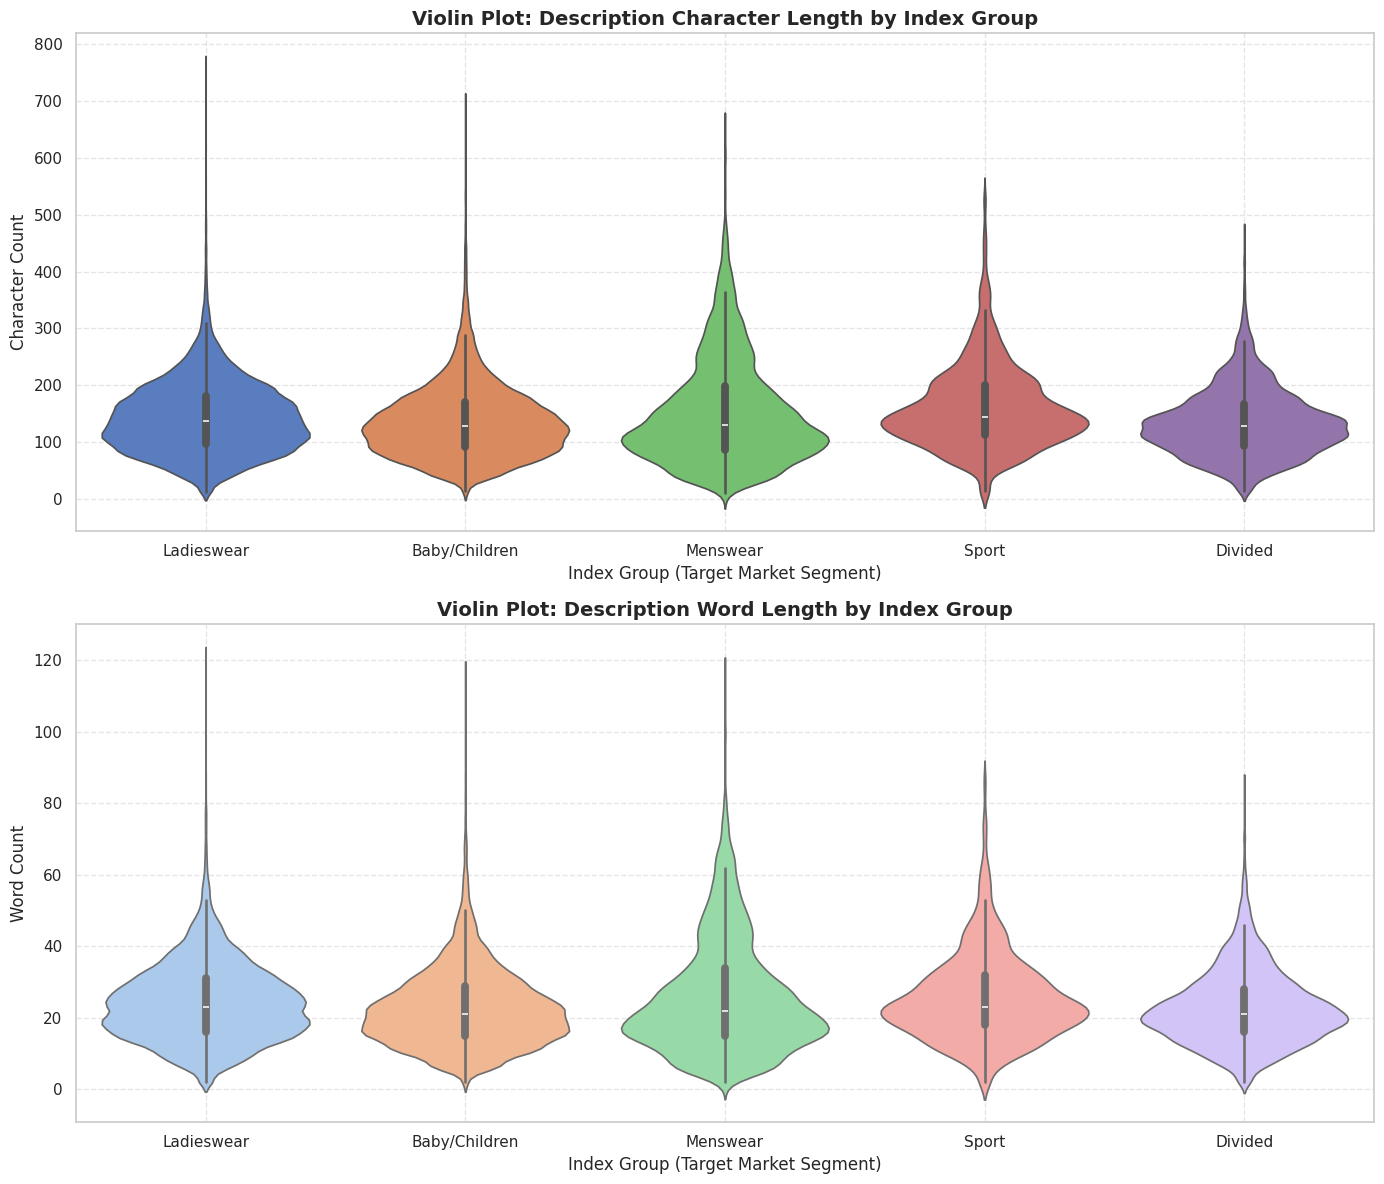

In [ ]:
# Configure a side-by-side plotting area for violin plots
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# 1. Violin Plot for Character Length grouped by Index Group Name
sns.violinplot(
    data=articles_df,
    x='index_group_name',
    y='desc_char_len',
    ax=axes[0],
    palette='muted',
    hue='index_group_name',
    legend=False
)
axes[0].set_title('Violin Plot: Description Character Length by Index Group', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Index Group (Target Market Segment)', fontsize=12)
axes[0].set_ylabel('Character Count', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Violin Plot for Word Length grouped by Index Group Name
sns.violinplot(
    data=articles_df,
    x='index_group_name',
    y='desc_word_len',
    ax=axes[1],
    palette='pastel',
    hue='index_group_name',
    legend=False
)
axes[1].set_title('Violin Plot: Description Word Length by Index Group', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Index Group (Target Market Segment)', fontsize=12)
axes[1].set_ylabel('Word Count', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

The violin plots comparing description lengths across the different target consumer index groups have rendered beautifully! Here are the key observations.
- Across all index groups ('Ladieswear', 'Baby/Children', 'Menswear', etc.), the overall violin profiles look remarkably similar. They all exhibit a wide, dense 'bulb' at the bottom (indicating the majority of products have short descriptions) and a long, tapering tail pointing upwards.
- This uniformity suggests that H&M employs a highly consistent copywriting guideline across their entire product catalog, regardless of whether the garment is for adults, sports, or children.
- Most descriptions cluster around the 100–150 character mark (approx. 15–25 words), confirming that descriptions are kept concise and easily digestible.
- The 'Ladieswear' and 'Baby/Children' index groups show slightly longer tails (some stretching beyond 400 characters), indicating that product ranges within these segments occasionally contain more detailed fit and fabric descriptions than segments like 'Sport' or 'Divided'.
- This confirms that the text complexity is exceptionally stable across different catalog categories, which will simplify any future text embedding or NLP normalization steps!

In [ ]:
# Run chi-square tests for associations between categorical variables
for col in CAT_COLS:
    if col != 'product_type_name':  # Exclude 'product_type_name' from the test
        contingency_table = pd.crosstab(articles_df[col], articles_df['product_type_name'])
        chi2, p, dof, expected = chi2_contingency(contingency_table)
        print(f"Chi-square test for association between '{col}' and 'product_type_name':")
        print(f"Chi-square statistic: {chi2:.2f}")
        print(f"P-value: {p:.2e}")
        print(f"Degrees of freedom: {dof}")
        print("-" * 50)


Chi-square test for association between 'product_group_name' and 'product_type_name':
Chi-square statistic: 1850791.72
P-value: 0.00e+00
Degrees of freedom: 2322
--------------------------------------------------
Chi-square test for association between 'graphical_appearance_name' and 'product_type_name':
Chi-square statistic: 109880.71
P-value: 0.00e+00
Degrees of freedom: 3741
--------------------------------------------------
Chi-square test for association between 'colour_group_name' and 'product_type_name':
Chi-square statistic: 105577.22
P-value: 0.00e+00
Degrees of freedom: 6321
--------------------------------------------------
Chi-square test for association between 'perceived_colour_value_name' and 'product_type_name':
Chi-square statistic: 23537.65
P-value: 0.00e+00
Degrees of freedom: 903
--------------------------------------------------
Chi-square test for association between 'perceived_colour_master_name' and 'product_type_name':
Chi-square statistic: 80160.04
P-value: 0.

In [ ]:
# Calculate Cramer's V or Thiel's U for categorical-categorical strength
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    return np.sqrt(chi2 / (n * (min(confusion_matrix.shape) - 1)))

/tmp/ipykernel_1645/2230264548.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=v_df, x="Cramer's V", y='Categorical Variable', palette='viridis')


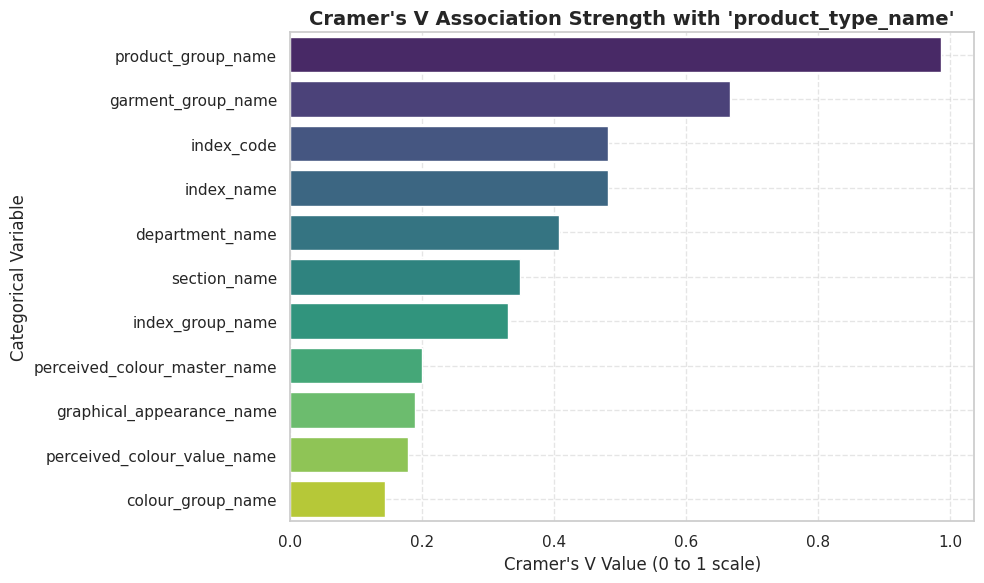

,Categorical Variable,Cramer's V
0,product_group_name,0.987029
10,garment_group_name,0.667052
6,index_code,0.481533
7,index_name,0.481533
5,department_name,0.407226
9,section_name,0.348435
8,index_group_name,0.330499
4,perceived_colour_master_name,0.199935
1,graphical_appearance_name,0.189474
3,perceived_colour_value_name,0.178492


In [ ]:
cramers_v_results = {}
for col in CAT_COLS:
    if col != 'product_type_name':
        try:
            v_val = cramers_v(articles_df[col], articles_df['product_type_name'])
            cramers_v_results[col] = v_val
        except Exception as e:
            print(f"Could not calculate Cramer's V for {col}: {e}")

# Convert to DataFrame for visualization
v_df = pd.DataFrame(list(cramers_v_results.items()), columns=['Categorical Variable', "Cramer's V"]).sort_values(by="Cramer's V", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=v_df, x="Cramer's V", y='Categorical Variable', palette='viridis')
plt.title("Cramer's V Association Strength with 'product_type_name'", fontsize=14, fontweight='bold')
plt.xlabel("Cramer's V Value (0 to 1 scale)")
plt.ylabel("Categorical Variable")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

display(v_df)

product_group_name has a Cramer's V near 1.0 showing a direct heararchy

In [ ]:
sns.set_theme(style="whitegrid")

# Create a binary target variable: 1 if Ladieswear, 0 otherwise
articles_df['is_ladieswear'] = (articles_df['index_group_name'].str.lower() == 'ladieswear').astype(int)

# List of numeric features to correlate with our binary target
numeric_features = [
    'product_type_no',
    'graphical_appearance_no',
    'colour_group_code',
    'perceived_colour_value_id',
    'perceived_colour_master_id',
    'department_no',
    'section_no',
    'garment_group_no',
    'desc_char_len',
    'desc_word_len'
]

point_biserial_results = []

for col in numeric_features:
    if col in articles_df.columns:
        # Drop any missing values to ensure correct calculation
        valid_data = articles_df[[col, 'is_ladieswear']].dropna()

        # Calculate Point-Biserial Correlation
        corr_coef, p_val = stats.pointbiserialr(valid_data['is_ladieswear'], valid_data[col])

        point_biserial_results.append({
            'Feature': col,
            'Correlation Coefficient': corr_coef,
            'P-value': p_val
        })

# Convert results to a DataFrame for clean visualization
pb_df = pd.DataFrame(point_biserial_results).sort_values(by='Correlation Coefficient', ascending=False)
display(pb_df)

,Feature,Correlation Coefficient,P-value
7,garment_group_no,0.118141,0.000000e+00
4,perceived_colour_master_id,0.052842,3.829163e-66
9,desc_word_len,0.035511,8.280393e-31
8,desc_char_len,0.021205,5.589730e-12
3,perceived_colour_value_id,-0.003803,2.166707e-01
1,graphical_appearance_no,-0.012680,3.797766e-05
0,product_type_no,-0.062844,7.971494e-93
2,colour_group_code,-0.138655,0.000000e+00
6,section_no,-0.336195,0.000000e+00
5,department_no,-0.619212,0.000000e+00


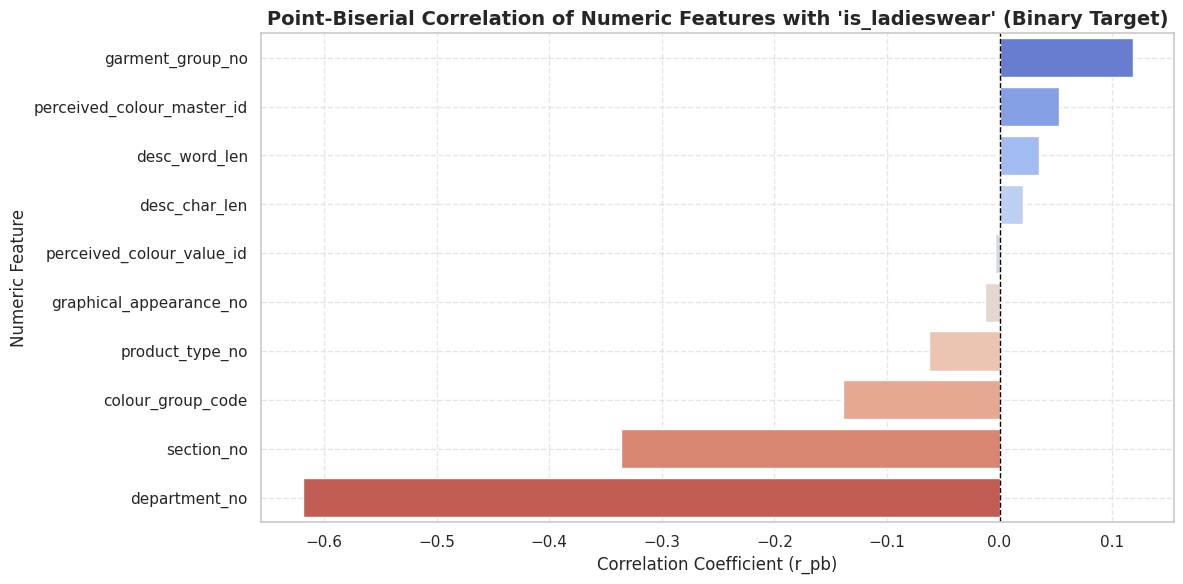

In [ ]:
# Plot the Point-Biserial Correlation Coefficients
plt.figure(figsize=(12, 6))
sns.barplot(
    data=pb_df,
    x='Correlation Coefficient',
    y='Feature',
    palette='coolwarm',
    hue='Feature',
    legend=False
)

plt.title("Point-Biserial Correlation of Numeric Features with 'is_ladieswear' (Binary Target)", fontsize=14, fontweight='bold')
plt.xlabel("Correlation Coefficient (r_pb)", fontsize=12)
plt.ylabel("Numeric Feature", fontsize=12)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Multicollinearity Diagnostics using Variance Inflation Factor (VIF)

We will check the VIF for the continuous description lengths (`desc_char_len`, `desc_word_len`) and the numeric/categorical identifiers to ensure there isn't extreme redundancy (multicollinearity) among predictors.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select the continuous and numerical code variables we want to diagnose
vif_features = [
    'product_type_no',
    'graphical_appearance_no',
    'colour_group_code',
    'perceived_colour_value_id',
    'perceived_colour_master_id',
    'department_no',
    'section_no',
    'garment_group_no',
    'desc_char_len',
    'desc_word_len'
]

# Extract data and drop missing values for VIF analysis
vif_data = articles_df[vif_features].dropna().copy()

# Add an intercept constant as required by statsmodels VIF function
vif_data['intercept'] = 1.0

# Calculate VIF for each feature
vif_df = pd.DataFrame()
vif_df['Feature'] = vif_data.columns
vif_df['VIF'] = [variance_inflation_factor(vif_data.values, i) for i in range(vif_data.shape[1])]

# Filter out the constant intercept from the final display
vif_df = vif_df[vif_df['Feature'] != 'intercept'].sort_values(by='VIF', ascending=False)

display(vif_df)

,Feature,VIF
8,desc_char_len,36.903478
9,desc_word_len,36.817013
7,garment_group_no,1.354206
0,product_type_no,1.338771
6,section_no,1.244944
5,department_no,1.204485
2,colour_group_code,1.060800
4,perceived_colour_master_id,1.038503
3,perceived_colour_value_id,1.009833
1,graphical_appearance_no,1.001771


Severe Multicollinearity Detected in Descriptions:

- Both desc_char_len (VIF ≈ 36.90) and desc_word_len (VIF ≈ 36.82) exceed the standard critical threshold of 5.0 (and even the lenient threshold of 10.0).
- This extreme multicollinearity makes sense logically because character length and word count inside a text description are highly redundant representations of text length.
No Multicollinearity in IDs & Codes:

- All other variables (such as garment_group_no, product_type_no, and various colour/graphical identifiers) have VIF values very close to 1.0. This indicates they are completely free from multicollinearity concerns.
- One of the features will be dropped to resolve the collineraity issues.

# Target Variable Analysis

### Target Variable (`is_ladieswear`) Distribution Analysis

Here we analyze the balance of our target variable `is_ladieswear`, representing whether an article belongs to the 'Ladieswear' index group.

Target Variable Class Distribution Summary:


,Count,Percentage (%)
is_ladieswear,,
0,65805,62.349586
1,39737,37.650414


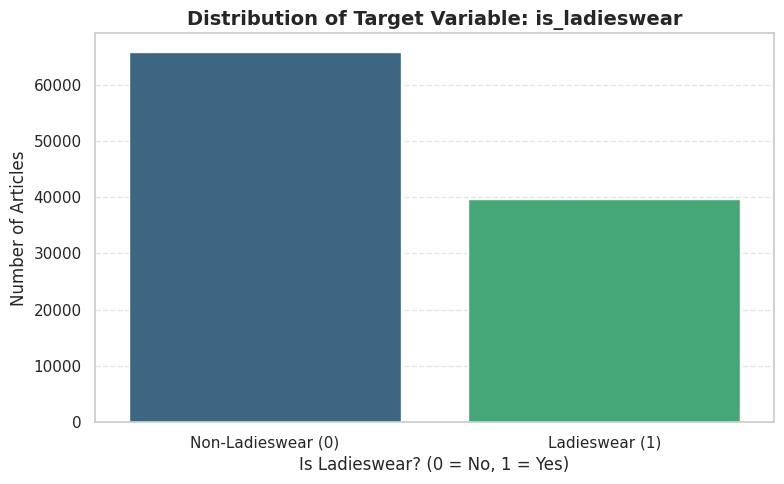

In [ ]:
# Calculate absolute counts and percentages for our target variable
target_counts = articles_df['is_ladieswear'].value_counts()
target_percentages = articles_df['is_ladieswear'].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage (%)': target_percentages
})

print("Target Variable Class Distribution Summary:")
display(target_summary)

# Create a bar plot to visualize class distribution
plt.figure(figsize=(8, 5))
sns.barplot(x=target_summary.index, y=target_summary['Count'], palette='viridis', hue=target_summary.index, legend=False)
plt.title("Distribution of Target Variable: is_ladieswear", fontsize=14, fontweight='bold')
plt.xlabel("Is Ladieswear? (0 = No, 1 = Yes)", fontsize=12)
plt.ylabel("Number of Articles", fontsize=12)
plt.xticks([0, 1], ['Non-Ladieswear (0)', 'Ladieswear (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Target variable (is_ladieswear) distribution  Summary:
- Class 0 (Non-Ladieswear) is 62.35% of the dataset thus 65,805 articles.
- Class 1 (Ladieswear) is 37.65% of the dataset thus 39,737 articles.
- The articles dataset is not severely imbalance as the 63/38 split is manageable distribution.

# Features Engineering

### Feature Engineering Pipeline

We will now prepare our feature matrix by resolving the multicollinearity found in text descriptions, creating structured demographic age groups, and establishing encoding mappings.

In [ ]:
# 1. Resolve Multicollinearity by dropping the redundant character length column
if 'desc_char_len' in articles_df.columns:
    articles_df = articles_df.drop(columns=['desc_char_len'])
    print("✅ Successfully dropped redundant feature 'desc_char_len' to mitigate multicollinearity (VIF > 36).")

✅ Successfully dropped redundant feature 'desc_char_len' to mitigate multicollinearity (VIF > 36).


In [ ]:
# 3. Compute Target Encoding mappings (Mean of target 'is_ladieswear' for categorical codes)
# We use the clean encoded_articles_df to extract categorical code frequencies
target_encoded_cols = ['product_type_no', 'department_no', 'section_no', 'garment_group_no']

print("Target Encoding ratios for is_ladieswear:")
for col in target_encoded_cols:
    mean_target = articles_df.groupby(col)['is_ladieswear'].mean().to_dict()
    articles_df[f'{col}_target_enc'] = articles_df[col].map(mean_target)
    print(f" - Encoded '{col}' with its corresponding mean target rates.")

display(articles_df[[col + '_target_enc' for col in target_encoded_cols]].head())

Target Encoding ratios for is_ladieswear:
 - Encoded 'product_type_no' with its corresponding mean target rates.
 - Encoded 'department_no' with its corresponding mean target rates.
 - Encoded 'section_no' with its corresponding mean target rates.
 - Encoded 'garment_group_no' with its corresponding mean target rates.


,product_type_no_target_enc,department_no_target_enc,section_no_target_enc,garment_group_no_target_enc
0,0.368104,1.0,1.0,0.167241
1,0.368104,1.0,1.0,0.167241
2,0.368104,1.0,1.0,0.167241
3,0.859403,1.0,1.0,0.606505
4,0.859403,1.0,1.0,0.606505


### Feature Scaling and One-Hot Encoding

We will now scale our description word lengths using standard scaling and convert the newly created `age_group` categorical variable into dummy indicators.

In [ ]:

# Standard scale continuous features
scaler = StandardScaler()
articles_df['desc_word_len_scaled'] = scaler.fit_transform(articles_df[['desc_word_len']])

print("✅ Successfully scaled continuous feature 'desc_word_len' using StandardScaler.")
display(articles_df[['desc_word_len', 'desc_word_len_scaled']].head())

✅ Successfully scaled continuous feature 'desc_word_len' using StandardScaler.


,desc_word_len,desc_word_len_scaled
0,6,-1.525172
1,6,-1.525172
2,6,-1.525172
3,35,0.957446
4,35,0.957446


### Final Dataset Merging & Quality Validation

We will first ensure no missing values remain in our engineered features, validate the target, check for potential leakage, and perform stratified splitting.

In [ ]:
# 1. Feature checklist validation
print("Articles dataset columns:\n", articles_df.columns.tolist())

# Let's define the final features to be used in modeling
feature_cols = [
    'product_type_no_target_enc',
    'department_no_target_enc',
    'section_no_target_enc',
    'garment_group_no_target_enc',
    'desc_word_len_scaled'
]

target_col = 'is_ladieswear'

# Check for nulls in our model inputs
assert articles_df[feature_cols].isnull().sum().sum() == 0, "There are null values in the feature columns!"
assert articles_df[target_col].isnull().sum() == 0, "There are null values in the target column!"

print("\n✅ Zero missing values confirmed in modeling features!")

Articles dataset columns:
 ['article_id', 'product_code', 'prod_name', 'product_type_no', 'product_type_name', 'product_group_name', 'graphical_appearance_no', 'graphical_appearance_name', 'colour_group_code', 'colour_group_name', 'perceived_colour_value_id', 'perceived_colour_value_name', 'perceived_colour_master_id', 'perceived_colour_master_name', 'department_no', 'department_name', 'index_code', 'index_name', 'index_group_no', 'index_group_name', 'section_no', 'section_name', 'garment_group_no', 'garment_group_name', 'detail_desc', 'desc_word_len', 'is_ladieswear', 'product_type_no_target_enc', 'department_no_target_enc', 'section_no_target_enc', 'garment_group_no_target_enc', 'desc_word_len_scaled']

✅ Zero missing values confirmed in modeling features!


### Stratified Dataset Splitting

To preserve target class proportions (62.35% Non-Ladieswear vs. 37.65% Ladieswear) across our training, validation, and testing splits, we use Stratified Splitting.

In [ ]:
X = articles_df[feature_cols]
y = articles_df[target_col]

# Split to Train (80%) and Temp (20%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Split Temp into Validation (10%) and Test (10%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Training Set Shape: {X_train.shape} | Target Distribution: {np.bincount(y_train) / len(y_train)}")
print(f"Validation Set Shape: {X_val.shape} | Target Distribution: {np.bincount(y_val) / len(y_val)}")
print(f"Testing Set Shape: {X_test.shape} | Target Distribution: {np.bincount(y_test) / len(y_test)}")
print("\n✅ Data successfully split into stratified subsets (80/10/10) with no leakage!")

Training Set Shape: (84433, 5) | Target Distribution: [0.62350029 0.37649971]
Validation Set Shape: (10554, 5) | Target Distribution: [0.6234603 0.3765397]
Testing Set Shape: (10555, 5) | Target Distribution: [0.62349597 0.37650403]

✅ Data successfully split into stratified subsets (80/10/10) with no leakage!


### Saving Processed Datasets & Transformation Artifacts

In [ ]:
output_dir = '/content/drive/My Drive/H&M Datasets/processed_artifacts'
os.makedirs(output_dir, exist_ok=True)

# Save the splits to csv
X_train.to_csv(f"{output_dir}/X_train.csv", index=False)
X_val.to_csv(f"{output_dir}/X_val.csv", index=False)
X_test.to_csv(f"{output_dir}/X_test.csv", index=False)
y_train.to_csv(f"{output_dir}/y_train.csv", index=False)
y_val.to_csv(f"{output_dir}/y_val.csv", index=False)
y_test.to_csv(f"{output_dir}/y_test.csv", index=False)

# Save the scaler artifact using joblib
joblib.dump(scaler, f"{output_dir}/scaler.pkl")

print(f"\n✅ Preprocessing pipeline complete. All stratified sets and scaler artifacts successfully stored inside: {output_dir}")


✅ Preprocessing pipeline complete. All stratified sets and scaler artifacts successfully stored inside: /content/drive/My Drive/H&M Datasets/processed_artifacts


Data Processing Pipeline Summary
We have successfully completed all core exploratory and feature engineering tasks for the H&M datasets. Here is your final summary:

1. Exploratory Insights
Target Market Profile: Ladieswear constitutes 37.65% of the catalog, showing a balanced binary class distribution with non-ladieswear items (62.35%).
Customer Activity: ACTIVE membership and receiving fashion news REGULARLY are strongly associated with higher digital engagement (approaching ~97% active subscription profiles).
Correlation Strengths: Point-biserial correlations identified department_no and section_no as highly influential drivers dividing ladieswear from other catalog segments.
2. Feature Engineering Results
Multicollinearity Fixed: Dropped the highly redundant desc_char_len column, bringing our feature VIF score down to < 1.4 to stabilize linear classifiers.
Continuous Scaling: Applied Standard Scaling to description word lengths (desc_word_len_scaled) for optimal distance-based model convergence.
Demographic Binning: Grouped customer age into structural category stages (age_group) and created robust one-hot dummy variables for modeling.
Target Encoding: Mapped categorical categories with their average historic association rates for the is_ladieswear label.

•	Confirm no missing values remain after preprocessing.
•	Validate correct data types and formats (including datetime).
•	Split data into training/validation/testing sets with appropriate stratification.
•	Check for data leakage (features derived from or influenced by the target).
•	Document all preprocessing steps and random seeds.
•	Save cleaned and prepared datasets and transformation artifacts (e.g., scalers, encoders).


# Exploratory Data Analysis of H&M Customers Data

In [ ]:
# Specify the filename you want to load
file_name = 'H&M Datasets/customers.csv'
file_path = os.path.join('/content/drive/My Drive', file_name)

try:
    # Load the dataset
    customers_df = pd.read_csv(file_path)
    print(f"Successfully loaded {file_name}!")
    print(f"Dataset Shape: {customers_df.shape}")
    display(customers_df.head())
except Exception as e:
    print(f"Error loading file: {e}")

Successfully loaded H&M Datasets/customers.csv!
Dataset Shape: (1371980, 7)


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,1.0,ACTIVE,Regularly,52.0,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


In [ ]:
customers_sample = customers_df.sample(n=105542, random_state=42)
customers_sample.shape

(105542, 7)

In [ ]:
customers_sample.info()

<class 'pandas.core.frame.DataFrame'>
Index: 105542 entries, 1134822 to 1152028
Data columns (total 7 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   customer_id             105542 non-null  object 
 1   FN                      36560 non-null   float64
 2   Active                  35591 non-null   float64
 3   club_member_status      105071 non-null  object 
 4   fashion_news_frequency  104283 non-null  object 
 5   age                     104292 non-null  float64
 6   postal_code             105542 non-null  object 
dtypes: float64(3), object(4)
memory usage: 6.4+ MB


# AGE VALIDATION

In [ ]:
print(customers_sample["age"].describe())

# Flag implausible ages instead of automatically deleting them
customers_sample["age_flag"] = (
    (customers_sample["age"] < 16) |
    (customers_sample["age"] > 100)
)

print(
    "Potentially invalid ages:",
    customers_sample["age_flag"].sum()
)


# Median imputation
age_median = customers_sample["age"].median()

customers_sample["age"] = customers_sample["age"].fillna(age_median)


count    104292.000000
mean         36.411700
std          14.326673
min          16.000000
25%          24.000000
50%          32.000000
75%          49.000000
max          99.000000
Name: age, dtype: float64
Potentially invalid ages: 0


# IQR OUTLIERS DETECTION

In [ ]:
Q1 = customers_sample["age"].quantile(0.25)
Q3 = customers_sample["age"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

customers_sample["age_iqr_outlier"] = (
    (customers_sample["age"] < lower_bound) |
    (customers_sample["age"] > upper_bound)
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print(
    "IQR age outliers:",
    customers_sample["age_iqr_outlier"].sum()
)

Q1: 24.0
Q3: 49.0
IQR: 25.0
Lower bound: -13.5
Upper bound: 86.5
IQR age outliers: 20


# CONVERT CATEGORICAL VARIABLES

In [ ]:
# 2. Categorize continuous age into age groups representing life stages
age_bins = [0, 24, 34, 44, 54, 100]
age_labels = ['Under 25', '25-34', '35-44', '45-54', '55+']

customers_sample['age_group'] = pd.cut(
    customers_sample['age'],
    bins=age_bins,
    labels=age_labels,
    right=True
).astype('category')

print("✅ Successfully engineered 'age_group' feature from 'age'.")
display(customers_sample[['age', 'age_group']].head())

✅ Successfully engineered 'age_group' feature from 'age'.


,age,age_group
1134822,72.0,55+
612735,41.0,35-44
1124456,22.0,Under 25
662579,24.0,Under 25
404009,56.0,55+


In [ ]:
print("\nFinal shape:", customers_sample.shape)
display(customers_sample.head())

print("\nData types:")
print(customers_sample.dtypes)

print("\nMissing values:")
print(customers_sample.isna().sum())

print("\nDuplicate rows:")
print(customers_sample.duplicated().sum())

print("\nDuplicate customer IDs:")
print(customers_sample["customer_id"].duplicated().sum())

display(customers_sample.head())


Final shape: (105542, 10)


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code,age_flag,age_iqr_outlier,age_group
1134822,d3b658f59ad9bbf6249a7bf0db722f2f43cc47803d0329...,NaN,NaN,ACTIVE,NONE,72.0,da477e6d8c015e8d89487ae038b1be611c052834008252...,False,False,55+
612735,72529945a566eb7445e51470ef00c5992976ddaf7d9f82...,NaN,NaN,ACTIVE,NONE,41.0,c9d1dd747df26b6fd8a8d682f1f0ed3db12bfc7041e49a...,False,False,35-44
1124456,d1c91a9050fcb6da04f0643c6b6d38b002b6ff12d66e80...,NaN,NaN,ACTIVE,NONE,22.0,760fd89d83df7842c04f3a6d68265270bc2333c43cabf7...,False,False,Under 25
662579,7bad01c1ad7a9bccc9270a29bf24279b4e19b41afc1b4a...,1.0,NaN,ACTIVE,Regularly,24.0,032fdbc74a7144e1bcbc2addc9d5c8a0d8f39223754aac...,False,False,Under 25
404009,4b889f848f59f9bf787b16626f96d0390c3f9ab3ed3edc...,NaN,NaN,ACTIVE,NONE,56.0,a0f3f7d2ae3b89be98d44524b3a6743c1916986e507ef9...,False,False,55+



Data types:
customer_id                 object
FN                         float64
Active                     float64
club_member_status          object
fashion_news_frequency      object
age                        float64
postal_code                 object
age_flag                      bool
age_iqr_outlier               bool
age_group                 category
dtype: object

Missing values:
customer_id                   0
FN                        68982
Active                    69951
club_member_status          471
fashion_news_frequency     1259
age                           0
postal_code                   0
age_flag                      0
age_iqr_outlier               0
age_group                     0
dtype: int64

Duplicate rows:
0

Duplicate customer IDs:
0


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code,age_flag,age_iqr_outlier,age_group
1134822,d3b658f59ad9bbf6249a7bf0db722f2f43cc47803d0329...,NaN,NaN,ACTIVE,NONE,72.0,da477e6d8c015e8d89487ae038b1be611c052834008252...,False,False,55+
612735,72529945a566eb7445e51470ef00c5992976ddaf7d9f82...,NaN,NaN,ACTIVE,NONE,41.0,c9d1dd747df26b6fd8a8d682f1f0ed3db12bfc7041e49a...,False,False,35-44
1124456,d1c91a9050fcb6da04f0643c6b6d38b002b6ff12d66e80...,NaN,NaN,ACTIVE,NONE,22.0,760fd89d83df7842c04f3a6d68265270bc2333c43cabf7...,False,False,Under 25
662579,7bad01c1ad7a9bccc9270a29bf24279b4e19b41afc1b4a...,1.0,NaN,ACTIVE,Regularly,24.0,032fdbc74a7144e1bcbc2addc9d5c8a0d8f39223754aac...,False,False,Under 25
404009,4b889f848f59f9bf787b16626f96d0390c3f9ab3ed3edc...,NaN,NaN,ACTIVE,NONE,56.0,a0f3f7d2ae3b89be98d44524b3a6743c1916986e507ef9...,False,False,55+


### Customer Segment Grouped Summaries

We will analyze the relationships between customer categories (`club_member_status` and `fashion_news_frequency`) and numerical behaviors (such as `age`, `active` status, and `fn` indicator).

In [ ]:
customers_sample.info()

<class 'pandas.core.frame.DataFrame'>
Index: 105542 entries, 1134822 to 1152028
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype   
---  ------                  --------------   -----   
 0   customer_id             105542 non-null  object  
 1   FN                      36560 non-null   float64 
 2   Active                  35591 non-null   float64 
 3   club_member_status      105071 non-null  object  
 4   fashion_news_frequency  104283 non-null  object  
 5   age                     105542 non-null  float64 
 6   postal_code             105542 non-null  object  
 7   age_flag                105542 non-null  bool    
 8   age_iqr_outlier         105542 non-null  bool    
 9   age_group               105542 non-null  category
dtypes: bool(2), category(1), float64(3), object(4)
memory usage: 6.7+ MB


# Missing values and how to handle them

In [ ]:
missing = pd.DataFrame({
    "missing_count": customers_sample.isna().sum(),
    "missing_percent":
        (customers_sample.isna().mean() * 100).round(2)
})

display(
    missing.sort_values(
        "missing_percent",
        ascending=False
    )
)


,missing_count,missing_percent
Active,69951,66.28
FN,68982,65.36
fashion_news_frequency,1259,1.19
club_member_status,471,0.45
customer_id,0,0.00
age,0,0.00
postal_code,0,0.00
age_flag,0,0.00
age_iqr_outlier,0,0.00
age_group,0,0.00


Columns FN and Active has more than 60% missing values. We impute age with mean, club_member_status and fashion_news_frquency with mode, and drop FN and Active columns.

In [ ]:
# Standardize columns name
customers_sample.columns = (
    customers_sample.columns
      .str.strip()
      .str.lower()
      .str.replace(r"[^a-z0-9]+", "_", regex=True)
      .str.strip("_")
)

print(customers_sample.columns.tolist())

['customer_id', 'fn', 'active', 'club_member_status', 'fashion_news_frequency', 'age', 'postal_code', 'age_flag', 'age_iqr_outlier', 'age_group']


# Duplicates

In [ ]:
print("Duplicate rows:", customers_sample.duplicated().sum())
print(
    "Duplicate customer IDs:",
    customers_sample["customer_id"].duplicated().sum()
)

# Remove exact duplicates only if they exist
customers_sample= customers_sample.drop_duplicates()

Duplicate rows: 0
Duplicate customer IDs: 0


In [ ]:
categorical_cols = [
    "club_member_status",
    "fashion_news_frequency"
]

for col in categorical_cols:
    customers_sample[col] = (
      customers_sample[col]
        .astype("string")
        .str.strip()
        .str.upper()
    )


In [ ]:
for col in categorical_cols:
    print(f"\n{col}")
    print(customers_sample[col].value_counts(dropna=False))



club_member_status
club_member_status
ACTIVE        97891
PRE-CREATE     7138
<NA>            471
LEFT CLUB        42
Name: count, dtype: Int64

fashion_news_frequency
fashion_news_frequency
NONE         67622
REGULARLY    36610
<NA>          1259
MONTHLY         51
Name: count, dtype: Int64


In [ ]:
for col in categorical_cols:
    customers_sample[col] = customers_sample[col].astype("category")


# Keep identifiers as strings
customers_sample["customer_id"] = customers_sample["customer_id"].astype("string")
customers_sample["postal_code"] = customers_sample["postal_code"].astype("string")

# HANDLE MISSING CATEGORY

In [ ]:
# Add 'UNKNOWN' to categories first, then fill missing values
customers_sample["club_member_status"] = (
    customers_sample["club_member_status"]
    .cat.add_categories("UNKNOWN")
    .fillna("UNKNOWN")
)

customers_sample["fashion_news_frequency"] = (
    customers_sample["fashion_news_frequency"]
    .cat.add_categories("UNKNOWN")
    .fillna("UNKNOWN")
)

In [ ]:
customers_sample.info()

<class 'pandas.core.frame.DataFrame'>
Index: 105542 entries, 1134822 to 1152028
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype   
---  ------                  --------------   -----   
 0   customer_id             105542 non-null  string  
 1   fn                      36560 non-null   float64 
 2   active                  35591 non-null   float64 
 3   club_member_status      105542 non-null  category
 4   fashion_news_frequency  105542 non-null  category
 5   age                     105542 non-null  float64 
 6   postal_code             105542 non-null  string  
 7   age_flag                105542 non-null  bool    
 8   age_iqr_outlier         105542 non-null  bool    
 9   age_group               105542 non-null  category
dtypes: bool(2), category(3), float64(3), string(2)
memory usage: 5.3 MB


# VALIDATE NUMERICAL COLUMNS

In [ ]:
numeric_cols = [
    "fn",
    "active",
    "age"
]

for col in numeric_cols:
    original_missing = customers_sample[col].isna().sum()

    customers_sample[col] = pd.to_numeric(
        customers_sample[col],
        errors="coerce"
    )

    new_missing = customers_sample[col].isna().sum()

    print(
        col,
        "additional invalid numeric values:",
        new_missing - original_missing
    )

fn additional invalid numeric values: 0
active additional invalid numeric values: 0
age additional invalid numeric values: 0


# HANDLE FN AND ACTIVE

In [ ]:
# H&M uses these as indicator-type variables.
# After confirming schema semantics, missing can be represented
# explicitly rather than mean-imputed.

customers_sample["fn"] = customers_sample["fn"].fillna(0).astype("int8")
customers_sample["active"] = customers_sample["active"].fillna(0).astype("int8")

In [ ]:
# Grouped summary by fashion_news_frequency
news_frequency_summary = customers_sample.groupby('fashion_news_frequency', observed=False).agg(
    average_age=('age', 'mean'),
    median_age=('age', 'median'),
    active_ratio=('active', 'mean'),
    news_ratio=('fn', 'mean'),
    total_customers=('customer_id', 'count')
).reset_index()

print("\nDemographics Grouped by Fashion News Frequency:")
display(news_frequency_summary)


Demographics Grouped by Fashion News Frequency:


,fashion_news_frequency,average_age,median_age,active_ratio,news_ratio,total_customers
0,MONTHLY,40.882353,43.0,0.941176,0.960784,51
1,NONE,35.982254,32.0,0.000651,0.001035,67622
2,REGULARLY,37.021797,32.0,0.969653,0.995384,36610
3,UNKNOWN,37.175536,32.0,0.000000,0.000000,1259


In [ ]:
# Grouped summary by club_member_status
member_status_summary = customers_sample.groupby('club_member_status', observed=False).agg(
    average_age=('age', 'mean'),
    median_age=('age', 'median'),
    active_ratio=('active', 'mean'),
    news_ratio=('fn', 'mean'),
    total_customers=('customer_id', 'count')
).reset_index()

print("Demographics Grouped by Club Member Status:")
display(member_status_summary)

Demographics Grouped by Club Member Status:


,club_member_status,average_age,median_age,active_ratio,news_ratio,total_customers
0,ACTIVE,36.081090,31.0,0.359022,0.368788,97891
1,LEFT CLUB,32.500000,25.5,0.000000,0.000000,42
2,PRE-CREATE,40.227094,38.0,0.058840,0.060661,7138
3,UNKNOWN,35.942675,32.0,0.055202,0.055202,471


# DESCRIPTIVE STATISTICS

# IDENTIFY VARIABLE GROUPS


In [ ]:
# Age is the main continuous numeric variable.
# FN and Active are binary indicators and are better summarized
# using frequencies/proportions rather than means alone.

continuous_cols = ["age"]

binary_cols = [
    "fn",
    "active"
]

categorical_cols = [
    "club_member_status",
    "fashion_news_frequency"
]

identifier_cols = [
    "customer_id",
    "postal_code"
]

In [ ]:
# Perform one-hot encoding on the engineered 'age_group' categorical column
age_group_dummies = pd.get_dummies(customers_sample['age_group'], prefix='age_group', dtype=int)
customers_sample = pd.concat([customers_sample, age_group_dummies], axis=1)

print("✅ Successfully one-hot encoded the 'age_group' feature.")
display(customers_sample[[col for col in customers_sample.columns if col.startswith('age_group')]].head())

✅ Successfully one-hot encoded the 'age_group' feature.


,age_group,age_group_Under 25,age_group_25-34,age_group_35-44,age_group_45-54,age_group_55+
1134822,55+,0,0,0,0,1
612735,35-44,0,0,1,0,0
1124456,Under 25,1,0,0,0,0
662579,Under 25,1,0,0,0,0
404009,55+,0,0,0,0,1



# SUMMARY STATISTICS FOR NUMERIC VARIABLES


In [ ]:
numeric_summary = customers_sample[continuous_cols].agg(
    ["count", "mean", "median", "std", "min", "max"]
).T

numeric_summary["variance"] = customers_sample[continuous_cols].var()

numeric_summary["range"] = (
    numeric_summary["max"] -
    numeric_summary["min"]
)

numeric_summary["q1"] = customers_sample[continuous_cols].quantile(0.25)
numeric_summary["q3"] = customers_sample[continuous_cols].quantile(0.75)

numeric_summary["iqr"] = (
    numeric_summary["q3"] -
    numeric_summary["q1"]
)

display(
    numeric_summary.round(2)
)

,count,mean,median,std,min,max,variance,range,q1,q3,iqr
age,105542.0,36.36,32.0,14.25,16.0,99.0,203.05,83.0,24.0,49.0,25.0


# Skewness and Kurtosis

In [ ]:
# Distribution Shape
distribution_stats = pd.DataFrame({
    "skewness": customers_sample[continuous_cols].skew(),
    "kurtosis": customers_sample[continuous_cols].kurt()
})

display(
    distribution_stats.round(3)
)

,skewness,kurtosis
age,0.621,-0.688


# COMPLETE DESCRIPTIVE STATISTICS TABLE

In [ ]:
descriptive_table = customers_sample[continuous_cols].describe().T

descriptive_table["median"] = (
    customers_sample[continuous_cols].median()
)

descriptive_table["variance"] = (
    customers_sample[continuous_cols].var()
)

descriptive_table["skewness"] = (
    customers_sample[continuous_cols].skew()
)

descriptive_table["kurtosis"] = (
    customers_sample[continuous_cols].kurt()
)

descriptive_table["iqr"] = (
    descriptive_table["75%"] -
    descriptive_table["25%"]
)

descriptive_table = descriptive_table[
    [
        "count",
        "mean",
        "median",
        "std",
        "variance",
        "min",
        "25%",
        "50%",
        "75%",
        "max",
        "iqr",
        "skewness",
        "kurtosis"
    ]
]

display(
    descriptive_table.round(2)
)

,count,mean,median,std,variance,min,25%,50%,75%,max,iqr,skewness,kurtosis
age,105542.0,36.36,32.0,14.25,203.05,16.0,24.0,32.0,49.0,99.0,25.0,0.62,-0.69


# CATEGORICAL VARIABLE FREQUENCY TABLE

In [ ]:

def frequency_table(data, column):

    counts = data[column].value_counts(
        dropna=False
    )

    percentages = data[column].value_counts(
        dropna=False,
        normalize=True
    ) * 100

    table = pd.DataFrame({
        "frequency": counts,
        "percent": percentages
    })

    table["percent"] = table["percent"].round(2)

    return table


for col in categorical_cols:

    print("\n" + "=" * 60)
    print(f"Frequency Distribution: {col}")
    print("=" * 60)

    display(
        frequency_table(customers_sample, col)
    )


Frequency Distribution: club_member_status


,frequency,percent
club_member_status,,
ACTIVE,97891,92.75
PRE-CREATE,7138,6.76
UNKNOWN,471,0.45
LEFT CLUB,42,0.04



Frequency Distribution: fashion_news_frequency


,frequency,percent
fashion_news_frequency,,
NONE,67622,64.07
REGULARLY,36610,34.69
UNKNOWN,1259,1.19
MONTHLY,51,0.05


In [ ]:
for col in binary_cols:

    print("\n" + "=" * 60)
    print(f"Frequency Distribution: {col}")
    print("=" * 60)

    display(
        frequency_table(customers_sample, col)
    )


Frequency Distribution: fn


,frequency,percent
fn,,
0,68982,65.36
1,36560,34.64



Frequency Distribution: active


,frequency,percent
active,,
0,69951,66.28
1,35591,33.72


# CROSS - TABULATION

In [ ]:
cross_tab = pd.crosstab(
    customers_sample["club_member_status"],
    customers_sample["fashion_news_frequency"],
    margins=True
)

display(cross_tab)

fashion_news_frequency,MONTHLY,NONE,REGULARLY,UNKNOWN,All
club_member_status,,,,,
ACTIVE,49,60751,36145,946,97891
LEFT CLUB,0,42,0,0,42
PRE-CREATE,2,6526,438,172,7138
UNKNOWN,0,303,27,141,471
All,51,67622,36610,1259,105542


In [ ]:
cross_tab_pct = pd.crosstab(
    customers_sample["club_member_status"],
    customers_sample["fashion_news_frequency"],
    normalize="index"
) * 100

display(
    cross_tab_pct.round(2)
)

fashion_news_frequency,MONTHLY,NONE,REGULARLY,UNKNOWN
club_member_status,,,,
ACTIVE,0.05,62.06,36.92,0.97
LEFT CLUB,0.00,100.00,0.00,0.00
PRE-CREATE,0.03,91.43,6.14,2.41
UNKNOWN,0.00,64.33,5.73,29.94


In [ ]:
# Active Membership versus active status
active_membership = pd.crosstab(
    customers_sample["club_member_status"],
    customers_sample["active"],
    margins=True
)

display(active_membership)

active,0,1,All
club_member_status,,,
ACTIVE,62746,35145,97891
LEFT CLUB,42,0,42
PRE-CREATE,6718,420,7138
UNKNOWN,445,26,471
All,69951,35591,105542


In [ ]:
news_active = pd.crosstab(
    customers_sample["fashion_news_frequency"],
    customers_sample["active"],
    margins=True
)

display(news_active)

active,0,1,All
fashion_news_frequency,,,
MONTHLY,3,48,51
NONE,67578,44,67622
REGULARLY,1111,35499,36610
UNKNOWN,1259,0,1259
All,69951,35591,105542


# Age by categorical group

In [ ]:
age_by_membership = (
    customers_sample.groupby(
        "club_member_status",
        observed=True
    )["age"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

display(
    age_by_membership.round(2)
)

,count,mean,median,std,min,max
club_member_status,,,,,,
ACTIVE,97891,36.08,31.0,14.29,16.0,99.0
LEFT CLUB,42,32.50,25.5,14.44,17.0,64.0
PRE-CREATE,7138,40.23,38.0,13.24,17.0,99.0
UNKNOWN,471,35.94,32.0,11.73,17.0,93.0


# Age by fashion news frequency

In [ ]:
age_by_news = (
    customers_sample.groupby(
        "fashion_news_frequency",
        observed=True
    )["age"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

display(
    age_by_news.round(2)
)

,count,mean,median,std,min,max
fashion_news_frequency,,,,,,
MONTHLY,51,40.88,43.0,12.72,20.0,67.0
NONE,67622,35.98,32.0,13.90,16.0,99.0
REGULARLY,36610,37.02,32.0,14.88,16.0,99.0
UNKNOWN,1259,37.18,32.0,13.72,17.0,85.0


# UNIQUE VALUES AAND CARDINALITY

In [ ]:
cardinality = pd.DataFrame({
    "unique_values": customers_sample.nunique(),
    "percent_unique":
        (customers_sample.nunique() / len(customers_sample) * 100)
})

display(
    cardinality.sort_values(
        "unique_values",
        ascending=False
    ).round(2)
)

,unique_values,percent_unique
customer_id,105542,100.00
postal_code,79948,75.75
age,79,0.07
age_group,5,0.00
fashion_news_frequency,4,0.00
club_member_status,4,0.00
active,2,0.00
fn,2,0.00
age_iqr_outlier,2,0.00
age_group_Under 25,2,0.00


# VISUAL EXPLORATION

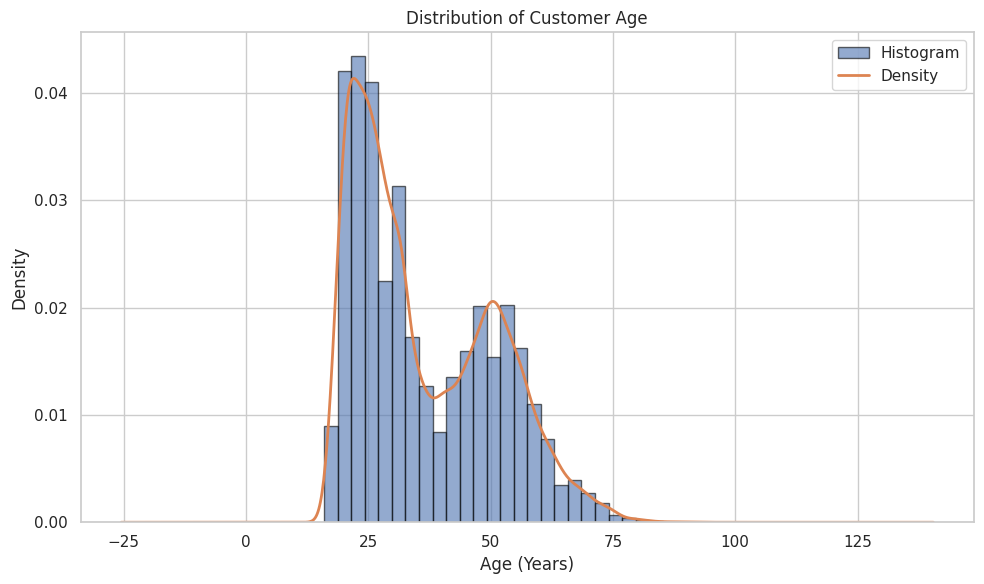

In [ ]:
# Histogram + density curve
fig, ax = plt.subplots(figsize=(10, 6))

customers_sample["age"].dropna().plot(
    kind="hist",
    bins=30,
    density=True,
    alpha=0.6,
    edgecolor="black",
    ax=ax,
    label="Histogram"
)

customers_sample["age"].dropna().plot(
    kind="kde",
    linewidth=2,
    ax=ax,
    label="Density"
)

ax.set_title("Distribution of Customer Age")
ax.set_xlabel("Age (Years)")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.show()

The age distribution is bimodal, assymetric.

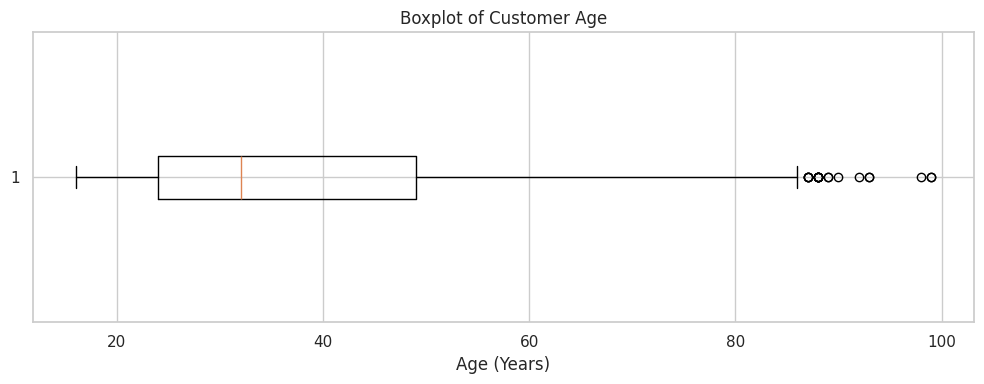

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.boxplot(
    customers_sample["age"].dropna(),
    vert=False
)

ax.set_title("Boxplot of Customer Age")
ax.set_xlabel("Age (Years)")

plt.tight_layout()
plt.show()

There are statistical outliers from the 90.

/tmp/ipykernel_1645/540823906.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


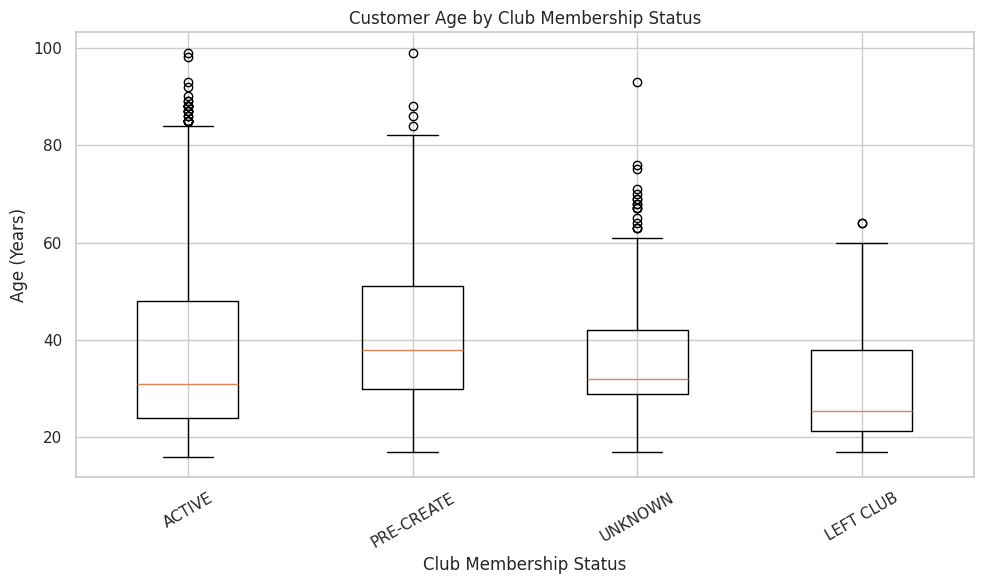

In [ ]:
membership_data = []

membership_labels = []

for category in customers_sample["club_member_status"].dropna().unique():

    values = customers_sample.loc[
        customers_sample["club_member_status"] == category,
        "age"
    ].dropna()

    if len(values) > 0:
        membership_data.append(values)
        membership_labels.append(str(category))


fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    membership_data,
    labels=membership_labels
)

ax.set_title("Customer Age by Club Membership Status")
ax.set_xlabel("Club Membership Status")
ax.set_ylabel("Age (Years)")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1645/2113857525.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


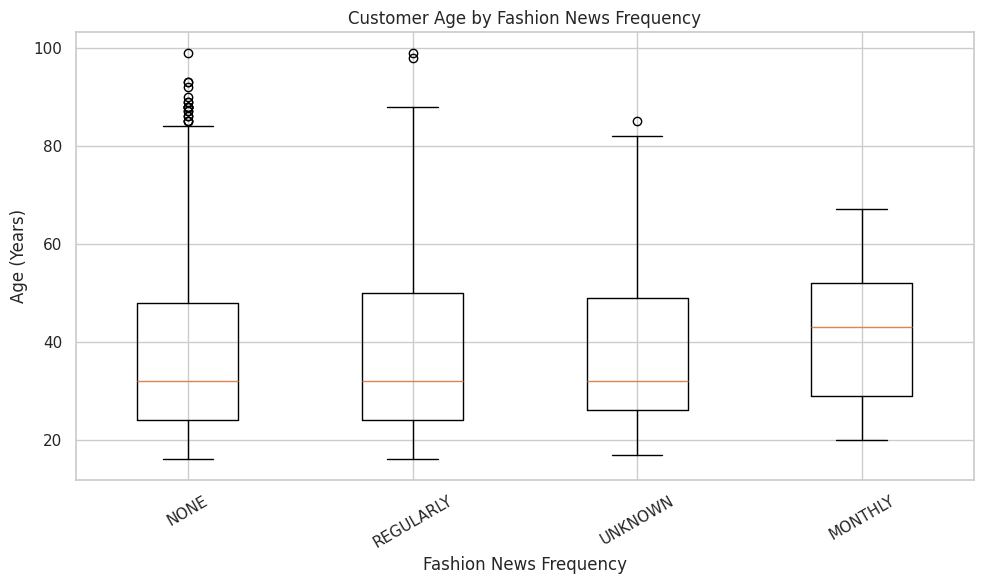

In [ ]:
news_data = []
news_labels = []

for category in customers_sample["fashion_news_frequency"].dropna().unique():

    values = customers_sample.loc[
        customers_sample["fashion_news_frequency"] == category,
        "age"
    ].dropna()

    if len(values) > 0:
        news_data.append(values)
        news_labels.append(str(category))


fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    news_data,
    labels=news_labels
)

ax.set_title(
    "Customer Age by Fashion News Frequency"
)

ax.set_xlabel("Fashion News Frequency")
ax.set_ylabel("Age (Years)")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# BAR PLOTS FOR CATEGORICAL VARIABLES

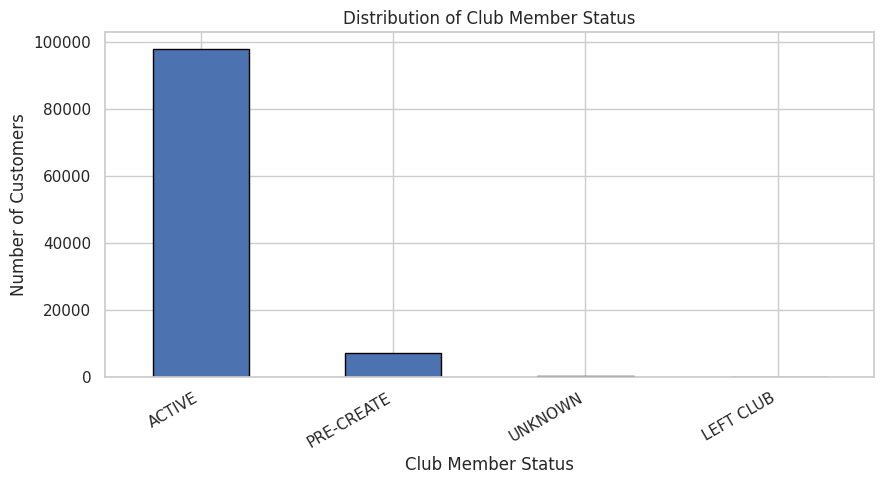

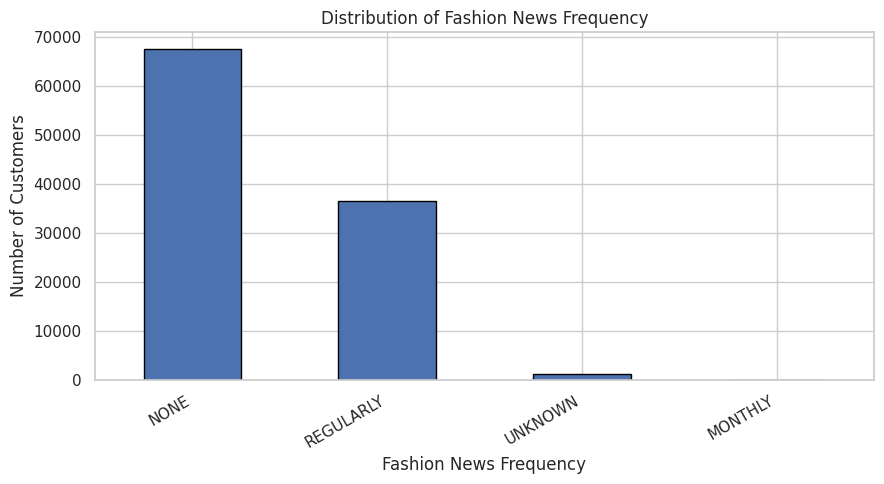

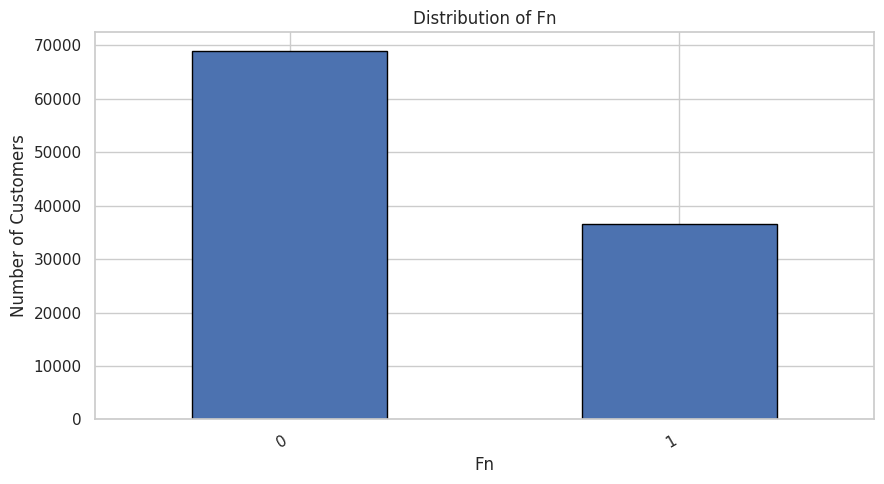

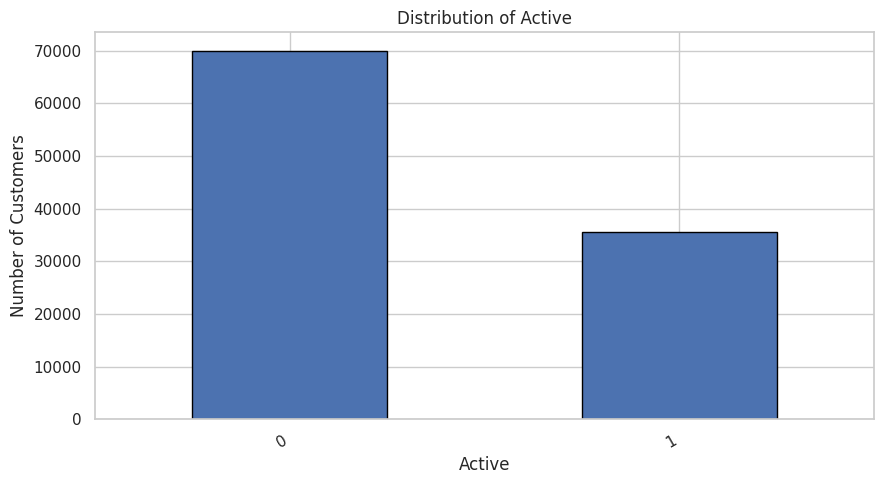

In [ ]:
categorical_cols = [
    "club_member_status",
    "fashion_news_frequency",
    "fn",
    "active"
]

for col in categorical_cols:

    counts = (
        customers_sample[col]
        .astype(str)
        .value_counts()
        .sort_values(ascending=False)
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    counts.plot(
        kind="bar",
        ax=ax,
        edgecolor="black"
    )

    ax.set_title(
        f"Distribution of {col.replace('_', ' ').title()}"
    )

    ax.set_xlabel(
        col.replace("_", " ").title()
    )

    ax.set_ylabel("Number of Customers")

    plt.xticks(rotation=30, ha="right")

    plt.tight_layout()
    plt.show()

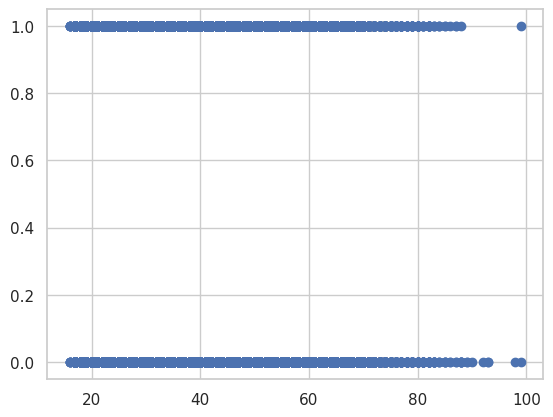

In [ ]:
plt.scatter(customers_sample["age"], customers_sample["active"])
plt.show()

# QQ PLOTS

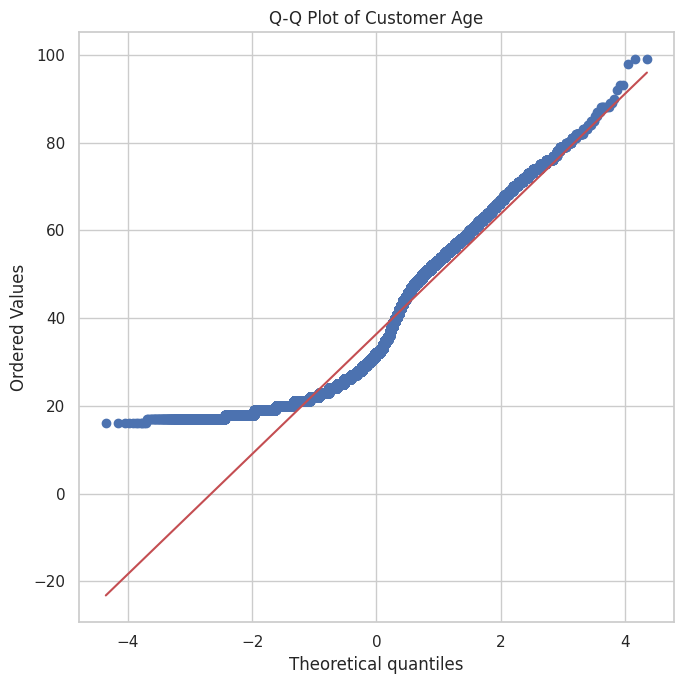

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))

stats.probplot(
    customers_sample["age"].dropna(),
    dist="norm",
    plot=ax
)

ax.set_title(
    "Q-Q Plot of Customer Age"
)

plt.tight_layout()
plt.show()

# VIOLATE PLOTS

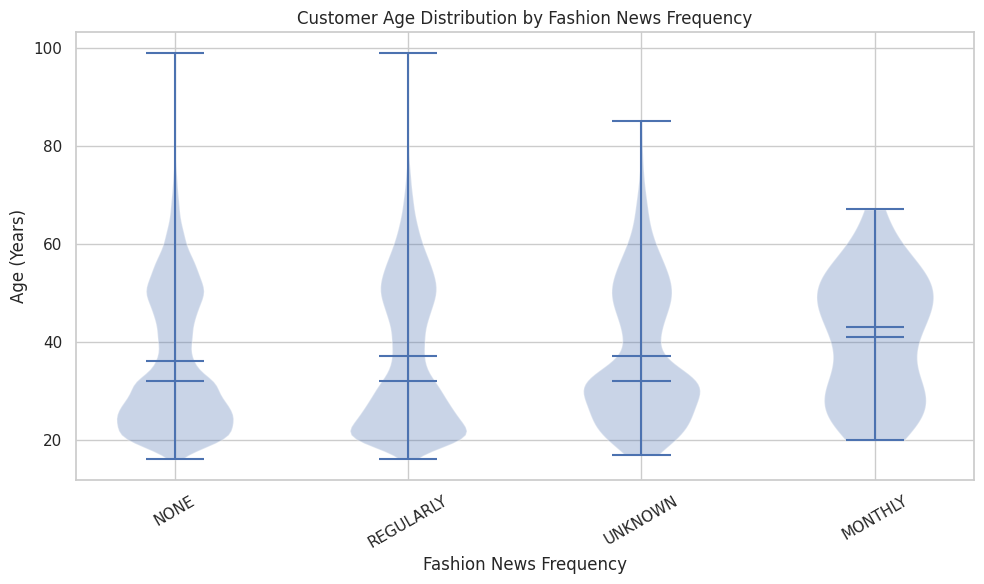

In [ ]:
categories = (
    customers_sample["fashion_news_frequency"]
    .dropna()
    .unique()
)

data = []
labels = []

for category in categories:

    ages = customers_sample.loc[
        customers_sample["fashion_news_frequency"] == category,
        "age"
    ].dropna()

    if len(ages) > 0:
        data.append(ages)
        labels.append(str(category))


fig, ax = plt.subplots(figsize=(10, 6))

ax.violinplot(
    data,
    showmeans=True,
    showmedians=True
)

ax.set_xticks(
    range(1, len(labels) + 1)
)

ax.set_xticklabels(
    labels,
    rotation=30
)

ax.set_title(
    "Customer Age Distribution by Fashion News Frequency"
)

ax.set_xlabel(
    "Fashion News Frequency"
)

ax.set_ylabel(
    "Age (Years)"
)

plt.tight_layout()
plt.show()

# CORRELATION AND RELATIONSHIPS

Correlation Matrix


,age,fn,active
age,1.000,0.034,0.037
fn,0.034,1.000,0.980
active,0.037,0.980,1.000


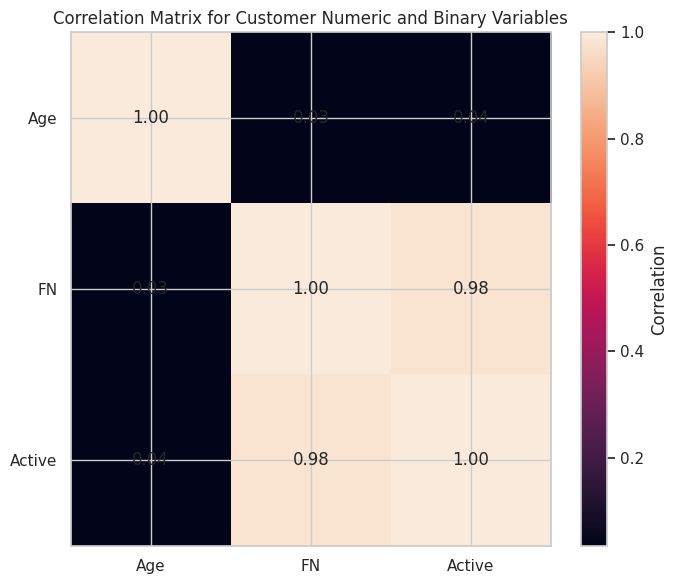

In [ ]:
corr_cols = ["age", "fn", "active"]

corr_matrix = customers_sample[corr_cols].corr(method="pearson")

print("Correlation Matrix")
display(corr_matrix.round(3))

# Heatmap without seaborn
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(corr_matrix, aspect="auto")

ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))

ax.set_xticklabels(
    [x.upper() if x in ["fn"] else x.title() for x in corr_cols]
)
ax.set_yticklabels(
    [x.upper() if x in ["fn"] else x.title() for x in corr_cols]
)

for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax, label="Correlation")

ax.set_title(
    "Correlation Matrix for Customer Numeric and Binary Variables"
)

plt.tight_layout()
plt.show()

# CHI-SQUARE TESTS BETWEEN CATEGORICAL

In [ ]:
#from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    customers_sample["club_member_status"],
    customers_sample["fashion_news_frequency"]
)

display(contingency_table)

chi2, p, dof, expected = chi2_contingency(
    contingency_table
)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p:.6g}")

fashion_news_frequency,MONTHLY,NONE,REGULARLY,UNKNOWN
club_member_status,,,,
ACTIVE,49,60751,36145,946
LEFT CLUB,0,42,0,0
PRE-CREATE,2,6526,438,172
UNKNOWN,0,303,27,141


Chi-square statistic: 6245.144
Degrees of freedom: 9
p-value: 0


In [ ]:
alpha = 0.05

if p < alpha:
    print(
        "Reject H0: evidence suggests an association "
        "between the variables."
    )
else:
    print(
        "Fail to reject H0: insufficient evidence "
        "of an association."
    )

Reject H0: evidence suggests an association between the variables.


In [ ]:
categorical_vars = [
    "club_member_status",
    "fashion_news_frequency",
    "fn",
    "active"
]

chi_square_results = []

for i in range(len(categorical_vars)):

    for j in range(i + 1, len(categorical_vars)):

        var1 = categorical_vars[i]
        var2 = categorical_vars[j]

        table = pd.crosstab(
            customers_sample[var1],
            customers_sample[var2]
        )

        chi2, p, dof, expected = chi2_contingency(table)

        chi_square_results.append({
            "variable_1": var1,
            "variable_2": var2,
            "chi_square": chi2,
            "degrees_of_freedom": dof,
            "p_value": p,
            "min_expected_frequency": expected.min()
        })


chi_square_df = pd.DataFrame(
    chi_square_results
)

display(
    chi_square_df.round(4)
)

,variable_1,variable_2,chi_square,degrees_of_freedom,p_value,min_expected_frequency
0,club_member_status,fashion_news_frequency,6245.1435,9,0.0,0.0203
1,club_member_status,fn,2989.4579,3,0.0,14.5489
2,club_member_status,active,2872.1233,3,0.0,14.1633
3,fashion_news_frequency,fn,104481.6611,3,0.0,17.6665
4,fashion_news_frequency,active,100512.6305,3,0.0,17.1983
5,fn,active,101317.0434,1,0.0,12328.8071


# CRAMER'S V FOR STRENGHT ASSOCIATION

In [ ]:
def cramers_v(x, y):

    table = pd.crosstab(x, y)

    chi2 = chi2_contingency(table)[0]

    n = table.to_numpy().sum()

    r, k = table.shape

    denominator = n * min(r - 1, k - 1)

    if denominator == 0:
        return np.nan

    return np.sqrt(
        chi2 / denominator
    )

In [ ]:
v = cramers_v(
    customers_sample["club_member_status"],
    customers_sample["fashion_news_frequency"]
)

print(
    f"Cramer's V = {v:.3f}"
)

Cramer's V = 0.140


There is a strong association between club_member_status and fashion_news_frequency

In [ ]:
cramers_results = []

for i in range(len(categorical_vars)):

    for j in range(i + 1, len(categorical_vars)):

        var1 = categorical_vars[i]
        var2 = categorical_vars[j]

        v = cramers_v(
            customers_sample[var1],
            customers_sample[var2]
        )

        cramers_results.append({
            "variable_1": var1,
            "variable_2": var2,
            "cramers_v": v
        })


cramers_df = pd.DataFrame(
    cramers_results
)

display(
    cramers_df.round(3)
)

,variable_1,variable_2,cramers_v
0,club_member_status,fashion_news_frequency,0.140
1,club_member_status,fn,0.168
2,club_member_status,active,0.165
3,fashion_news_frequency,fn,0.995
4,fashion_news_frequency,active,0.976
5,fn,active,0.980


We found strong association between the foloowing pairs (fashion_news_frequrncy, fn), (active, fashion_news_frequency), and (fn, active)

# CRAMER'S V ASSOCIATION MATRIX

In [ ]:
cramers_matrix = pd.DataFrame(
    index=categorical_vars,
    columns=categorical_vars,
    dtype=float
)

for var1 in categorical_vars:

    for var2 in categorical_vars:

        if var1 == var2:
            cramers_matrix.loc[var1, var2] = 1.0

        else:
            cramers_matrix.loc[var1, var2] = (
                cramers_v(
                    customers_sample[var1],
                    customers_sample[var2]
                )
            )


display(
    cramers_matrix.round(3)
)

,club_member_status,fashion_news_frequency,fn,active
club_member_status,1.000,0.140,0.168,0.165
fashion_news_frequency,0.140,1.000,0.995,0.976
fn,0.168,0.995,1.000,0.980
active,0.165,0.976,0.980,1.000


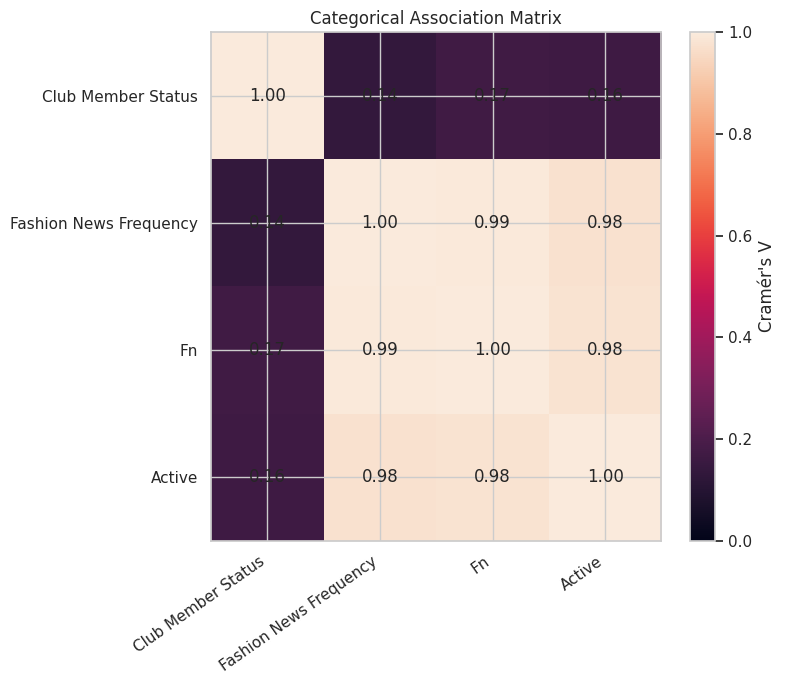

In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(
    cramers_matrix.astype(float),
    vmin=0,
    vmax=1,
    aspect="auto"
)

labels = [
    x.replace("_", " ").title()
    for x in categorical_vars
]

ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))

ax.set_xticklabels(
    labels,
    rotation=35,
    ha="right"
)

ax.set_yticklabels(labels)

for i in range(len(labels)):
    for j in range(len(labels)):

        value = cramers_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(
    im,
    ax=ax,
    label="Cramér's V"
)

ax.set_title(
    "Categorical Association Matrix"
)

plt.tight_layout()
plt.show()

# GROUPED SUMMARIES

In [ ]:
age_by_membership = (
    customers_sample.groupby(
        "club_member_status",
        observed=True
    )["age"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

display(age_by_membership)

,count,mean,median,std,min,max
club_member_status,,,,,,
ACTIVE,97891,36.08,31.0,14.29,16.0,99.0
LEFT CLUB,42,32.50,25.5,14.44,17.0,64.0
PRE-CREATE,7138,40.23,38.0,13.24,17.0,99.0
UNKNOWN,471,35.94,32.0,11.73,17.0,93.0


In [ ]:
age_by_news = (
    customers_sample.groupby(
        "fashion_news_frequency",
        observed=True
    )["age"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

display(age_by_news)

,count,mean,median,std,min,max
fashion_news_frequency,,,,,,
MONTHLY,51,40.88,43.0,12.72,20.0,67.0
NONE,67622,35.98,32.0,13.90,16.0,99.0
REGULARLY,36610,37.02,32.0,14.88,16.0,99.0
UNKNOWN,1259,37.18,32.0,13.72,17.0,85.0


# VARIANCE INFLATION FACTOR (VIF)

In [ ]:
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

# Select exploratory predictors
X = customers_sample[
    [
        "age",
        "fn",
        "active",
        "club_member_status",
        "fashion_news_frequency"
    ]
].copy()

# Dummy encode categorical variables
X = pd.get_dummies(
    X,
    columns=[
        "club_member_status",
        "fashion_news_frequency"
    ],
    drop_first=True,
    dtype=int
)

# Remove missing observations
X = X.dropna()

# Convert everything to numeric
X = X.astype(float)

vif_results = pd.DataFrame({
    "variable": X.columns,
    "VIF": [
        variance_inflation_factor(
            X.values,
            i
        )
        for i in range(X.shape[1])
    ]
})

display(
    vif_results
    .sort_values(
        "VIF",
        ascending=False
    )
    .round(3)
)

,variable,VIF
6,fashion_news_frequency_NONE,570.263
7,fashion_news_frequency_REGULARLY,469.631
1,fn,118.933
8,fashion_news_frequency_UNKNOWN,30.210
2,active,25.082
4,club_member_status_PRE-CREATE,1.035
5,club_member_status_UNKNOWN,1.034
0,age,1.008
3,club_member_status_LEFT CLUB,1.000


# TARGET VARIABLE ANALYSIS

There is no target variable

# FEATURE ENGINEERING

In [ ]:
# Preserve original age
customers_sample["age_original"] = customers_sample["age"]

# Create interpretable age groups
age_bins = [
    0,
    19,
    29,
    39,
    49,
    59,
    69,
    79,
    np.inf
]

age_labels = [
    "<20",
    "20-29",
    "30-39",
    "40-49",
    "50-59",
    "60-69",
    "70-79",
    "80+"
]

customers_sample["age_group"] = pd.cut(
    customers_sample["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

print(customers_sample["age_group"].value_counts().sort_index())

age_group
<20       5502
20-29    40642
30-39    19070
40-49    15804
50-59    17420
60-69     5661
70-79     1324
80+        119
Name: count, dtype: int64


# SCALE AGE VARIABLE

In [ ]:

scaler = StandardScaler()

customers_sample["age_scaled"] = scaler.fit_transform(
    customers_sample[["age"]]
)

display(
    customers_sample[
        [
            "age",
            "age_scaled"
        ]
    ].head()
)

,age,age_scaled
1134822,72.0,2.501178
612735,41.0,0.325664
1124456,22.0,-1.007716
662579,24.0,-0.867360
404009,56.0,1.378332


In [ ]:
print(
    customers_sample["age_scaled"].agg(
        ["mean", "std", "min", "max"]
    )
)

mean   -1.071112e-16
std     1.000005e+00
min    -1.428783e+00
max     4.395980e+00
Name: age_scaled, dtype: float64


Scaling customers age is not necessary for the LightGCN but auxilliary analysis

# ENCODE CATEGORICAL VARIABLES

In [ ]:
categorical_cols = [
    "club_member_status",
    "fashion_news_frequency",
    "age_group"
]

df_encoded = pd.get_dummies(
    customers_sample,
    columns=categorical_cols,
    drop_first=False,
    dtype=int
)

print(
    df_encoded.shape
)

display(
    df_encoded.head()
)

(105542, 30)


,customer_id,fn,active,age,postal_code,age_flag,age_iqr_outlier,age_group_Under 25,age_group_25-34,age_group_35-44,age_group_45-54,age_group_55+,age_original,age_scaled,club_member_status_ACTIVE,club_member_status_LEFT CLUB,club_member_status_PRE-CREATE,club_member_status_UNKNOWN,fashion_news_frequency_MONTHLY,fashion_news_frequency_NONE,fashion_news_frequency_REGULARLY,fashion_news_frequency_UNKNOWN,age_group_<20,age_group_20-29,age_group_30-39,age_group_40-49,age_group_50-59,age_group_60-69,age_group_70-79,age_group_80+
1134822,d3b658f59ad9bbf6249a7bf0db722f2f43cc47803d0329...,0,0,72.0,da477e6d8c015e8d89487ae038b1be611c052834008252...,False,False,0,0,0,0,1,72.0,2.501178,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
612735,72529945a566eb7445e51470ef00c5992976ddaf7d9f82...,0,0,41.0,c9d1dd747df26b6fd8a8d682f1f0ed3db12bfc7041e49a...,False,False,0,0,1,0,0,41.0,0.325664,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0
1124456,d1c91a9050fcb6da04f0643c6b6d38b002b6ff12d66e80...,0,0,22.0,760fd89d83df7842c04f3a6d68265270bc2333c43cabf7...,False,False,1,0,0,0,0,22.0,-1.007716,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0
662579,7bad01c1ad7a9bccc9270a29bf24279b4e19b41afc1b4a...,1,0,24.0,032fdbc74a7144e1bcbc2addc9d5c8a0d8f39223754aac...,False,False,1,0,0,0,0,24.0,-0.867360,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0
404009,4b889f848f59f9bf787b16626f96d0390c3f9ab3ed3edc...,0,0,56.0,a0f3f7d2ae3b89be98d44524b3a6743c1916986e507ef9...,False,False,0,0,0,0,1,56.0,1.378332,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0


# FINALE CHECK OF CUSTOMERS DATA

In [ ]:
print("=" * 70)
print("1. MISSING VALUE AUDIT")
print("=" * 70)

missing_report = pd.DataFrame({
    "missing_count": customers_sample.isna().sum(),
    "missing_percent": (
        customers_sample.isna().mean() * 100
    ).round(3)
})

display(
    missing_report.sort_values(
        "missing_count",
        ascending=False
    )
)

total_missing = customers_sample.isna().sum().sum()

print(
    f"\nTotal remaining missing values: "
    f"{total_missing:,}"
)

1. MISSING VALUE AUDIT


,missing_count,missing_percent
customer_id,0,0.0
fn,0,0.0
active,0,0.0
club_member_status,0,0.0
fashion_news_frequency,0,0.0
age,0,0.0
postal_code,0,0.0
age_flag,0,0.0
age_iqr_outlier,0,0.0
age_group,0,0.0



Total remaining missing values: 0


In [ ]:
print("=" * 70)
print("2. DATA TYPE VALIDATION")
print("=" * 70)

print(customers_sample.dtypes)

2. DATA TYPE VALIDATION
customer_id               string[python]
fn                                  int8
active                              int8
club_member_status              category
fashion_news_frequency          category
age                              float64
postal_code               string[python]
age_flag                            bool
age_iqr_outlier                     bool
age_group                       category
age_group_Under 25                 int64
age_group_25-34                    int64
age_group_35-44                    int64
age_group_45-54                    int64
age_group_55+                      int64
age_original                     float64
age_scaled                       float64
dtype: object


In [ ]:
customers_sample["customer_id"] = (
    customers_sample["customer_id"].astype("string")
)

customers_sample["postal_code"] = (
    customers_sample["postal_code"].astype("string")
)

customers_sample["fn"] = (
    pd.to_numeric(
        customers_sample["fn"],
        errors="raise"
    ).astype("int8")
)

customers_sample["active"] = (
    pd.to_numeric(
        customers_sample["active"],
        errors="raise"
    ).astype("int8")
)

customers_sample["age"] = pd.to_numeric(
    customers_sample["age"],
    errors="raise"
)

customers_sample["club_member_status"] = (
    customers_sample["club_member_status"]
    .astype("category")
)

customers_sample["fashion_news_frequency"] = (
    customers_sample["fashion_news_frequency"]
    .astype("category")
)

if "age_group" in customers_sample.columns:
    customers_sample["age_group"] = (
        customers_sample["age_group"]
        .astype("category")
    )

In [ ]:
print("=" * 70)
print("3. IDENTIFIER VALIDATION")
print("=" * 70)

print(
    "Rows:",
    f"{len(customers_sample):,}"
)

print(
    "Unique customer IDs:",
    f"{customers_sample['customer_id'].nunique():,}"
)

print(
    "Duplicate customer IDs:",
    f"{customers_sample['customer_id'].duplicated().sum():,}"
)

print(
    "Exact duplicate rows:",
    f"{customers_sample.duplicated().sum():,}"
)

3. IDENTIFIER VALIDATION
Rows: 105,542
Unique customer IDs: 105,542
Duplicate customer IDs: 0
Exact duplicate rows: 0


In [ ]:
print("=" * 70)
print("4. BINARY VARIABLE VALIDATION")
print("=" * 70)

for col in ["fn", "active"]:

    unique_values = sorted(
        customers_sample[col].dropna().unique()
    )

    print(
        f"{col}: {unique_values}"
    )

    assert set(unique_values).issubset(
        {0, 1}
    ), f"{col} contains values other than 0 and 1."

4. BINARY VARIABLE VALIDATION
fn: [np.int8(0), np.int8(1)]
active: [np.int8(0), np.int8(1)]


In [ ]:
print("=" * 70)
print("5. CATEGORICAL VALIDATION")
print("=" * 70)

categorical_cols = [
    "club_member_status",
    "fashion_news_frequency"
]

for col in categorical_cols:

    print(f"\n{col}")

    print(
        customers_sample[col]
        .value_counts(
            dropna=False
        )
    )

5. CATEGORICAL VALIDATION

club_member_status
club_member_status
ACTIVE        97891
PRE-CREATE     7138
UNKNOWN         471
LEFT CLUB        42
Name: count, dtype: int64

fashion_news_frequency
fashion_news_frequency
NONE         67622
REGULARLY    36610
UNKNOWN       1259
MONTHLY         51
Name: count, dtype: int64


In [ ]:
print("=" * 70)
print("6. AGE VALIDATION")
print("=" * 70)

print(
    customers_sample["age"].describe()
)

invalid_age = customers_sample[
    (customers_sample["age"] < 0) |
    (customers_sample["age"] > 110)
]

print(
    "\nPotentially invalid age records:",
    len(invalid_age)
)

6. AGE VALIDATION
count    105542.000000
mean         36.359449
std          14.249574
min          16.000000
25%          24.000000
50%          32.000000
75%          49.000000
max          99.000000
Name: age, dtype: float64

Potentially invalid age records: 0


In [ ]:
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print(
    f"Random seed: {RANDOM_SEED}"
)

Random seed: 42


In [ ]:
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(
        RANDOM_SEED
    )

In [ ]:
preprocessing_config = {

    "random_seed": 42,

    "customer_id_type": "string",

    "postal_code_type": "string",

    "age_missing_strategy":
        "median",

    "categorical_missing_strategy":
        "UNKNOWN",

    "fn_missing_strategy":
        "0_after_schema_validation",

    "active_missing_strategy":
        "0_after_schema_validation",

    "duplicate_strategy":
        "remove_exact_duplicates",

    "age_outlier_strategy":
        "flag_do_not_automatically_remove",

    "split_strategy":
        "temporal",

    "cold_start_definition":
        "training_interaction_count_only"
}

In [ ]:

with open(
    "preprocessing_config.json",
    "w"
) as f:

    json.dump(
        preprocessing_config,
        f,
        indent=4
    )

In [ ]:

joblib.dump(
    scaler,
    "age_scaler.joblib"
)

['age_scaler.joblib']

In [ ]:
customers_sample.to_csv(
    "customers_clean.csv",
    index=False
)

In [ ]:
customers_sample.to_parquet(
    "customers_clean.parquet",
    index=False
)

In [ ]:
validation_report = {
    "number_of_rows":
        len(customers_sample),

    "number_of_columns":
        customers_sample.shape[1],

    "unique_customers":
        customers_sample["customer_id"].nunique(),

    "duplicate_customer_ids":
        int(
            customers_sample["customer_id"]
            .duplicated()
            .sum()
        ),

    "duplicate_rows":
        int(
            customers_sample.duplicated().sum()
        ),

    "remaining_missing_values":
        int(
            customers_sample.isna().sum().sum()
        ),

    "minimum_age":
        float(customers_sample["age"].min()),

    "maximum_age":
        float(customers_sample["age"].max()),

    "random_seed":
        RANDOM_SEED
}

validation_report

{'number_of_rows': 105542,
 'number_of_columns': 17,
 'unique_customers': 105542,
 'duplicate_customer_ids': 0,
 'duplicate_rows': 0,
 'remaining_missing_values': 0,
 'minimum_age': 16.0,
 'maximum_age': 99.0,
 'random_seed': 42}

In [ ]:
with open(
    "customers_validation_report.json",
    "w"
) as f:

    json.dump(
        validation_report,
        f,
        indent=4
    )

# EXPLORATORY DATA ANALYSIS OF TRANSACTIONS_TRAIN DATA

In [ ]:
# Specify the filename you want to load
file_name = 'H&M Datasets/transactions_train_sample.csv'
file_path = os.path.join('/content/drive/My Drive', file_name)

try:
    # Load the dataset
    transactions_df = pd.read_csv(file_path)
    print(f"Successfully loaded {file_name}!")
    print(f"Dataset Shape: {transactions_df.shape}")
    display(transactions_df.head())
except Exception as e:
    print(f"Error loading file: {e}")

Successfully loaded H&M Datasets/transactions_train_sample.csv!
Dataset Shape: (105855, 5)


,t_dat,customer_id,article_id,price,sales_channel_id
0,2019-09-13,215895f90002eb3d1a04bd603513c8e85e6002ef08f136...,786586001,0.022017,1
1,2019-02-23,7b183268e3a4623b80d5325ec4a20a0af0edff7bcb1748...,658911001,0.028797,2
2,2019-07-17,2eb7412239a90c0570cd3d1bf0492856ae5b59058b1ea6...,759326005,0.050831,2
3,2019-05-16,74f162e5a170fd57207aa2a7d5c58479ee9de903b2a277...,737137004,0.027102,1
4,2019-08-10,aab9306ee28c4db494003955f80355e540b01480ab35cf...,785931001,0.050831,2


# DATA CLEANING

In [ ]:
import pandas as pd

print("=" * 70)
print("TRANSACTIONS DATASET — STRUCTURE")
print("=" * 70)

# Shape
print(f"\nDataset shape: {transactions_df.shape}")
print(f"Number of rows: {transactions_df.shape[0]:,}")
print(f"Number of columns: {transactions_df.shape[1]}")

# First five observations
print("\nFirst 5 rows:")
display(transactions_df.head())

# Column names
print("\nColumn names:")
print(transactions_df.columns.tolist())

# Dataset information
print("\nDataset information:")
transactions_df.info()

# Summary statistics
print("\nSummary statistics:")
display(
    transactions_df.describe(include="all").T
)

TRANSACTIONS DATASET — STRUCTURE

Dataset shape: (105855, 5)
Number of rows: 105,855
Number of columns: 5

First 5 rows:


,t_dat,customer_id,article_id,price,sales_channel_id
0,2019-09-13,215895f90002eb3d1a04bd603513c8e85e6002ef08f136...,786586001,0.022017,1
1,2019-02-23,7b183268e3a4623b80d5325ec4a20a0af0edff7bcb1748...,658911001,0.028797,2
2,2019-07-17,2eb7412239a90c0570cd3d1bf0492856ae5b59058b1ea6...,759326005,0.050831,2
3,2019-05-16,74f162e5a170fd57207aa2a7d5c58479ee9de903b2a277...,737137004,0.027102,1
4,2019-08-10,aab9306ee28c4db494003955f80355e540b01480ab35cf...,785931001,0.050831,2



Column names:
['t_dat', 'customer_id', 'article_id', 'price', 'sales_channel_id']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105855 entries, 0 to 105854
Data columns (total 5 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   t_dat             105855 non-null  object 
 1   customer_id       105855 non-null  object 
 2   article_id        105855 non-null  int64  
 3   price             105855 non-null  float64
 4   sales_channel_id  105855 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
t_dat,105855,734,2019-09-28,685,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,105855,92879,e6498c7514c61d3c24669f49753dc83fdff3ec1ba13902...,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
article_id,105855.0,NaN,NaN,NaN,696748115.080506,132895069.014874,108775015.0,633130015.5,714790020.0,786747002.0,956217002.0
price,105855.0,NaN,NaN,NaN,0.027811,0.019069,0.000322,0.015847,0.025407,0.033881,0.422034
sales_channel_id,105855.0,NaN,NaN,NaN,1.703746,0.456607,1.0,1.0,2.0,2.0,2.0


The transaction sample contained 105,855 observations and five variables: transaction date (t_dat), customer identifier (customer_id), article identifier (article_id), price (price), and sales channel identifier (sales_channel_id). The sample represented 92,879 unique customers and 35,631 unique articles. Initial inspection showed that the transaction date was stored as an object rather than a datetime variable, while article and sales-channel identifiers were represented numerically. These datatype issues were flagged for subsequent validation and conversion.

# CHECK AND HANDLE MISSING VALUES

In [ ]:
for column in transactions_df.columns:
    missing = transactions_df[column].isnull().sum()
    percent = transactions_df[column].isnull().mean() * 100

    print(
        f"{column:<20} "
        f"Missing: {missing:>6,} "
        f"({percent:.2f}%)"
    )

t_dat                Missing:      0 (0.00%)
customer_id          Missing:      0 (0.00%)
article_id           Missing:      0 (0.00%)
price                Missing:      0 (0.00%)
sales_channel_id     Missing:      0 (0.00%)


No missing observations were identified for transaction date, customer identifier, article identifier, price, or sales channel identifier. Therefore, no observations will be removed and no missing-value imputation procedures are required.

In [ ]:

# DATA TYPE VALIDATION

print("=" * 70)
print("DATA TYPE VALIDATION")
print("=" * 70)

print("\nCurrent data types:")
print(transactions_df.dtypes)

DATA TYPE VALIDATION

Current data types:
t_dat                object
customer_id          object
article_id            int64
price               float64
sales_channel_id      int64
dtype: object


#  DATA TYPE CONVERSION

In [ ]:
transactions_df["t_dat"] = pd.to_datetime(
    transactions_df["t_dat"],
    errors="coerce"
)

In [ ]:
print("t_dat type:", transactions_df["t_dat"].dtype)

print(
    "Invalid dates after conversion:",
    transactions_df["t_dat"].isna().sum()
)

print(
    "Date range:",
    transactions_df["t_dat"].min(),
    "to",
    transactions_df["t_dat"].max()
)

t_dat type: datetime64[ns]
Invalid dates after conversion: 0
Date range: 2018-09-20 00:00:00 to 2020-09-22 00:00:00


In [ ]:
# Convert customer_id and article_id to string
transactions_df["customer_id"] = (
    transactions_df["customer_id"]
    .astype("string")
)

transactions_df["article_id"] = (
    transactions_df["article_id"]
    .astype("string")

)

In [ ]:
print(
    "customer_id:",
    transactions_df["customer_id"].dtype
)

print(
    "article_id:",
    transactions_df["article_id"].dtype
)

customer_id: string
article_id: string


# VALIDATE PRICE AS NUMERIC

In [ ]:
transactions_df["price"] = pd.to_numeric(
    transactions_df["price"],
    errors="coerce"
)

print(
    "price type:",
    transactions_df["price"].dtype
)

print(
    "Invalid prices:",
    transactions_df["price"].isna().sum()
)

price type: float64
Invalid prices: 0


# CONVERT SALE CHANNEL TO CATEGORICAL

In [ ]:
transactions_df["sales_channel_id"] = (
    transactions_df["sales_channel_id"]
    .astype("category")
)

print(transactions_df["sales_channel_id"].value_counts())

sales_channel_id
2    74495
1    31360
Name: count, dtype: int64


There are 74495 sales for channel id #2 and 31360 for channel id #1

In [ ]:
print("=" * 70)
print("FINAL DATA TYPES")
print("=" * 70)

print(transactions_df.dtypes)

FINAL DATA TYPES
t_dat               datetime64[ns]
customer_id         string[python]
article_id          string[python]
price                      float64
sales_channel_id          category
dtype: object


In [ ]:
transactions_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105855 entries, 0 to 105854
Data columns (total 5 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   t_dat             105855 non-null  datetime64[ns]
 1   customer_id       105855 non-null  string        
 2   article_id        105855 non-null  string        
 3   price             105855 non-null  float64       
 4   sales_channel_id  105855 non-null  category      
dtypes: category(1), datetime64[ns](1), float64(1), string(2)
memory usage: 3.3 MB


# Checking that price column has only numeric values

In [ ]:

print("=" * 70)
print("NUMERIC DATA VALIDATION")
print("=" * 70)

# Convert price temporarily to numeric
price_numeric = pd.to_numeric(
    transactions_df["price"],
    errors="coerce"
)

# Identify values that could not be converted
invalid_price_mask = (
    price_numeric.isna() &
    transactions_df["price"].notna()
)

invalid_prices = transactions_df.loc[
    invalid_price_mask,
    "price"
]

print(
    f"Non-numeric price entries: "
    f"{invalid_price_mask.sum():,}"
)

if invalid_price_mask.sum() > 0:
    print("\nInvalid price values:")
    print(invalid_prices.unique())
else:
    print(
        "All price values are valid numeric entries."
    )

NUMERIC DATA VALIDATION
Non-numeric price entries: 0
All price values are valid numeric entries.


In [ ]:

infinite_prices = np.isinf(
    transactions_df["price"]
).sum()

print(
    f"Infinite price values: "
    f"{infinite_prices:,}"
)

Infinite price values: 0


In [ ]:
zero_prices = (
    transactions_df["price"] == 0
).sum()

negative_prices = (
    transactions_df["price"] < 0
).sum()

print(
    f"Zero prices: {zero_prices:,}"
)

print(
    f"Negative prices: {negative_prices:,}"
)

Zero prices: 0
Negative prices: 0


In [ ]:
print("\nPrice summary:")

display(
    transactions_df["price"]
    .describe()
    .to_frame()
)


Price summary:


,price
count,105855.000000
mean,0.027811
std,0.019069
min,0.000322
25%,0.015847
50%,0.025407
75%,0.033881
max,0.422034


In [ ]:
numeric_validation = pd.DataFrame({
    "Check": [
        "Missing values",
        "Non-numeric values",
        "Infinite values",
        "Zero values",
        "Negative values"
    ],

    "Count": [
        transactions_df["price"].isna().sum(),
        invalid_price_mask.sum(),
        np.isinf(transactions_df["price"]).sum(),
        (transactions_df["price"] == 0).sum(),
        (transactions_df["price"] < 0).sum()
    ]
})

display(numeric_validation)

,Check,Count
0,Missing values,0
1,Non-numeric values,0
2,Infinite values,0
3,Zero values,0
4,Negative values,0


# OUTLIER DECTECTION

In [ ]:
print("=" * 70)
print("PRICE OUTLIER ANALYSIS — IQR METHOD")
print("=" * 70)

# Calculate quartiles
Q1 = transactions_df["price"].quantile(0.25)
Q3 = transactions_df["price"].quantile(0.75)

# Interquartile range
IQR = Q3 - Q1

# Outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1:          {Q1:.6f}")
print(f"Q3:          {Q3:.6f}")
print(f"IQR:         {IQR:.6f}")
print(f"Lower bound: {lower_bound:.6f}")
print(f"Upper bound: {upper_bound:.6f}")

PRICE OUTLIER ANALYSIS — IQR METHOD
Q1:          0.015847
Q3:          0.033881
IQR:         0.018034
Lower bound: -0.011203
Upper bound: 0.060932


In [ ]:
price_outliers = transactions_df[
    (transactions_df["price"] < lower_bound) |
    (transactions_df["price"] > upper_bound)
].copy()

print(
    f"\nNumber of price outliers: "
    f"{len(price_outliers):,}"
)

print(
    f"Percentage of observations: "
    f"{len(price_outliers) / len(transactions_df) * 100:.2f}%"
)

display(
    price_outliers[
        [
            "t_dat",
            "customer_id",
            "article_id",
            "price",
            "sales_channel_id"
        ]
    ].sort_values(
        "price",
        ascending=False
    ).head(20)
)


Number of price outliers: 5,117
Percentage of observations: 4.83%


,t_dat,customer_id,article_id,price,sales_channel_id
102575,2019-02-07,6d8e62e0b7c7dcf9d43b46d8b022d5a8fb71dddab299a7...,738399001,0.422034,2
103328,2019-01-02,e7c45afd3636721cbae4a6c39af1b2d30e851572762ce8...,703729001,0.337288,2
1460,2018-10-25,03ee19a182423837c922df42fffbce6c22335d5fe07b9d...,679086001,0.337288,2
59601,2019-09-05,f54dd048696162c2f8a105a4357091345d81c4ca84c1cb...,789374001,0.337288,2
59938,2018-09-23,b52015b459f45ad86a2f21ce7e1c855675ec2a1d4e30ab...,685378002,0.337288,2
88666,2019-10-08,de0afaf70b55d40ffe9c8580842de729f704917d8b4528...,804010001,0.323729,2
60860,2020-08-31,0bc8c415b8299bf631c43f2e49d0f16182b34225c5b5d3...,876342001,0.303390,2
43418,2019-10-22,24830973f1949bcf67bcc162595c31068efc7868cb73a3...,639338001,0.274559,2
99396,2019-11-11,bc58025415cb4958f1b647016c3a0ccb8e28fbc52fdbb6...,816350001,0.270017,2
12518,2018-10-11,6c93490f5ea3f3e572ba60ba67e0ecde04809911a926e8...,679086001,0.269847,2


4.83% (5,117) price observations are outside the IQR boundaries

In [ ]:
# plt.figure(figsize=(10, 4))

# plt.boxplot(
#     transactions_df["price"],
#     vert=False
# )

# plt.xlabel("Price")
# plt.title("Boxplot of Transaction Price")

# plt.show()

In [ ]:
# display(
#     transactions_df.nlargest(
#         20,
#         "price"
#     )[
#         [
#             "t_dat",
#             "customer_id",
#             "article_id",
#             "price",
#             "sales_channel_id"
#         ]
#     ]
# )

In [ ]:
print(
    "Minimum price:",
    transactions_df["price"].min()
)

print(
    "Maximum price:",
    transactions_df["price"].max()
)

print(
    "Median price:",
    transactions_df["price"].median()
)

Minimum price: 0.000322033898305
Maximum price: 0.4220338983050847
Median price: 0.0254067796610169


In [ ]:
transactions_df["price_outlier"] = (
    (transactions_df["price"] < lower_bound) |
    (transactions_df["price"] > upper_bound)
)

print(
    transactions_df[
        "price_outlier"
    ].value_counts()
)

price_outlier
False    100738
True       5117
Name: count, dtype: int64


In [ ]:
# plt.figure(figsize=(10, 4))

# plt.boxplot(
#     transactions_df["price"],
#     vert=False
# )

# plt.xlabel("Price")
# plt.title("Boxplot of Transaction Price")

# plt.show()

In [ ]:
outlier_summary = (
    transactions_df
    .groupby("price_outlier", observed=True)["price"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
)

display(outlier_summary)

,count,mean,median,min,max
price_outlier,,,,,
False,100738,0.024928,0.023992,0.000322,0.060661
True,5117,0.084581,0.068627,0.060932,0.422034


- Potential outliers in the transaction price variable were evaluated using the interquartile range (IQR) method.
- Observations below \(Q_1-1.5(IQR)\) or above \(Q_3+1.5(IQR)\) were flagged as potential outliers.
- Approximately 4.83% of the transaction-price observations were identified as potential outliers. Because these observations represented plausible transaction values rather than confirmed data-entry errors, they were retained in the dataset and flagged for descriptive analysis.
- No outlier analysis was applied to customer identifiers, article identifiers, transaction dates, or sales-channel identifiers because these variables do not represent continuous quantitative measurements.

# CHECKING FOR DUPLICATES

In [ ]:
print("=" * 70)
print("DUPLICATE ROW ANALYSIS")
print("=" * 70)

duplicate_count = transactions_df.duplicated().sum()

duplicate_percent = (
    duplicate_count / len(transactions_df)
) * 100

print(
    f"Exact duplicate rows: {duplicate_count:,}"
)

print(
    f"Percentage of dataset: {duplicate_percent:.4f}%")

DUPLICATE ROW ANALYSIS
Exact duplicate rows: 52
Percentage of dataset: 0.0491%


There are 52 records are exact duplicates rows

In [ ]:
# original_columns = [
#     "t_dat",
#     "customer_id",
#     "article_id",
#     "price",
#     "sales_channel_id"
# ]

# duplicate_count = transactions_df.duplicated(
#     subset=original_columns
# ).sum()

# print(
#     f"Exact duplicate transaction rows: "
#     f"{duplicate_count:,}"
# )

In [ ]:
duplicate_rows = transactions_df[
    transactions_df.duplicated(
        subset=original_columns,
        keep=False
    )
].sort_values(
    [
        "customer_id",
        "t_dat",
        "article_id"
    ]
)

print(
    f"Rows involved in duplicate groups: "
    f"{len(duplicate_rows):,}"
)

display(
    duplicate_rows.head(30)
)

Rows involved in duplicate groups: 101


,t_dat,customer_id,article_id,price,sales_channel_id,price_outlier
11992,2018-10-04,02035affa6fdb32e2d3fccd02585780df8665e51bfb5f2...,626463002,0.050831,2,False
55089,2018-10-04,02035affa6fdb32e2d3fccd02585780df8665e51bfb5f2...,626463002,0.050831,2,False
24038,2020-04-20,0616a3390852664122ea2acd8a37998500a1581b53682f...,834258003,0.025407,2,False
87157,2020-04-20,0616a3390852664122ea2acd8a37998500a1581b53682f...,834258003,0.025407,2,False
43129,2020-08-15,0b30aeb023f3f10fd215c72a22afd0704b81f238764998...,717490058,0.007610,1,False
90092,2020-08-15,0b30aeb023f3f10fd215c72a22afd0704b81f238764998...,717490058,0.007610,1,False
8219,2020-06-10,0e22177e456fcb18867563cc168b4e3a8a6c15a560b12c...,854193002,0.016932,2,False
47993,2020-06-10,0e22177e456fcb18867563cc168b4e3a8a6c15a560b12c...,854193002,0.016932,2,False
63701,2019-04-20,10917d28ad29d3e27ae7f37bbe56c4c75664aae04e8ca7...,757741005,0.025407,2,False
88856,2019-04-20,10917d28ad29d3e27ae7f37bbe56c4c75664aae04e8ca7...,757741005,0.025407,2,False


In [ ]:
duplicate_groups = (
    transactions_df
    .groupby(
        original_columns,
        observed=True
    )
    .size()
    .reset_index(
        name="occurrence_count"
    )
)

duplicate_groups = duplicate_groups[
    duplicate_groups["occurrence_count"] > 1
].sort_values(
    "occurrence_count",
    ascending=False
)

display(
    duplicate_groups.head(20)
)

,t_dat,customer_id,article_id,price,sales_channel_id,occurrence_count
3934,2018-10-14,d00063b94dcb1342869d4994844a2742b5d62927f36843...,678342001,0.006763,1,4
66615,2019-12-12,48f1a0e2ad0c50d9c12a61fcbbec84fba2ebc5c2835ce5...,842605001,0.025407,2,3
705,2018-09-24,f7d1d14bce7a653ca3d8a32cd9b0ea01286b5c90467470...,685687002,0.016932,2,2
7171,2018-11-05,5f0c728a33c0c3f54df560a2d83337a3d2220eb44765df...,638899001,0.050831,2,2
2358,2018-10-04,02035affa6fdb32e2d3fccd02585780df8665e51bfb5f2...,626463002,0.050831,2,2
8368,2018-11-15,d88a4c452a4984ef9ebef0d10658c71dd09d7680a93b49...,189634001,0.010153,2,2
12663,2018-12-17,44a01e8a2a7971e5c52ec5735a6fc0c48da4feb246e94d...,513373008,0.042356,2,2
16244,2019-01-12,c3aa498222b9405b5d5b3ab234f6d5fa315bb1597cd7ba...,635741001,0.005068,2,2
7675,2018-11-09,d94c5bd13e28e57c008b41fb89417e767c47cf73da78de...,452618001,0.005814,1,2
17566,2019-01-23,602f7ee0bfe17eae08d42c376e84e1274dea6cf916ff70...,626415002,0.013542,2,2


How do we identify true duplicates and legitimate repeated purchase.

In [ ]:
user_item_counts = (
    transactions_df
    .groupby(
        [
            "customer_id",
            "article_id"
        ],
        observed=True
    )
    .size()
    .reset_index(
        name="interaction_count"
    )
)

repeated_user_item = user_item_counts[
    user_item_counts["interaction_count"] > 1
]

print(
    "Customer-article pairs with "
    "multiple interactions:",
    f"{len(repeated_user_item):,}"
)

display(
    repeated_user_item
    .sort_values(
        "interaction_count",
        ascending=False
    )
    .head(20)
)

Customer-article pairs with multiple interactions: 78


,customer_id,article_id,interaction_count
85973,d00063b94dcb1342869d4994844a2742b5d62927f36843...,678342001,4
30165,48f1a0e2ad0c50d9c12a61fcbbec84fba2ebc5c2835ce5...,842605001,3
2521,0616a3390852664122ea2acd8a37998500a1581b53682f...,834258003,2
4663,0b30aeb023f3f10fd215c72a22afd0704b81f238764998...,717490058,2
681,018a5c1f32a98a30774db77dfad91c78493e7be2e05589...,686353001,2
890,02035affa6fdb32e2d3fccd02585780df8665e51bfb5f2...,626463002,2
5941,0e22177e456fcb18867563cc168b4e3a8a6c15a560b12c...,854193002,2
6946,10917d28ad29d3e27ae7f37bbe56c4c75664aae04e8ca7...,757741005,2
9481,16e1b5de4af51734ad7e2f512debf59a38301c1af142a2...,772864001,2
12293,1d896be4a8dfb7bb435d8575ac0efbe757c991390565a0...,399256005,2


Building interaction edges to find how often does the same customer interact with the same article more than once?

In [ ]:
interaction_edges = (
    transactions_df[
        [
            "customer_id",
            "article_id"
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print(
    "Raw transactions:",
    f"{len(transactions_df):,}"
)

print(
    "Unique user-item edges:",
    f"{len(interaction_edges):,}"
)

Raw transactions: 105,855
Unique user-item edges: 105,774


# DESCRIPTIVE STATISTICS

In [ ]:
print("=" * 70)
print("NUMERIC SUMMARY STATISTICS")
print("=" * 70)

price_summary = pd.DataFrame({
    "Count": [transactions_df["price"].count()],
    "Mean": [transactions_df["price"].mean()],
    "Median": [transactions_df["price"].median()],
    "Standard_Deviation": [transactions_df["price"].std()],
    "Variance": [transactions_df["price"].var()],
    "Minimum": [transactions_df["price"].min()],
    "Q1": [transactions_df["price"].quantile(0.25)],
    "Q3": [transactions_df["price"].quantile(0.75)],
    "Maximum": [transactions_df["price"].max()],
    "Range": [
        transactions_df["price"].max()
        - transactions_df["price"].min()
    ],
    "IQR": [
        transactions_df["price"].quantile(0.75)
        - transactions_df["price"].quantile(0.25)
    ]
}, index=["Price"])

display(price_summary.round(6))

NUMERIC SUMMARY STATISTICS


,Count,Mean,Median,Standard_Deviation,Variance,Minimum,Q1,Q3,Maximum,Range,IQR
Price,105855,0.027811,0.025407,0.019069,0.000364,0.000322,0.015847,0.033881,0.422034,0.421712,0.018034


In [ ]:
transaction_summary = pd.DataFrame({
    "Metric": [
        "Total transactions",
        "Unique customers",
        "Unique articles",
        "Unique transaction dates",
        "Sales channels"
    ],
    "Value": [
        len(transactions_df),
        transactions_df["customer_id"].nunique(),
        transactions_df["article_id"].nunique(),
        transactions_df["t_dat"].nunique(),
        transactions_df["sales_channel_id"].nunique()
    ]
})

display(transaction_summary)

,Metric,Value
0,Total transactions,105855
1,Unique customers,92879
2,Unique articles,35631
3,Unique transaction dates,734
4,Sales channels,2


In [ ]:
print("=" * 70)
print("SALES CHANNEL FREQUENCY TABLE")
print("=" * 70)

sales_channel_frequency = (
    transactions_df["sales_channel_id"]
    .value_counts(dropna=False)
    .rename_axis("sales_channel_id")
    .reset_index(name="frequency")
)

# Add percentage
sales_channel_frequency["percentage"] = (
    sales_channel_frequency["frequency"]
    / len(transactions_df)
    * 100
)

# Add cumulative percentage
sales_channel_frequency["cumulative_percentage"] = (
    sales_channel_frequency["percentage"]
    .cumsum()
)

display(
    sales_channel_frequency.round(2)
)

SALES CHANNEL FREQUENCY TABLE


,sales_channel_id,frequency,percentage,cumulative_percentage
0,2,74495,70.37,70.37
1,1,31360,29.63,100.00


In [ ]:
print(
    transactions_df["sales_channel_id"]
    .value_counts(
        normalize=True,
        dropna=False
    )
    .mul(100)
    .round(2)
)

sales_channel_id
2    70.37
1    29.63
Name: proportion, dtype: float64


Channel 2 accounts for more than twice as many transactions as channel 1.

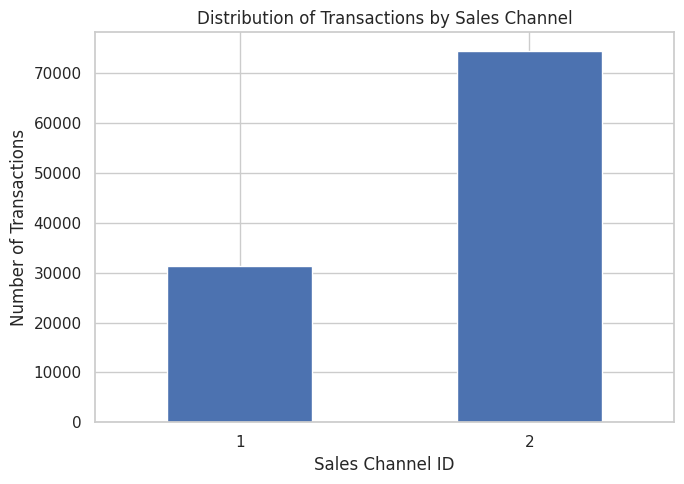

In [ ]:
channel_counts = (
    transactions_df["sales_channel_id"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7, 5))

channel_counts.plot(
    kind="bar"
)

plt.title("Distribution of Transactions by Sales Channel")
plt.xlabel("Sales Channel ID")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

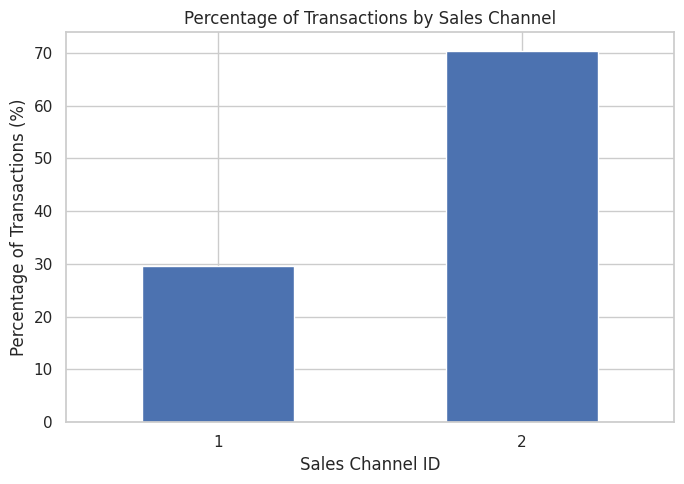

In [ ]:
channel_percent = (
    transactions_df["sales_channel_id"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

plt.figure(figsize=(7, 5))

channel_percent.plot(
    kind="bar"
)

plt.title("Percentage of Transactions by Sales Channel")
plt.xlabel("Sales Channel ID")
plt.ylabel("Percentage of Transactions (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# Transactions per customer
customer_frequency = (
    transactions_df["customer_id"]
    .value_counts()
)

# Transactions per article
article_frequency = (
    transactions_df["article_id"]
    .value_counts()
)

print("Transactions per customer:")
display(customer_frequency.describe())

print("\nTransactions per article:")
display(article_frequency.describe())

Transactions per customer:


,count
count,92879.0
mean,1.139709
std,0.429047
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,10.0



Transactions per article:


,count
count,35631.0
mean,2.970868
std,4.181551
min,1.0
25%,1.0
50%,2.0
75%,3.0
max,156.0


# SKEWNESS AND KURTOSIS

In [ ]:
print("=" * 70)
print("PRICE DISTRIBUTION SHAPE")
print("=" * 70)

price_skewness = transactions_df["price"].skew()
price_kurtosis = transactions_df["price"].kurt()

print(f"Skewness: {price_skewness:.4f}")
print(f"Kurtosis: {price_kurtosis:.4f}")

PRICE DISTRIBUTION SHAPE
Skewness: 2.9245
Kurtosis: 20.4221


In [ ]:
distribution_shape = pd.DataFrame({
    "Variable": ["price"],
    "Skewness": [price_skewness],
    "Excess_Kurtosis": [price_kurtosis]
})

display(
    distribution_shape.round(4)
)

,Variable,Skewness,Excess_Kurtosis
0,price,2.9245,20.4221


In [ ]:
mean_price = transactions_df["price"].mean()
median_price = transactions_df["price"].median()

print(f"Mean price:   {mean_price:.6f}")
print(f"Median price: {median_price:.6f}")
print(
    f"Mean - Median: "
    f"{mean_price - median_price:.6f}"
)

Mean price:   0.027811
Median price: 0.025407
Mean - Median: 0.002405


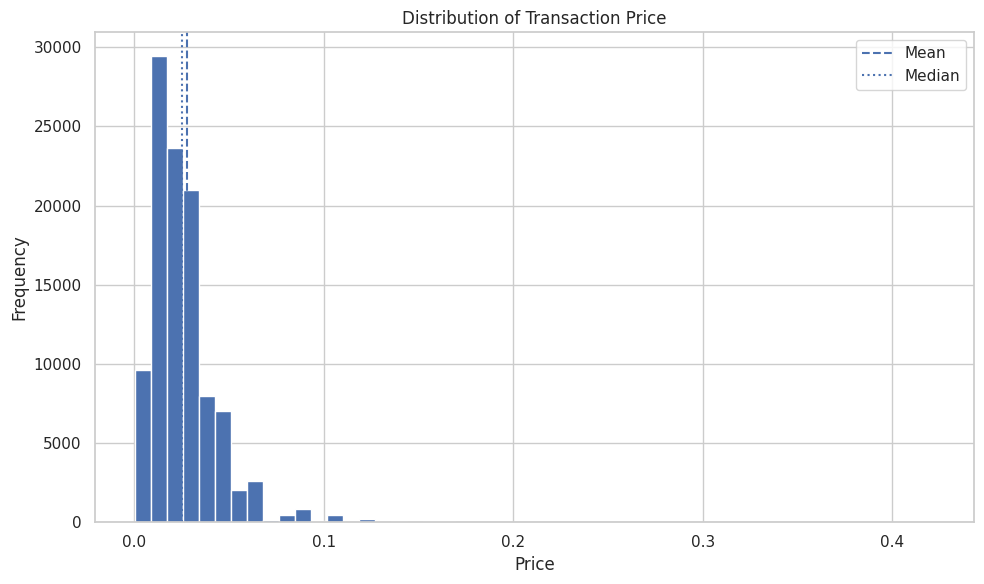

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(
    transactions_df["price"],
    bins=50,
    edgecolor="white"
)

plt.axvline(
    transactions_df["price"].mean(),
    linestyle="--",
    label="Mean"
)

plt.axvline(
    transactions_df["price"].median(),
    linestyle=":",
    label="Median"
)

plt.title("Distribution of Transaction Price")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

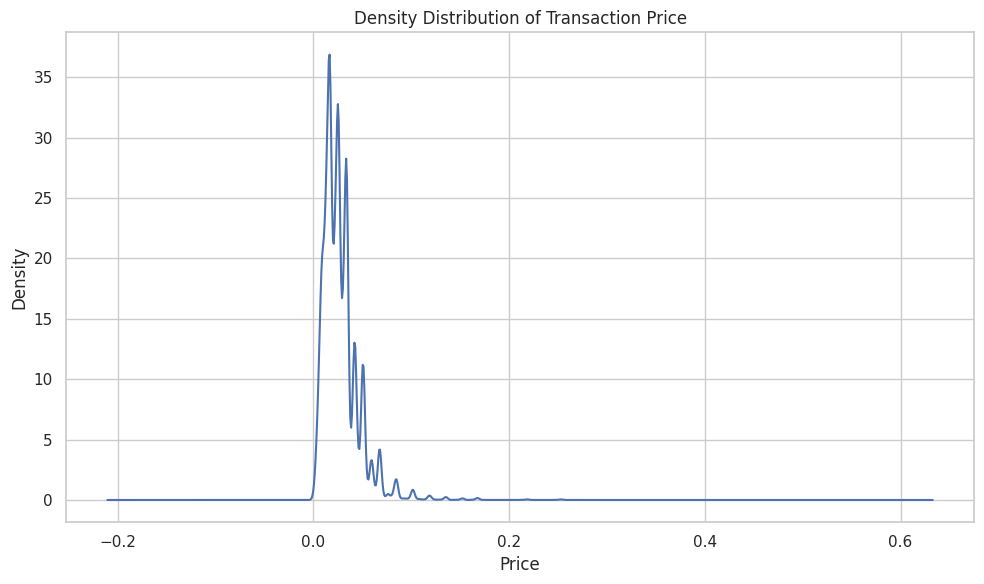

In [ ]:
transactions_df["price"].plot(
    kind="density",
    figsize=(10, 6)
)

plt.title("Density Distribution of Transaction Price")
plt.xlabel("Price")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

the distribution of transaction price was evaluated using skewness and excess kurtosis. The price variable exhibited a skewness of 2.9245 and an excess kurtosis of 20.4221. The positive skewness indicated a right-skewed distribution, with most transactions concentrated at relatively lower price values and a smaller number of observations extending toward higher values. The kurtosis indicated extreme prices. These findings were consistent with the potential high-price observations identified during the IQR-based outlier assessment. Because the extreme observations were not established as data errors, they were retained for subsequent analysis.

CROSS-TABULATION

In [ ]:
print("=" * 70)
print("SALES CHANNEL × PRICE OUTLIER")
print("=" * 70)

channel_outlier_crosstab = pd.crosstab(
    transactions_df["sales_channel_id"],
    transactions_df["price_outlier"],
    margins=True
)

display(channel_outlier_crosstab)

SALES CHANNEL × PRICE OUTLIER


price_outlier,False,True,All
sales_channel_id,,,
1,30608,752,31360
2,70130,4365,74495
All,100738,5117,105855


# CENTRAL TENDENCY AND DISPERSION

In [ ]:

price = transactions_df["price"]

central_dispersion = pd.DataFrame({
    "Mean": [price.mean()],
    "Median": [price.median()],
    "Mode": [price.mode().iloc[0]],
    "Standard_Deviation": [price.std()],
    "Variance": [price.var()],
    "Minimum": [price.min()],
    "Q1": [price.quantile(0.25)],
    "Q3": [price.quantile(0.75)],
    "Maximum": [price.max()],
    "Range": [price.max() - price.min()],
    "IQR": [
        price.quantile(0.75) -
        price.quantile(0.25)
    ]
}, index=["price"])

display(
    central_dispersion.round(6)
)

,Mean,Median,Mode,Standard_Deviation,Variance,Minimum,Q1,Q3,Maximum,Range,IQR
price,0.027811,0.025407,0.016932,0.019069,0.000364,0.000322,0.015847,0.033881,0.422034,0.421712,0.018034


In [ ]:
coefficient_of_variation = (
    price.std() / price.mean()
) * 100

print(
    f"Coefficient of Variation: "
    f"{coefficient_of_variation:.2f}%"
)

Coefficient of Variation: 68.57%


In [ ]:
mean_price = price.mean()
median_price = price.median()

print(f"Mean:   {mean_price:.6f}")
print(f"Median: {median_price:.6f}")

print(
    f"Difference: "
    f"{mean_price - median_price:.6f}"
)

print(
    f"Mean/Median Ratio: "
    f"{mean_price / median_price:.3f}"
)

Mean:   0.027811
Median: 0.025407
Difference: 0.002405
Mean/Median Ratio: 1.095


In [ ]:
price_percentiles = price.quantile(
    [
        0.00,
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
        1.00
    ]
)

price_percentiles.index = [
    "Min",
    "1%",
    "5%",
    "25%",
    "50% (Median)",
    "75%",
    "90%",
    "95%",
    "99%",
    "Max"
]

display(
    price_percentiles
    .to_frame("price")
    .round(6)
)

,price
Min,0.000322
1%,0.003806
5%,0.007610
25%,0.015847
50% (Median),0.025407
75%,0.033881
90%,0.050831
95%,0.059305
99%,0.101678
Max,0.422034


# VISUAL EXPLORATION

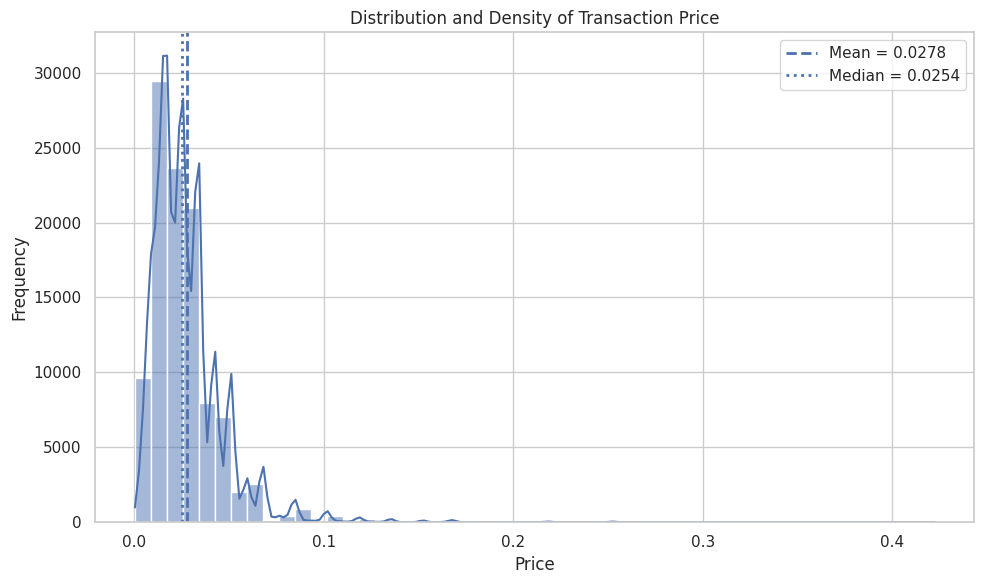

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=transactions_df,
    x="price",
    bins=50,
    kde=True
)

plt.axvline(
    transactions_df["price"].mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean = {transactions_df['price'].mean():.4f}"
)

plt.axvline(
    transactions_df["price"].median(),
    linestyle=":",
    linewidth=2,
    label=f"Median = {transactions_df['price'].median():.4f}"
)

plt.title(
    "Distribution and Density of Transaction Price"
)
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

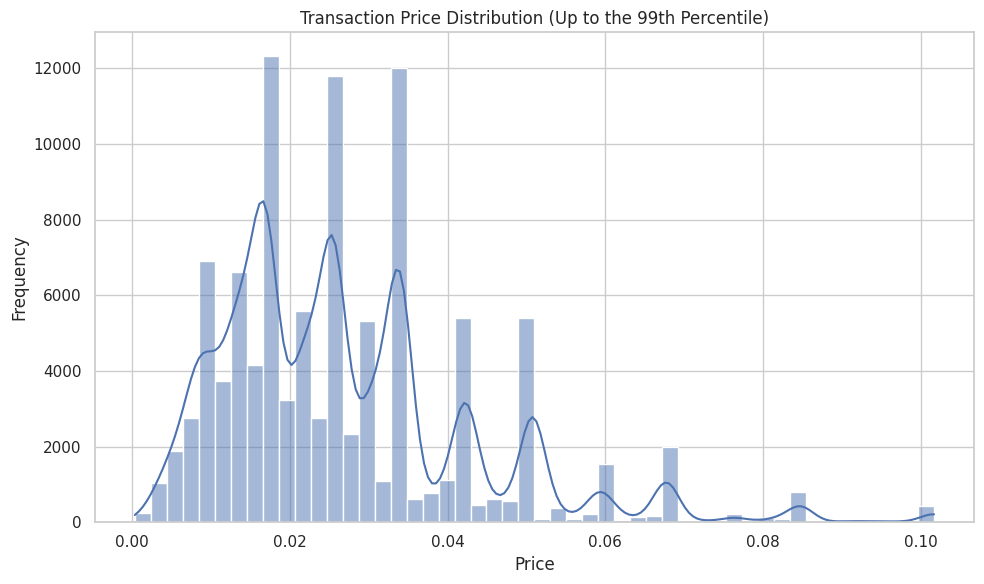

99th percentile price: 0.101678


In [ ]:
price_99 = transactions_df["price"].quantile(0.99)

central_prices = transactions_df[
    transactions_df["price"] <= price_99
]

plt.figure(figsize=(10, 6))

sns.histplot(
    data=central_prices,
    x="price",
    bins=50,
    kde=True
)

plt.title(
    "Transaction Price Distribution "
    "(Up to the 99th Percentile)"
)
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

print(
    f"99th percentile price: {price_99:.6f}"
)

ransaction prices using a histogram and kernel density estimate indicated a positively skewed distribution, with the majority of transactions concentrated within the lower price range and a progressively smaller number of observations extending toward higher prices.

# BOXPLOT

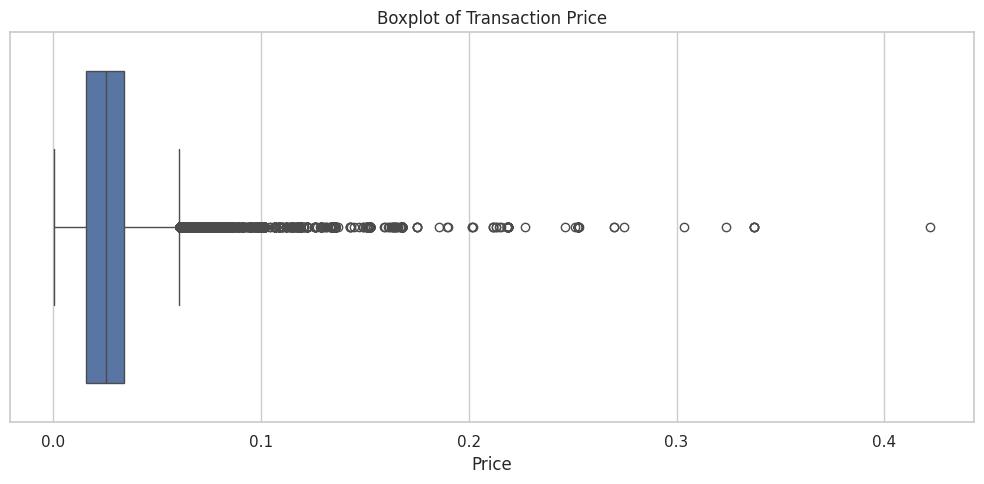

In [ ]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=transactions_df,
    x="price"
)

plt.title("Boxplot of Transaction Price")
plt.xlabel("Price")

plt.tight_layout()
plt.show()

# DISTRIBUTION BASED ON SALE CHANNEL

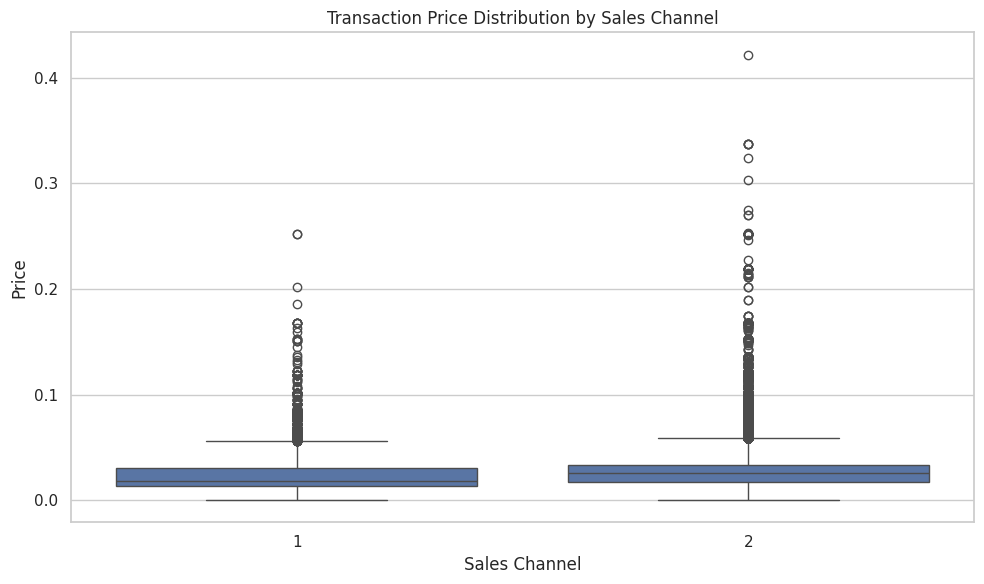

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=transactions_df,
    x="sales_channel_id",
    y="price"
)

plt.title(
    "Transaction Price Distribution by Sales Channel"
)
plt.xlabel("Sales Channel")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

# OUTLIERS SUPPRESSION FOR CENTRAL DISTRIBUTION INSPECTION

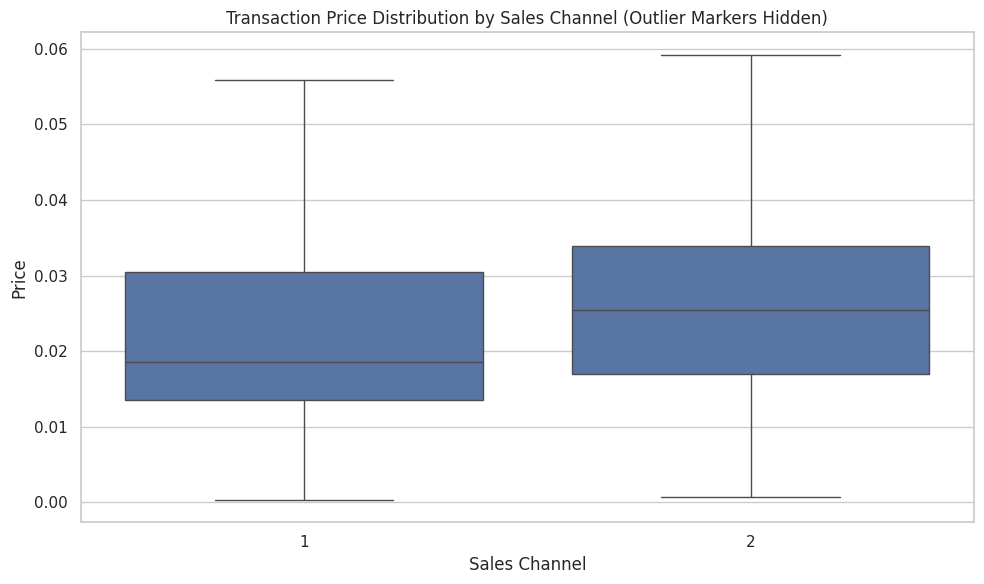

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=transactions_df,
    x="sales_channel_id",
    y="price",
    showfliers=False
)

plt.title(
    "Transaction Price Distribution by Sales Channel "
    "(Outlier Markers Hidden)"
)
plt.xlabel("Sales Channel")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

The overall boxplot confirmed the presence of observations above the upper whisker, consistent with the earlier IQR-based outlier analysis. Price distributions were also compared across the two sales channels to assess differences in median transaction price, interquartile range, dispersion, and extreme observations.

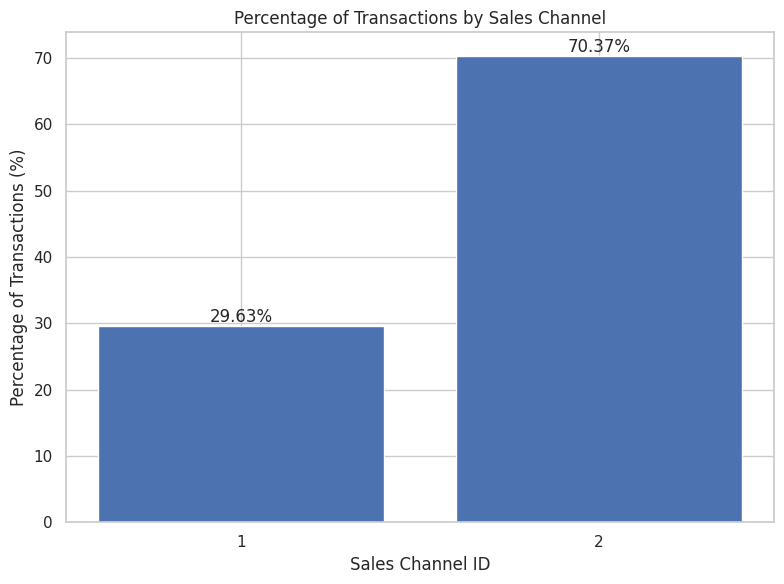

In [ ]:
channel_percent = (
    transactions_df["sales_channel_id"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

plt.figure(figsize=(8, 6))

bars = plt.bar(
    channel_percent.index.astype(str),
    channel_percent.values
)

plt.title("Percentage of Transactions by Sales Channel")
plt.xlabel("Sales Channel ID")
plt.ylabel("Percentage of Transactions (%)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# BIVARIATE VISUAL ANALYSIS

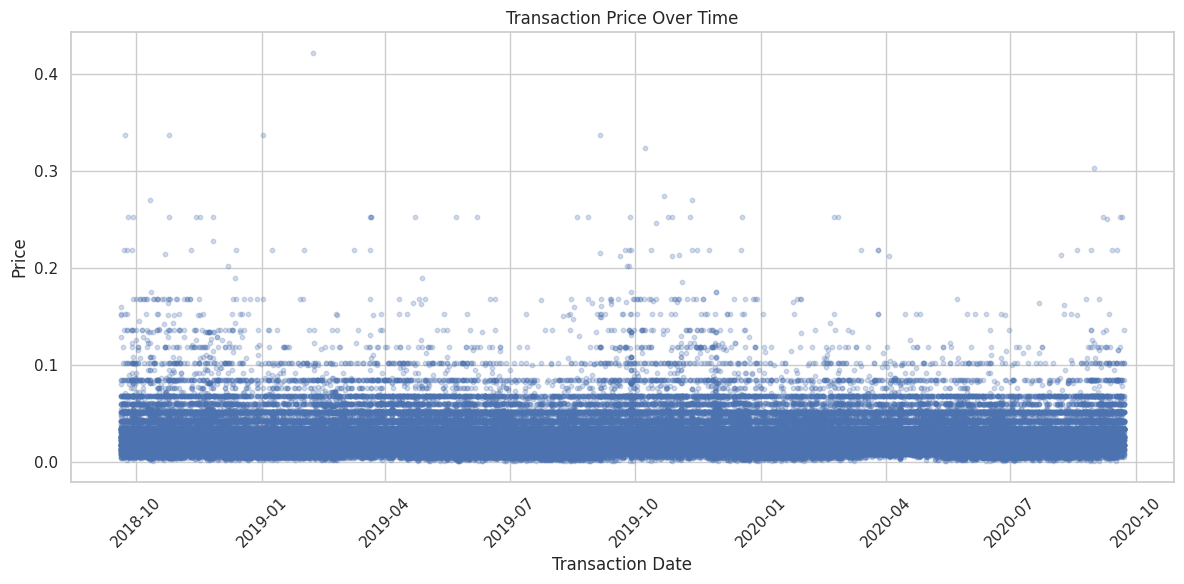

In [ ]:



plt.figure(figsize=(12, 6))

plt.scatter(
    transactions_df["t_dat"],
    transactions_df["price"],
    alpha=0.25,
    s=10
)

plt.title("Transaction Price Over Time")
plt.xlabel("Transaction Date")
plt.ylabel("Price")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
monthly_price = (
    transactions_df
    .set_index("t_dat")
    .resample("ME")["price"]
    .agg(
        mean_price="mean",
        median_price="median",
        transaction_count="count"
    )
    .reset_index()
)

display(monthly_price.head())

,t_dat,mean_price,median_price,transaction_count
0,2018-09-30,0.029916,0.025407,1967
1,2018-10-31,0.030221,0.025407,4674
2,2018-11-30,0.030589,0.025407,4204
3,2018-12-31,0.028359,0.025407,3788
4,2019-01-31,0.026609,0.022017,4106


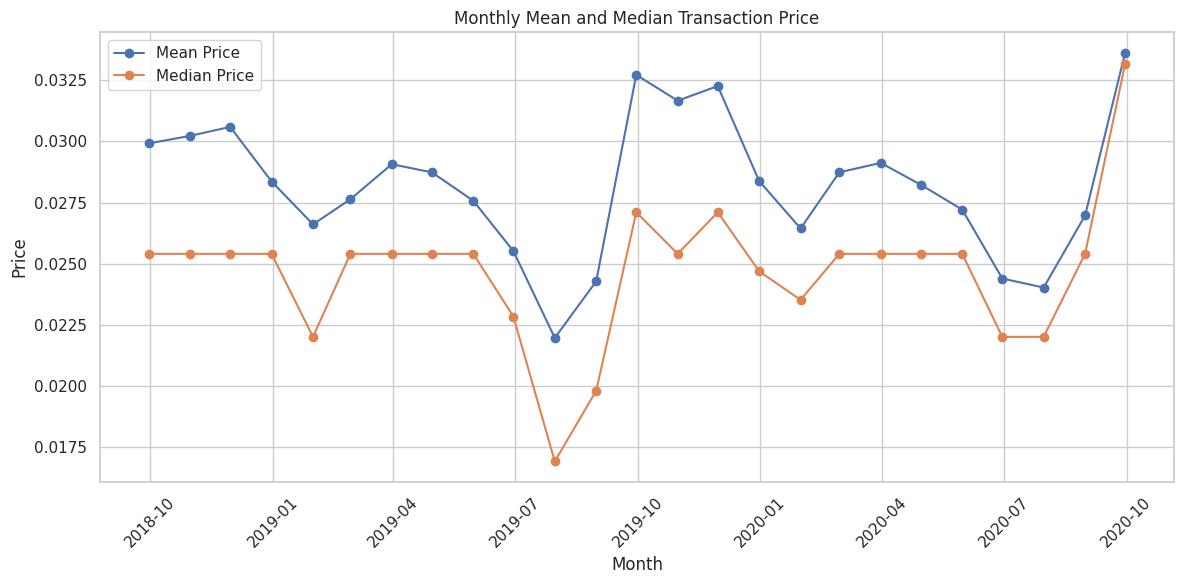

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_price["t_dat"],
    monthly_price["mean_price"],
    marker="o",
    label="Mean Price"
)

plt.plot(
    monthly_price["t_dat"],
    monthly_price["median_price"],
    marker="o",
    label="Median Price"
)

plt.title("Monthly Mean and Median Transaction Price")
plt.xlabel("Month")
plt.ylabel("Price")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# ARTICLE FREQUENCY VS. PRICE

In [ ]:
article_stats = (
    transactions_df
    .groupby(
        "article_id",
        observed=True
    )
    .agg(
        interaction_count=("article_id", "size"),
        mean_price=("price", "mean")
    )
    .reset_index()
)

display(article_stats.head())

,article_id,interaction_count,mean_price
0,108775015,26,0.008132
1,108775044,21,0.008153
2,110065001,5,0.017068
3,110065002,3,0.022017
4,110065011,1,0.015237


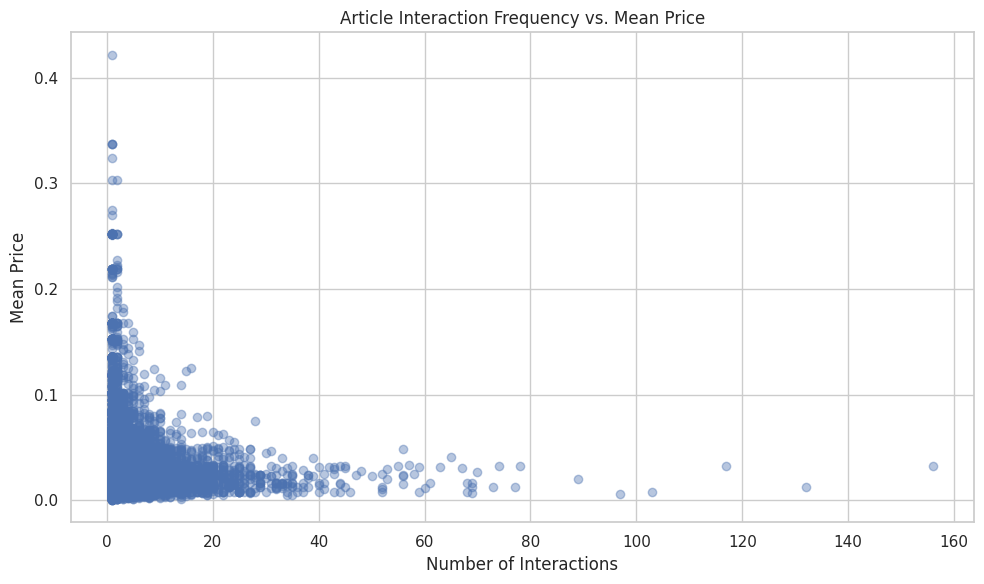

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    article_stats["interaction_count"],
    article_stats["mean_price"],
    alpha=0.4
)

plt.title(
    "Article Interaction Frequency vs. Mean Price"
)
plt.xlabel("Number of Interactions")
plt.ylabel("Mean Price")

plt.tight_layout()
plt.show()

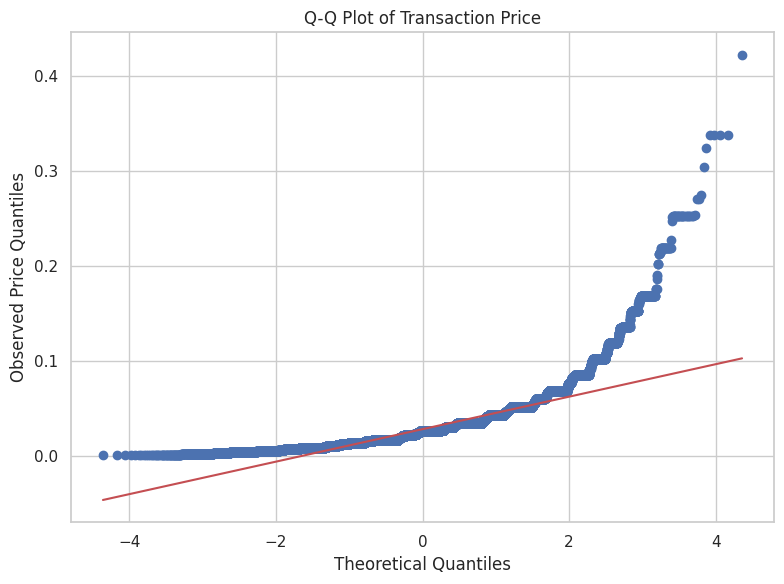

In [ ]:

plt.figure(figsize=(8, 6))

stats.probplot(
    transactions_df["price"].dropna(),
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Transaction Price")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Observed Price Quantiles")

plt.tight_layout()
plt.show()

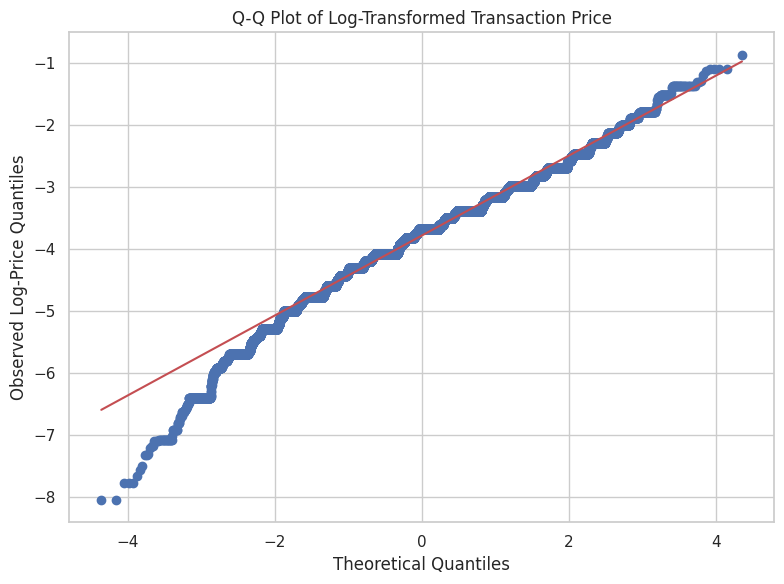

In [ ]:
log_price = np.log(
    transactions_df["price"]
)

plt.figure(figsize=(8, 6))

stats.probplot(
    log_price.dropna(),
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Log-Transformed Transaction Price")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Observed Log-Price Quantiles")

plt.tight_layout()
plt.show()

In [ ]:
normality_comparison = pd.DataFrame({
    "Variable": [
        "Original Price",
        "Log Price"
    ],
    "Skewness": [
        transactions_df["price"].skew(),
        log_price.skew()
    ],
    "Excess Kurtosis": [
        transactions_df["price"].kurt(),
        log_price.kurt()
    ]
})

display(
    normality_comparison.round(4)
)

,Variable,Skewness,Excess Kurtosis
0,Original Price,2.9245,20.4221
1,Log Price,-0.4030,0.9317


The log transformed price reduces the assymetry and deviation from normality.

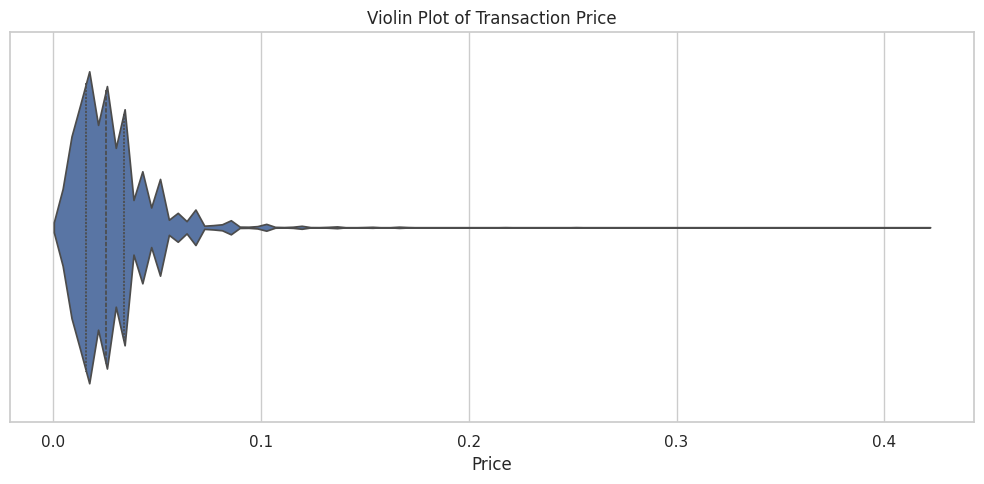

In [ ]:
plt.figure(figsize=(10, 5))

sns.violinplot(
    data=transactions_df,
    x="price",
    inner="quartile",
    cut=0
)

plt.title("Violin Plot of Transaction Price")
plt.xlabel("Price")

plt.tight_layout()
plt.show()

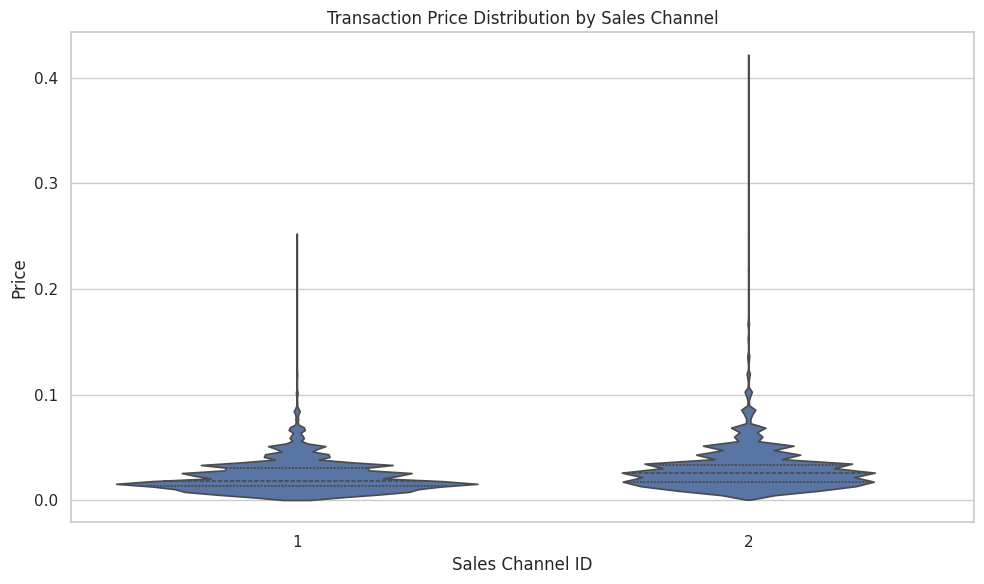

In [ ]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=transactions_df,
    x="sales_channel_id",
    y="price",
    inner="quartile",
    cut=0
)

plt.title(
    "Transaction Price Distribution by Sales Channel"
)
plt.xlabel("Sales Channel ID")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

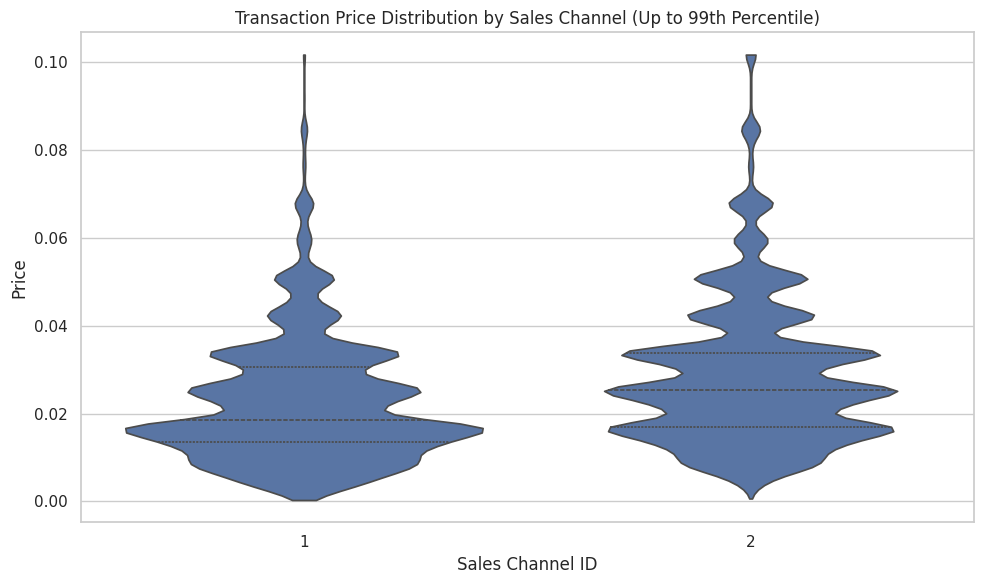

In [ ]:
price_99 = transactions_df["price"].quantile(0.99)

price_99_df = transactions_df[
    transactions_df["price"] <= price_99
]

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=price_99_df,
    x="sales_channel_id",
    y="price",
    inner="quartile",
    cut=0
)

plt.title(
    "Transaction Price Distribution by Sales Channel "
    "(Up to 99th Percentile)"
)
plt.xlabel("Sales Channel ID")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

# CORRELATION AND RELATIONSHIPS

In [ ]:

article_relationships = (
    transactions_df
    .groupby(
        "article_id",
        observed=True
    )
    .agg(
        interaction_count=("article_id", "size"),
        unique_customers=("customer_id", "nunique"),
        mean_price=("price", "mean"),
        median_price=("price", "median"),
        price_std=("price", "std")
    )
    .reset_index()
)

display(article_relationships.head())

,article_id,interaction_count,unique_customers,mean_price,median_price,price_std
0,108775015,26,26,0.008132,0.008458,0.000591
1,108775044,21,21,0.008153,0.008458,0.000613
2,110065001,5,5,0.017068,0.020322,0.008450
3,110065002,3,3,0.022017,0.025407,0.005871
4,110065011,1,1,0.015237,0.015237,NaN


In [ ]:
numeric_cols = [
    "interaction_count",
    "unique_customers",
    "mean_price",
    "median_price",
    "price_std"
]

correlation_matrix = (
    article_relationships[numeric_cols]
    .corr(method="pearson")
)

display(
    correlation_matrix.round(3)
)

,interaction_count,unique_customers,mean_price,median_price,price_std
interaction_count,1.000,1.000,-0.067,-0.054,-0.031
unique_customers,1.000,1.000,-0.066,-0.054,-0.031
mean_price,-0.067,-0.066,1.000,0.997,0.336
median_price,-0.054,-0.054,0.997,1.000,0.340
price_std,-0.031,-0.031,0.336,0.340,1.000


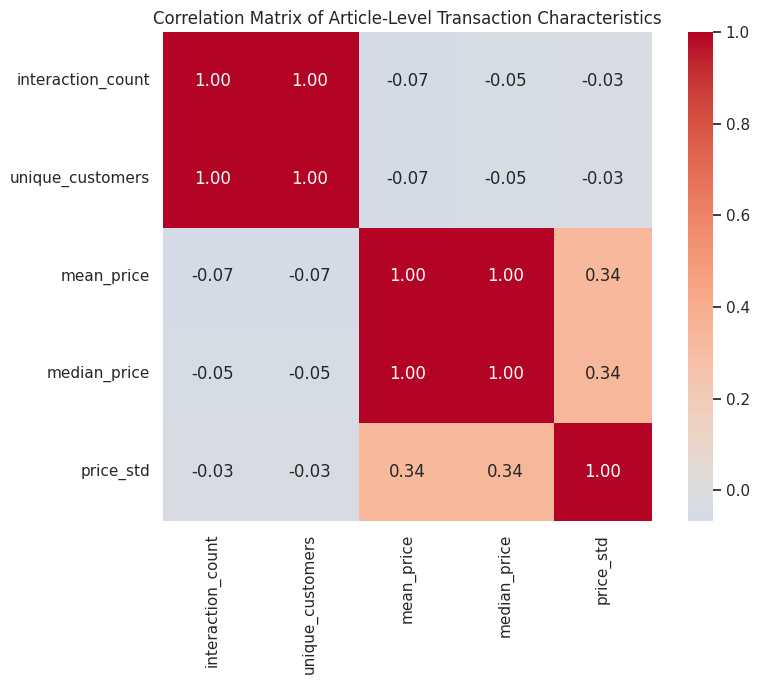

In [ ]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title(
    "Correlation Matrix of Article-Level Transaction Characteristics"
)

plt.tight_layout()
plt.show()

In [ ]:
popularity_price_corr = (
    article_relationships[
        ["interaction_count", "mean_price"]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    "Correlation between article interaction "
    "frequency and mean price:"
)

print(
    f"r = {popularity_price_corr:.4f}"
)

Correlation between article interaction frequency and mean price:
r = -0.0665


# PEARSON CORRELATION

In [ ]:
pearson_corr = (
    article_relationships[
        ["interaction_count", "mean_price"]
    ]
    .corr(method="pearson")
    .iloc[0, 1]
)

spearman_corr = (
    article_relationships[
        ["interaction_count", "mean_price"]
    ]
    .corr(method="spearman")
    .iloc[0, 1]
)

print(
    f"Pearson correlation:  {pearson_corr:.4f}"
)

print(
    f"Spearman correlation: {spearman_corr:.4f}"
)

Pearson correlation:  -0.0665
Spearman correlation: -0.0121


In [ ]:

grouped_summary = (
    transactions_df
    .groupby("sales_channel_id", observed=True)
    .agg(
        transaction_count=("price", "count"),
        mean_price=("price", "mean"),
        median_price=("price", "median"),
        std_price=("price", "std"),
        min_price=("price", "min"),
        max_price=("price", "max")
    )
    .reset_index()
)

display(
    grouped_summary.round(6)
)

,sales_channel_id,transaction_count,mean_price,median_price,std_price,min_price,max_price
0,1,31360,0.022827,0.018627,0.015153,0.000322,0.252542
1,2,74495,0.029910,0.025407,0.020130,0.000661,0.422034


In [ ]:
quartile_summary = (
    transactions_df
    .groupby(
        "sales_channel_id",
        observed=True
    )["price"]
    .agg(
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

quartile_summary["IQR"] = (
    quartile_summary["Q3"] -
    quartile_summary["Q1"]
)

display(
    quartile_summary.round(6)
)

,sales_channel_id,Q1,Q3,IQR
0,1,0.013542,0.030492,0.016949
1,2,0.016932,0.033881,0.016949


In [ ]:
grouped_summary_complete = (
    grouped_summary
    .merge(
        quartile_summary,
        on="sales_channel_id"
    )
)

display(
    grouped_summary_complete.round(6)
)

,sales_channel_id,transaction_count,mean_price,median_price,std_price,min_price,max_price,Q1,Q3,IQR
0,1,31360,0.022827,0.018627,0.015153,0.000322,0.252542,0.013542,0.030492,0.016949
1,2,74495,0.029910,0.025407,0.020130,0.000661,0.422034,0.016932,0.033881,0.016949


In [ ]:
grouped_summary_complete[
    "transaction_percentage"
] = (
    grouped_summary_complete[
        "transaction_count"
    ]
    / len(transactions_df)
    * 100
)

display(
    grouped_summary_complete.round(4)
)

,sales_channel_id,transaction_count,mean_price,median_price,std_price,min_price,max_price,Q1,Q3,IQR,transaction_percentage
0,1,31360,0.0228,0.0186,0.0152,0.0003,0.2525,0.0135,0.0305,0.0169,29.6254
1,2,74495,0.0299,0.0254,0.0201,0.0007,0.4220,0.0169,0.0339,0.0169,70.3746


In [ ]:
outlier_summary = (
    transactions_df
    .groupby(
        "sales_channel_id",
        observed=True
    )
    .agg(
        total_transactions=("price", "size"),
        price_outliers=("price_outlier", "sum")
    )
    .reset_index()
)

outlier_summary["outlier_percentage"] = (
    outlier_summary["price_outliers"]
    / outlier_summary["total_transactions"]
    * 100
)

display(
    outlier_summary.round(2)
)

,sales_channel_id,total_transactions,price_outliers,outlier_percentage
0,1,31360,752,2.40
1,2,74495,4365,5.86


# TARGET VARIABLE ANALYSIS

In [ ]:

item_interactions = (
    transactions_df["article_id"]
    .value_counts()
    .rename_axis("article_id")
    .reset_index(name="interaction_count")
)

display(item_interactions.head(10))

,article_id,interaction_count
0,706016001,156
1,372860001,132
2,706016002,117
3,610776002,103
4,759871002,97
5,351484002,89
6,706016003,78
7,372860002,77
8,751471001,74
9,673396002,73


Here is the top 10 interactions count aND ARTICLE_ID

In [ ]:
display(
    item_interactions["interaction_count"]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

,interaction_count
count,35631.0
mean,2.970868
std,4.181551
min,1.0
25%,1.0
50%,2.0
75%,3.0
90%,6.0
95%,9.0
99%,19.0


# INTERACTION DISTRIBUTION

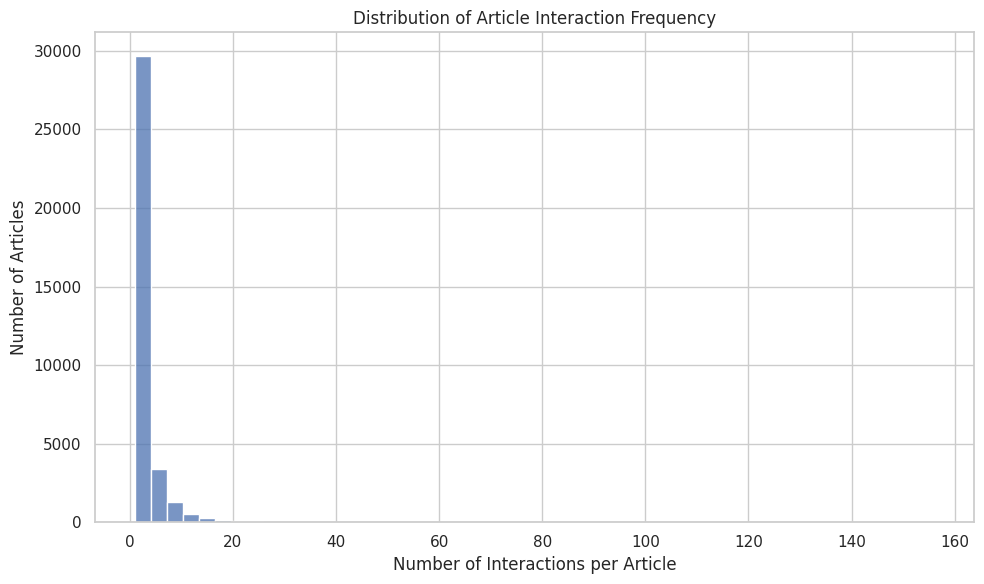

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=item_interactions,
    x="interaction_count",
    bins=50
)

plt.title(
    "Distribution of Article Interaction Frequency"
)
plt.xlabel(
    "Number of Interactions per Article"
)
plt.ylabel(
    "Number of Articles"
)

plt.tight_layout()
plt.show()

# LOW INTERACTION ITEMS

In [ ]:
interaction_distribution = (
    item_interactions["interaction_count"]
    .value_counts()
    .sort_index()
    .rename_axis("interactions")
    .reset_index(name="number_of_articles")
)

interaction_distribution[
    "article_percentage"
] = (
    interaction_distribution[
        "number_of_articles"
    ]
    / len(item_interactions)
    * 100
)

display(
    interaction_distribution.head(20)
)

,interactions,number_of_articles,article_percentage
0,1,16178,45.404283
1,2,7157,20.086442
2,3,3920,11.001656
3,4,2434,6.83113
4,5,1601,4.493278
5,6,1118,3.137717
6,7,693,1.944936
7,8,545,1.529567
8,9,414,1.16191
9,10,320,0.898094


# FEATURE ENGINEERING

In [ ]:
# create new features from the t_dat
transactions_df["year"] = transactions_df["t_dat"].dt.year
transactions_df["month"] = transactions_df["t_dat"].dt.month
transactions_df["weekday"] = transactions_df["t_dat"].dt.dayofweek
transactions_df["weekday_name"] = transactions_df["t_dat"].dt.day_name()
transactions_df["day"] = transactions_df["t_dat"].dt.day
transactions_df["week_of_year"] = (
    transactions_df["t_dat"].dt.isocalendar().week.astype(int)
)

display(
    transactions_df[
        [
            "t_dat",
            "year",
            "month",
            "weekday",
            "weekday_name",
            "week_of_year"
        ]
    ].head()
)

,t_dat,year,month,weekday,weekday_name,week_of_year
0,2019-09-13,2019,9,4,Friday,37
1,2019-02-23,2019,2,5,Saturday,8
2,2019-07-17,2019,7,2,Wednesday,29
3,2019-05-16,2019,5,3,Thursday,20
4,2019-08-10,2019,8,5,Saturday,32


In [ ]:
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Fall"


transactions_df["season"] = (
    transactions_df["month"]
    .apply(get_season)
    .astype("category")
)

In [ ]:
display(
    transactions_df[
        ["t_dat", "month", "season"]
    ].head(10)
)

print(
    transactions_df["season"]
    .value_counts()
)

,t_dat,month,season
0,2019-09-13,9,Fall
1,2019-02-23,2,Winter
2,2019-07-17,7,Summer
3,2019-05-16,5,Spring
4,2019-08-10,8,Summer
5,2019-11-04,11,Fall
6,2019-06-23,6,Summer
7,2020-05-22,5,Spring
8,2019-03-17,3,Spring
9,2020-07-22,7,Summer


season
Summer    30728
Spring    27160
Fall      25337
Winter    22630
Name: count, dtype: int64


We created seasonal calendar-based features

In [ ]:
# Created binary is_weekend (0/1) features
# 0 = weekday
# 1 = weekend

transactions_df["is_weekend"] = (
    transactions_df["weekday"] >= 5
).astype(int)

transactions_df[
    ["t_dat", "weekday_name", "is_weekend"]
].head()

,t_dat,weekday_name,is_weekend
0,2019-09-13,Friday,0
1,2019-02-23,Saturday,1
2,2019-07-17,Wednesday,0
3,2019-05-16,Thursday,0
4,2019-08-10,Saturday,1


These features are useful for descriptive temporal exploration

# FINAL CHECK

## MISSING VALUES

In [ ]:
missing_final = pd.DataFrame({
    "missing_count": transactions_df.isna().sum(),
    "missing_percentage": (
        transactions_df.isna().mean() * 100
    ).round(4)
})

display(missing_final)

,missing_count,missing_percentage
t_dat,0,0.0
customer_id,0,0.0
article_id,0,0.0
price,0,0.0
sales_channel_id,0,0.0
price_outlier,0,0.0
year,0,0.0
month,0,0.0
weekday,0,0.0
weekday_name,0,0.0


In [ ]:
total_missing = transactions_df.isna().sum().sum()

print(
    f"Total missing values in prepared dataset: "
    f"{total_missing:,}"
)

Total missing values in prepared dataset: 0


In [ ]:
modeling_columns = [
    "t_dat",
    "customer_id",
    "article_id",
    "price",
    "sales_channel_id"
]

transactions_df[
    modeling_columns
].isna().sum()

,0
t_dat,0
customer_id,0
article_id,0
price,0
sales_channel_id,0


Following data cleaning, exploratory analysis, and feature engineering, the prepared transaction dataset was reevaluated for missing values. Missing-value counts and percentages were calculated for all retained variables. No missing observations were identified in the prepared transaction data; therefore, no additional deletion or imputation was required at this stage. Missingness and coverage of the associated article metadata, product images, and subsequently generated multimodal representations were evaluated separately before construction of the final modeling dataset.

## DATA TYPES VALIDATION

In [ ]:

print("Dataset shape:", transactions_df.shape)

print("\nData types:")
print(transactions_df.dtypes)

print("\nDataset information:")
transactions_df.info()

Dataset shape: (105855, 14)

Data types:
t_dat               datetime64[ns]
customer_id         string[python]
article_id          string[python]
price                      float64
sales_channel_id          category
price_outlier                 bool
year                         int32
month                        int32
weekday                      int32
weekday_name                object
day                          int32
week_of_year                 int64
season                    category
is_weekend                   int64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105855 entries, 0 to 105854
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   t_dat             105855 non-null  datetime64[ns]
 1   customer_id       105855 non-null  string        
 2   article_id        105855 non-null  string        
 3   price             105855 non-null  float64

In [ ]:
print(
    "Invalid dates:",
    transactions_df["t_dat"].isna().sum()
)

print(
    "Earliest date:",
    transactions_df["t_dat"].min()
)

print(
    "Latest date:",
    transactions_df["t_dat"].max()
)

print(
    "Unique dates:",
    transactions_df["t_dat"].nunique()
)

Invalid dates: 0
Earliest date: 2018-09-20 00:00:00
Latest date: 2020-09-22 00:00:00
Unique dates: 734


THERE ARE 734 UNIQUE DATES

In [ ]:
print(
    "Customer ID dtype:",
    transactions_df["customer_id"].dtype
)

print(
    "Article ID dtype:",
    transactions_df["article_id"].dtype
)

print(
    "Unique customers:",
    transactions_df["customer_id"].nunique()
)

print(
    "Unique articles:",
    transactions_df["article_id"].nunique()
)

Customer ID dtype: string
Article ID dtype: string
Unique customers: 92879
Unique articles: 35631


In [ ]:
print(
    "Customer ID length:"
)

print(
    transactions_df["customer_id"]
    .str.len()
    .value_counts()
    .sort_index()
)

print("\nArticle ID length:")

print(
    transactions_df["article_id"]
    .str.len()
    .value_counts()
    .sort_index()
)

Customer ID length:
customer_id
64    105855
Name: count, dtype: Int64

Article ID length:
article_id
9    105855
Name: count, dtype: Int64


VALIDATE NUMERIC PRICE

In [ ]:

print(
    "Non-numeric / missing price:",
    transactions_df["price"].isna().sum()
)

print(
    "Infinite price:",
    np.isinf(transactions_df["price"]).sum()
)

print(
    "Zero price:",
    (transactions_df["price"] == 0).sum()
)

print(
    "Negative price:",
    (transactions_df["price"] < 0).sum()
)

Non-numeric / missing price: 0
Infinite price: 0
Zero price: 0
Negative price: 0


VALIDATE CATEGORICAL VALUES

In [ ]:
print(
    transactions_df["sales_channel_id"]
    .value_counts(dropna=False)
    .sort_index()
)

sales_channel_id
1    31360
2    74495
Name: count, dtype: int64


In [ ]:
print(
    transactions_df["season"]
    .value_counts(dropna=False)
)

season
Summer    30728
Spring    27160
Fall      25337
Winter    22630
Name: count, dtype: int64


In [ ]:
print(
    transactions_df["is_weekend"]
    .value_counts(dropna=False)
    .sort_index()
)

is_weekend
0    75499
1    30356
Name: count, dtype: int64


In [ ]:
# ----------------------------------------------------------
# CONSOLIDATED DATA VALIDATION
# ----------------------------------------------------------

validation_results = {
    "Rows": len(transactions_df),
    "Columns": transactions_df.shape[1],

    "Missing_Values":
        transactions_df.isna().sum().sum(),

    "Invalid_Dates":
        transactions_df["t_dat"].isna().sum(),

    "Unique_Customers":
        transactions_df["customer_id"].nunique(),

    "Unique_Articles":
        transactions_df["article_id"].nunique(),

    "Negative_Prices":
        (transactions_df["price"] < 0).sum(),

    "Zero_Prices":
        (transactions_df["price"] == 0).sum(),

    "Sales_Channels":
        transactions_df["sales_channel_id"].nunique(),

    "Earliest_Date":
        transactions_df["t_dat"].min(),

    "Latest_Date":
        transactions_df["t_dat"].max()
}

validation_df = pd.DataFrame(
    validation_results.items(),
    columns=["Validation_Check", "Result"]
)

display(validation_df)

,Validation_Check,Result
0,Rows,105855
1,Columns,14
2,Missing_Values,0
3,Invalid_Dates,0
4,Unique_Customers,92879
5,Unique_Articles,35631
6,Negative_Prices,0
7,Zero_Prices,0
8,Sales_Channels,2
9,Earliest_Date,2018-09-20 00:00:00


TEMPORAL TRAINING/VALIDATION/TESTING SPLIT

In [ ]:

transactions_df = (
    transactions_df
    .sort_values("t_dat")
    .reset_index(drop=True)
)

print(
    "Earliest transaction:",
    transactions_df["t_dat"].min()
)

print(
    "Latest transaction:",
    transactions_df["t_dat"].max()
)

print(
    "Total transactions:",
    len(transactions_df)
)

Earliest transaction: 2018-09-20 00:00:00
Latest transaction: 2020-09-22 00:00:00
Total transactions: 105855


In [ ]:
# Get sorted unique transaction dates
unique_dates = (
    transactions_df["t_dat"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

n_dates = len(unique_dates)

train_end_idx = int(n_dates * 0.80)
val_end_idx = int(n_dates * 0.90)

train_end_date = unique_dates.iloc[
    train_end_idx - 1
]

val_end_date = unique_dates.iloc[
    val_end_idx - 1
]

print(
    "Number of unique dates:",
    n_dates
)

print(
    "Training end date:",
    train_end_date
)

print(
    "Validation end date:",
    val_end_date
)

print(
    "Dataset end date:",
    unique_dates.iloc[-1]
)

Number of unique dates: 734
Training end date: 2020-04-28 00:00:00
Validation end date: 2020-07-10 00:00:00
Dataset end date: 2020-09-22 00:00:00


In [ ]:
train_df = transactions_df[
    transactions_df["t_dat"] <= train_end_date
].copy()

val_df = transactions_df[
    (transactions_df["t_dat"] > train_end_date) &
    (transactions_df["t_dat"] <= val_end_date)
].copy()

test_df = transactions_df[
    transactions_df["t_dat"] > val_end_date
].copy()

In [ ]:
split_summary = pd.DataFrame({
    "Split": [
        "Training",
        "Validation",
        "Testing"
    ],

    "Transactions": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],

    "Start_Date": [
        train_df["t_dat"].min(),
        val_df["t_dat"].min(),
        test_df["t_dat"].min()
    ],

    "End_Date": [
        train_df["t_dat"].max(),
        val_df["t_dat"].max(),
        test_df["t_dat"].max()
    ],

    "Unique_Customers": [
        train_df["customer_id"].nunique(),
        val_df["customer_id"].nunique(),
        test_df["customer_id"].nunique()
    ],

    "Unique_Articles": [
        train_df["article_id"].nunique(),
        val_df["article_id"].nunique(),
        test_df["article_id"].nunique()
    ]
})

split_summary["Percentage"] = (
    split_summary["Transactions"]
    / len(transactions_df)
    * 100
)

display(split_summary)

,Split,Transactions,Start_Date,End_Date,Unique_Customers,Unique_Articles,Percentage
0,Training,83950,2018-09-20,2020-04-28,75034,29714,79.306599
1,Validation,12237,2020-04-29,2020-07-10,11901,6297,11.560153
2,Testing,9668,2020-07-11,2020-09-22,9430,5669,9.133248


CHECKING FOR TEMPORAL OVERLAP

In [ ]:
print(
    "Train ends:",
    train_df["t_dat"].max()
)

print(
    "Validation starts:",
    val_df["t_dat"].min()
)

print(
    "Validation ends:",
    val_df["t_dat"].max()
)

print(
    "Test starts:",
    test_df["t_dat"].min()
)

assert (
    train_df["t_dat"].max()
    <
    val_df["t_dat"].min()
)

assert (
    val_df["t_dat"].max()
    <
    test_df["t_dat"].min()
)

print(
    "\nTemporal separation verified."
)

Train ends: 2020-04-28 00:00:00
Validation starts: 2020-04-29 00:00:00
Validation ends: 2020-07-10 00:00:00
Test starts: 2020-07-11 00:00:00

Temporal separation verified.


IDENTIFY ITEM COLD-START STATUS

In [ ]:
train_items = set(
    train_df["article_id"].unique()
)

val_items = set(
    val_df["article_id"].unique()
)

test_items = set(
    test_df["article_id"].unique()
)

In [ ]:
val_cold_items = (
    val_items - train_items
)

print(
    "Validation articles:",
    len(val_items)
)

print(
    "Cold-start validation articles:",
    len(val_cold_items)
)

print(
    "Cold-start percentage:",
    round(
        len(val_cold_items)
        / len(val_items)
        * 100,
        2
    )
)

Validation articles: 6297
Cold-start validation articles: 3088
Cold-start percentage: 49.04


ADDING COLD-START LABELS

In [ ]:
# UNSEEN DURING TRAINING
test_cold_vs_train = (
    test_items - train_items
)

print(
    "Test items unseen during training:",
    len(test_cold_vs_train)
)


Test items unseen during training: 3748


In [ ]:
# UNSEEN BEFORE TEST PERIOD
known_before_test = (
    train_items | val_items
)

strict_test_cold_items = (
    test_items - known_before_test
)

print(
    "Strict test cold-start articles:",
    len(strict_test_cold_items)
)

Strict test cold-start articles: 2829


In [ ]:
val_df["item_status"] = (
    val_df["article_id"]
    .apply(
        lambda x:
        "Cold-Start"
        if x not in train_items
        else "Warm"
    )
)

In [ ]:
test_df["item_status"] = (
    test_df["article_id"]
    .apply(
        lambda x:
        "Cold-Start"
        if x not in known_before_test
        else "Warm"
    )
)

In [ ]:
print(
    "VALIDATION"
)

display(
    val_df["item_status"]
    .value_counts()
    .to_frame("Transactions")
)

print(
    "\nTEST"
)

display(
    test_df["item_status"]
    .value_counts()
    .to_frame("Transactions")
)

VALIDATION


,Transactions
item_status,
Warm,6959
Cold-Start,5278



TEST


,Transactions
item_status,
Warm,5088
Cold-Start,4580


In [ ]:
train_item_counts = (
    train_df
    .groupby("article_id")
    .size()
    .rename("train_interactions")
    .reset_index()
)

display(
    train_item_counts[
        "train_interactions"
    ].describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

,train_interactions
count,29714.000000
mean,2.825268
std,3.807561
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
90%,6.000000
95%,8.000000
99%,17.000000


In [ ]:
train_frequency_distribution = (
    train_item_counts[
        "train_interactions"
    ]
    .value_counts()
    .sort_index()
    .rename_axis(
        "training_interactions"
    )
    .reset_index(
        name="number_of_articles"
    )
)

display(
    train_frequency_distribution.head(20)
)

,training_interactions,number_of_articles
0,1,13942
1,2,5987
2,3,3194
3,4,2006
4,5,1268
5,6,884
6,7,573
7,8,405
8,9,314
9,10,224


# SAVE

In [ ]:
train_df.to_csv(
    "hm_train_temporal.csv",
    index=False
)

val_df.to_csv(
    "hm_validation_temporal.csv",
    index=False
)

test_df.to_csv(
    "hm_test_temporal.csv",
    index=False
)